# Advanced RAG: индексы векторного поиска


### Короткий словарь

Английские имена методов и параметров сохраняем как в API. В пояснениях используем следующие значения:

| Термин | Значение в этом ноутбуке |
|---|---|
| ANN / exact | Приближённый поиск / точный перебор. Точный поиск служит эталоном ANN recall. |
| `label`, ID | Идентификатор документа. В hnswlib он называется `label` и может отличаться от номера строки матрицы. |
| `lookup` | Поиск ближайших документов; далее пишем «поиск». |
| `online` / `offline` | Обработка текущих запросов / предварительная подготовка и оценка вне обработки запросов. |
| Встроенный фильтр (`native filter`) | Условие применяется внутри поиска. Постфильтр отбирает документы из уже полученной выдачи. |
| `fetch_k`, oversampling | Число запрошенных кандидатов до постфильтра; oversampling — получение более широкого пула, чем итоговые `k` документов. |
| Контрольные запросы (`holdout`) | Запросы, отложенные от подбора параметров для проверки выбранной настройки. Независимость итогового теста требует отдельного протокола. |
| MIPS | Maximum inner product search — поиск максимального скалярного произведения. |
| Фабрика индексов (`factory`) | Сборка индекса по строке конфигурации, например через `faiss.index_factory`. |
| Функция обратного вызова (`callback`) | Функция приложения, которую вызывает библиотека. Например, функция фильтра решает, разрешён ли ID. |
| `thread-safety` | Безопасность одновременных операций из разных потоков; проверяется для конкретной пары операций. |
| `DirectMap` | Карта FAISS из ID документа в номер IVF-списка и позицию записи внутри него. |
| Пакет (`batch`), latency / throughput | Пакет запросов; задержка отдельного запроса / число обработанных запросов за секунду. |
| `size MiB`, RSS | Здесь `size MiB` — размер файла индекса; RSS — объём резидентной памяти процесса. Это разные показатели. |

ANN recall и qrels recall подробно разбираются сразу после построения точного эталона. Они используют разные основания для сравнения: точных соседей и разметку релевантности соответственно.

In [1]:
from pathlib import Path
from time import perf_counter
import json

import annoy
import faiss
import hnswlib
import numpy as np

# Фиксируем глобальный NumPy RNG для воспроизводимых вспомогательных примеров.
SEED = 42
np.random.seed(SEED)
np.set_printoptions(precision=3, suppress=True)

# Сохраняем индексы и связанные файлы в каталоге семинара.
INDEX_DIR = Path("indexes")
INDEX_DIR.mkdir(exist_ok=True)

print("faiss:", faiss.__version__)
print("numpy:", np.__version__)


faiss: 1.15.1
numpy: 2.4.6


## 1. Загружаем реальные эмбеддинги SciFact

Предварительный ноутбук сохранил корпус, тестовые запросы, qrels и матрицы эмбеддингов в `data/embeddings`. Здесь выбираем одну из уже рассчитанных моделей. По умолчанию используем `bge-small-en-v1.5`: это англоязычная retrieval-модель, хорошо подходящая к научному SciFact. Вспомогательный ноутбук также сохранил multilingual-модели для MKQA.

Чтобы сравнить другую модель, достаточно изменить `MODEL_SLUG` и повторно выполнить ячейки загрузки и индексов. Само кодирование при этом не запускается.


In [2]:
# Ноутбук запускается из каталога 05-rag-advanced.
SEMINAR_DIR = Path.cwd()

ARTIFACT_DIR = SEMINAR_DIR / "data" / "embeddings"
DATASET_SLUG = "scifact"
MODEL_SLUG = "bge_small_en_v1_5"
DATASET_DIR = ARTIFACT_DIR / DATASET_SLUG
MODEL_DIR = DATASET_DIR / MODEL_SLUG

with (DATASET_DIR / "corpus.jsonl").open(encoding="utf-8") as stream:
    corpus_rows = [json.loads(line) for line in stream]
with (DATASET_DIR / "queries_test.jsonl").open(encoding="utf-8") as stream:
    query_rows = [json.loads(line) for line in stream]
qrels = json.loads((DATASET_DIR / "qrels_test.json").read_text(encoding="utf-8"))

docs = np.load(MODEL_DIR / "docs.npy").astype("float32", copy=False)
queries = np.load(MODEL_DIR / "queries.npy").astype("float32", copy=False)
model_metadata = json.loads((MODEL_DIR / "metadata.json").read_text(encoding="utf-8"))

DIM = int(docs.shape[1])
TOP_K = 10
# Эти параметры нужны только для маленьких демонстраций фильтрации и обновления.
# Они не описывают семантические кластеры: в SciFact нет искусственной кластеризации.
RANGE_LIMIT = min(1000, len(docs) - 1)

doc_ids = [str(row["_id"]) for row in corpus_rows]
query_ids = [str(row["_id"]) for row in query_rows]
doc_id_to_position = {doc_id: pos for pos, doc_id in enumerate(doc_ids)}
# Tenant — отдельный клиент или изолированное пространство данных.
# В реальной системе tenant-фильтр не даёт одному клиенту видеть документы другого.
# В SciFact такого поля нет, поэтому для демонстрации фильтрации создаём
# четыре искусственных tenant-бакета.
doc_bucket = np.arange(len(docs), dtype="int64") % 4
query_bucket = np.arange(len(queries), dtype="int64") % 4

print("dataset:", DATASET_SLUG)
print("embedding model:", model_metadata["model_name"])
print("documents:", len(docs))
print("test queries:", len(queries))
print("dimension:", DIM)
print("vectors memory:", round(docs.nbytes / 1024**2, 2), "MiB")
print("first query:", query_rows[0]["text"])


dataset: scifact
embedding model: BAAI/bge-small-en-v1.5
documents: 5183
test queries: 1109
dimension: 384
vectors memory: 7.59 MiB
first query: 0-dimensional biomaterials lack inductive properties.


Документы и запросы уже нормализованы в offline-процессе. Поэтому inner product равен cosine similarity, а все индексы ниже используют одну и ту же метрику.

In [3]:
# Сопоставим внутренний integer ID индекса с реальным документом SciFact.
def describe_doc(doc_id):
    doc_id = int(doc_id)
    row = corpus_rows[doc_id]
    title = str(row.get("title", "")).strip()
    text = str(row.get("text", "")).strip().replace("\n", " ")
    preview = text[:120] + ("…" if len(text) > 120 else "")
    return f"row={doc_id}, corpus_id={row['_id']}, title={title!r}, text={preview!r}"

for doc_id in [0, min(1, len(docs) - 1), len(docs) - 1]:
    print(describe_doc(doc_id))


row=0, corpus_id=4983, title='Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.', text='Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development a…'
row=1, corpus_id=5836, title='Induction of myelodysplasia by myeloid-derived suppressor cells.', text='Myelodysplastic syndromes (MDS) are age-dependent stem cell malignancies that share biological features of activated ada…'
row=5182, corpus_id=198309074, title='Adhesion molecules and chemokines: relation to anthropometric, body composition, biochemical and dietary variables', text='Introduction: Among the inflammatory mediators involved in the pathogenesis of obesity, the cell adhesion molecules Psel…'


## 2. Exact search — эталон качества

`IndexFlatIP` сравнивает запрос со всеми векторами. Он не обучается и не приближает расстояния, поэтому его выдача будет oracle для оценки ANN-индексов.

In [4]:
exact = faiss.IndexFlatIP(DIM)
exact.add(docs)

exact_distances, exact_ids = exact.search(queries, TOP_K)
print("index size:", exact.ntotal)
print("query 0:", describe_doc(int(exact_ids[0, 0])))
print("top-10 ids:", exact_ids[0].tolist())
print("top-10 similarities:", exact_distances[0].round(3).tolist())

index size: 5183
query 0: row=766, corpus_id=4346436, title='Nonlinear Elasticity in Biological Gels', text='Unlike most synthetic materials, biological materials often stiffen as they are deformed. This nonlinear elastic respons…'
top-10 ids: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]
top-10 similarities: [0.6740000247955322, 0.6660000085830688, 0.6489999890327454, 0.6349999904632568, 0.6340000033378601, 0.6340000033378601, 0.6320000290870667, 0.628000020980835, 0.628000020980835, 0.6230000257492065]


### Что означают `ann recall` и `qrels recall`

Эти столбцы сравнивают выдачу с разными эталонами. В основном сравнении используем `TOP_K = 10`: оцениваем первые десять найденных документов для каждого запроса.

- **ANN recall@10** — доля документов из точного top-10 (`IndexFlatIP`), которые вернул проверяемый индекс. Число совпавших ID делим на 10: если совпали 8 документов, получаем `8 / 10 = 0.8`. Эта метрика показывает, насколько хорошо Annoy, IVF или HNSW воспроизводит точный поиск по тем же эмбеддингам.
- **Qrels recall@10** — доля документов, отмеченных релевантными в разметке SciFact, которые попали в первые десять результатов. Qrels — это соответствие «запрос → релевантные документы». Число найденных релевантных документов делим на общее число релевантных документов для запроса: если размечены 2 документа и найден один, получаем `1 / 2 = 0.5`. Поэтому знаменатель здесь зависит от разметки запроса.

У точного поиска **ANN recall равен 1 по определению**, поскольку его выдача задаёт эталон. При этом **qrels recall может быть ниже 1**: модель эмбеддингов не обязательно расположила все релевантные документы достаточно близко к запросу. Даже полное совпадение ANN-выдачи с exact top-10 не гарантирует нахождения всех документов из разметки.

В таблицах выводятся средние значения по запросам. При расчёте qrels recall запросы без релевантных документов в разметке пропускаются. В демонстрациях с другим `k` смысл метрик тот же, но рассматриваем первые `k` результатов, а для ANN recall делим число совпадений на `k`.

ANN recall удобно использовать при выборе параметров индекса: он показывает потери от приближённого поиска. Qrels recall помогает оценить, насколько хорошо сочетание модели эмбеддингов и поискового индекса находит документы из разметки.


In [5]:
# Переводим официальные qrels из строковых corpus IDs в позиции матрицы.
relevant_positions = [
    {
        doc_id_to_position[doc_id]
        for doc_id in qrels.get(query_id, [])
        if doc_id in doc_id_to_position
    }
    for query_id in query_ids
]


def qrels_recall_at_k(predicted, k=TOP_K, relevant_positions_override=None):
    scores = []
    positions = relevant_positions if relevant_positions_override is None else relevant_positions_override
    for pred_row, relevant in zip(predicted, positions):
        if not relevant:
            continue
        found = set(map(int, pred_row[:k])) - {-1}
        scores.append(len(found & relevant) / len(relevant))
    return float(np.mean(scores)) if scores else float("nan")

print("queries with qrels:", len(relevant_positions))
print("average relevant docs per query:", round(float(np.mean([len(x) for x in relevant_positions])), 3))


queries with qrels: 1109
average relevant docs per query: 1.134


In [6]:
def recall_at_k(predicted, truth, k=TOP_K):
    scores = []
    for pred_row, truth_row in zip(predicted, truth):
        scores.append(len(set(map(int, pred_row[:k])) & set(map(int, truth_row[:k]))) / k)
    return float(np.mean(scores))

def benchmark(name, search_fn, truth=exact_ids, index_size_mb=None, k=TOP_K, relevant_positions_override=None):
    rows = []
    predicted = []
    for query in queries:
        started = perf_counter()
        result = search_fn(query, k)
        rows.append((perf_counter() - started) * 1000)
        predicted.append(result)
    predicted = np.asarray(predicted, dtype=np.int64)
    result = {
        "index": name,
        "k": k,
        f"recall@{k}": recall_at_k(predicted, truth, k),
        f"qrels_recall@{k}": qrels_recall_at_k(predicted, k, relevant_positions_override),
        "median_ms": float(np.median(rows)),
        "p95_ms": float(np.percentile(rows, 95)),
        "size_mib": index_size_mb,
    }
    return result, predicted

def print_results(results, k):
    ann_key = f"recall@{k}"
    qrels_key = f"qrels_recall@{k}"
    ann_label = f"ann recall@{k}"
    qrels_label = f"qrels recall@{k}"
    name_width = max([len("index")] + [len(row["index"]) for row in results])
    ann_width = max(10, len(ann_label))
    qrels_width = max(12, len(qrels_label))
    header = (
        f"{'index':<{name_width}}  {ann_label:>{ann_width}}  {qrels_label:>{qrels_width}}"
        f"  {'median ms':>12}  {'p95 ms':>12}  {'size MiB':>12}"
    )
    print(header)
    print("-" * len(header))
    for row in results:
        if row["k"] != k:
            raise ValueError(f"all results must use k={k}, got k={row['k']} for {row['index']}")
        qrels = row.get(qrels_key)
        qrels = "nan" if qrels is None else f"{qrels:.3f}"
        size = "-" if row["size_mib"] is None else f"{row['size_mib']:.2f}"
        print(
            f"{row['index']:<{name_width}}  {row[ann_key]:>{ann_width}.3f}  {qrels:>{qrels_width}}"
            f"  {row['median_ms']:>12.3f}  {row['p95_ms']:>12.3f}  {size:>12}"
        )

# Сериализация выполняется в ячейке, где строится конкретный индекс.
# Здесь остаётся только измерение готового бинарного файла.
def file_size(path):
    return Path(path).stat().st_size / 1024**2

exact_path = INDEX_DIR / "exact.faiss"
faiss.write_index(exact, str(exact_path))

exact_result, _ = benchmark(
    "exact / FlatIP",
    lambda query, k: exact.search(query.reshape(1, -1), k)[1][0],
    index_size_mb=file_size(exact_path),
)
print_results([exact_result], k=TOP_K)
print(f"exact top-{TOP_K} qrels recall:", round(exact_result[f"qrels_recall@{TOP_K}"], 3))


index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
exact top-10 qrels recall: 0.86


Размер точного индекса примерно равен `число_векторов × размерность × 4 байта`, потому что хранятся исходные `float32`-векторы. Полный перебор даёт ANN recall = 1 относительно собственного top-k; его стоимость линейна по числу документов.

**Во всех таблицах `size MiB` — размер сохранённого файла, а не оперативная память процесса.** Оперативная память дополнительно зависит от рабочих буферов и представления служебных структур.

## 3. Annoy: лес деревьев

Annoy строит несколько деревьев разбиения пространства. Индекс строится отдельно от поиска: после `build` нельзя добавить новые элементы. `n_trees` задаётся при построении и влияет на размер и качество индекса, а `search_k` задаётся для конкретного запроса и управляет объёмом работы при поиске.

Сначала разберём API Annoy по шагам, а потом отдельно измерим компромисс между качеством и задержкой.

### Построение индекса

В Annoy векторы добавляются под целочисленными ID. Тексты документов и остальные метаданные библиотека не хранит, поэтому соответствие `ID → документ` остаётся в приложении.

In [7]:
annoy_index = annoy.AnnoyIndex(DIM, "angular")
for doc_id, vector in enumerate(docs):
    annoy_index.add_item(doc_id, vector.tolist())

# Измеряем только build: добавление векторов и сохранение файла идут отдельно.
annoy_build_started = perf_counter()
annoy_index.build(n_trees=20, n_jobs=1)
annoy_20_build_ms = (perf_counter() - annoy_build_started) * 1000
print("build 20 trees, ms:", round(annoy_20_build_ms, 3))


build 20 trees, ms: 108.377


### Сохранение и загрузка

Индекс можно сохранить на диск и загрузить в другом процессе. Это особенно важно для Annoy: построение выполняется заранее, а поиск может использовать отображение файла в память (mmap).

In [8]:
annoy_index_file = f"{INDEX_DIR}/annoy_20.ann"
annoy_index.save(annoy_index_file)
print("saved:", annoy_index_file)

saved: indexes/annoy_20.ann


In [9]:
annoy_index_loaded = annoy.AnnoyIndex(DIM, "angular")
annoy_index_loaded.load(annoy_index_file)
annoy_index = annoy_index_loaded
print("loaded items:", annoy_index.get_n_items())

loaded items: 5183


### Изучаем содержимое индекса

Индекс предоставляет несколько служебных операций. Они возвращают количество элементов и деревьев, исходный вектор по ID и расстояние между двумя элементами.

Для используемого здесь `AnnoyIndex(..., "angular")` и версии `annoy==1.17.3` метод `get_distance(i, j)` возвращает `sqrt(2 - 2 * cosine(u, v))`: евклидово расстояние между L2-нормированными векторами.


In [10]:
print("number of items:", annoy_index.get_n_items())

number of items: 5183


In [11]:
print("number of trees:", annoy_index.get_n_trees())

number of trees: 20


In [12]:
item_id = 0
item_vector = np.asarray(annoy_index.get_item_vector(item_id), dtype="float32")
print(f"item {item_id}, first coordinates:", item_vector[:8])
print("vector shape:", item_vector.shape)

item 0, first coordinates: [-0.029 -0.083 -0.005  0.01   0.022  0.062 -0.011 -0.003]
vector shape: (384,)


In [13]:
print("distance(0, 1):", annoy_index.get_distance(0, 1))
print("distance(0, 0):", annoy_index.get_distance(0, 0))

distance(0, 1): 0.9094254374504089
distance(0, 0): 0.0


### Поиск по ID элемента

Если нужен поиск соседей уже известного документа, используем `get_nns_by_item`. При `include_distances=True` Annoy возвращает два списка: ID соседей и соответствующие расстояния.

In [14]:
neighbor_ids_by_item, neighbor_distances_by_item = annoy_index.get_nns_by_item(
    i=0,
    n=10,
    search_k=-1,
    include_distances=True,
)
print("neighbor ids:", neighbor_ids_by_item)
print("distances:", np.round(neighbor_distances_by_item, 3).tolist())

neighbor ids: [0, 579, 1316, 268, 259, 3277, 4673, 1515, 4573, 2784]
distances: [0.0, 0.587, 0.595, 0.601, 0.612, 0.617, 0.624, 0.634, 0.659, 0.683]


In [15]:
print("QUERY:", describe_doc(0))
for rank, (doc_id, distance) in enumerate(
    zip(neighbor_ids_by_item, neighbor_distances_by_item)
):
    print(f"{rank:>2}: {describe_doc(doc_id)}; distance={distance:.3f}")

QUERY: row=0, corpus_id=4983, title='Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.', text='Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development a…'
 0: row=0, corpus_id=4983, title='Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.', text='Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development a…'; distance=0.000
 1: row=579, corpus_id=3205945, title='Midlife and Late‐Life Vascular Risk Factors and White Matter Microstructural Integrity: The Atherosclerosis Risk in Communities Neurocognitive Study', text='BACKGROUND Diffusion tensor imaging measures of white matter (WM) microstructural integrity appear to provide earlier in…'; distance=0.587
 2: row=1316, corpus_id=7224632, title='A longitudin

### Поиск по вектору запроса

Конечно, можем искать и по вектору запроса: для этого используем `get_nns_by_vector`.

In [16]:
query_id = 0
query_vector = queries[query_id]
neighbor_ids_by_vector, neighbor_distances_by_vector = annoy_index.get_nns_by_vector(
    vector=query_vector.tolist(),
    n=10,
    search_k=-1,
    include_distances=True,
)
print("QUERY ID:", query_ids[query_id])
print("neighbor ids:", neighbor_ids_by_vector)
print("distances:", np.round(neighbor_distances_by_vector, 3).tolist())

QUERY ID: 0
neighbor ids: [4132, 2554, 4564, 4501, 3975, 4609, 5147, 4241, 1807, 606]
distances: [0.837, 0.856, 0.881, 0.885, 0.887, 0.887, 0.888, 0.888, 0.889, 0.897]


In [17]:
for rank, (doc_id, distance) in enumerate(
    zip(neighbor_ids_by_vector, neighbor_distances_by_vector)
):
    print(f"{rank:>2}: {describe_doc(doc_id)}; distance={distance:.3f}")

 0: row=4132, corpus_id=29638116, title='Complex Tissue and Disease Modeling using hiPSCs.', text='Defined genetic models based on human pluripotent stem cells have opened new avenues for understanding disease mechanism…'; distance=0.837
 1: row=2554, corpus_id=15856466, title='First Proposal of Minimum Information About a Cellular Assay for Regenerative Medicine', text=': Advances in stem cell research have triggered scores of studies in regenerative medicine in a large number of institut…'; distance=0.856
 2: row=4564, corpus_id=37437064, title='On the origin and impact of mesenchymal stem cell heterogeneity: new insights and emerging tools for single cell analysis.', text='Mesenchymal stem cells (MSCs) display substantial cell-to-cell variation. This heterogeneity manifests among donors, amo…'; distance=0.881
 3: row=4501, corpus_id=36398420, title='Human and murine very small embryonic-like cells represent multipotent tissue progenitors, in vitro and in vivo.', text='The purpose of

### Что именно делает `search_k`

В публичном API Annoy 1.17.3 `search_k` — бюджет поиска: максимальное число узлов деревьев, которые запрос может проверить. Параметр `n` отдельно задаёт размер выдачи. Поэтому `search_k` не означает ни «вернуть столько документов», ни «проверить столько уникальных документов», ни размер индекса.

<details>
<summary>Как читать этот параметр в учебном примере</summary>

Внутри Annoy поиск идёт по нескольким деревьям и выбирает перспективные ветви. Можно представить процесс так:

1. В очередь помещаются узлы, которые потенциально ведут к близким документам.
2. Поиск извлекает перспективные узлы и постепенно доходит до листьев, где находятся ID документов-кандидатов.
3. `search_k` ограничивает бюджет обхода; когда бюджет исчерпан, поиск прекращает дальнейшее исследование и выбирает `n` соседей из уже собранных кандидатов.
4. Очередь может закончиться раньше заданного бюджета, поэтому фактическая работа может оказаться меньше `search_k`.

Значение `search_k=-1` включает значение по умолчанию: `число деревьев × n`. Для нашего индекса из 20 деревьев при `n=10` это 200. Явное увеличение `search_k` обычно повышает ANN recall и время поиска, а менять его можно для каждого запроса без перестроения индекса.

Это объяснение описывает полезную модель поведения, а не полный контракт внутреннего алгоритма. Для Annoy 1.17.3 детали реализации находятся в очереди обхода C++-узлов; точный момент проверки бюджета, учёт повторных ID и возможное превышение бюджета после обработки листа не следует использовать как гарантии API. В другой версии эти детали могут измениться, тогда как документированный смысл параметра останется прежним.

Источники для этого раздела:

- [официальное описание Python API Annoy 1.17.3](https://github.com/spotify/annoy/blob/v1.17.3/README.rst#full-python-api);
- [реализация обхода в `src/annoylib.h` для v1.17.3](https://github.com/spotify/annoy/blob/v1.17.3/src/annoylib.h).

</details>


### Оценка качества и скорости

Сравним Annoy с точным эталоном. Для каждого запроса измеряем время, а качество считаем как долю совпавших документов в `top-10` относительно `IndexFlatIP`. Внутри benchmark есть цикл по запросам, потому что так моделируется последовательная работа сервиса, обрабатывающего запросы по одному; каждый вариант параметров запускается отдельной ячейкой.

In [18]:
def annoy_search(query, k, search_k):
    return annoy_index.get_nns_by_vector(query.tolist(), k, search_k=search_k)

annoy_result_200, _ = benchmark(
    "Annoy search_k=200",
    lambda query, k: annoy_search(query, k, search_k=200),
    index_size_mb=file_size(annoy_index_file),
)

print_results([exact_result, annoy_result_200], k=TOP_K)


index               ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
--------------------------------------------------------------------------------------------
exact / FlatIP              1.000            0.860         0.100         0.111          7.59
Annoy search_k=200          0.630            0.654         0.056         0.074          8.84


In [19]:
annoy_result_1000, _ = benchmark(
    "Annoy search_k=1000",
    lambda query, k: annoy_search(query, k, search_k=1000),
    index_size_mb=file_size(annoy_index_file),
)

print_results([exact_result, annoy_result_1000], k=TOP_K)


index                ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------
exact / FlatIP               1.000            0.860         0.100         0.111          7.59
Annoy search_k=1000          0.835            0.770         0.124         0.157          8.84


In [20]:
annoy_result_5000, _ = benchmark(
    "Annoy search_k=5000",
    lambda query, k: annoy_search(query, k, search_k=5000),
    index_size_mb=file_size(annoy_index_file),
)

print_results([exact_result, annoy_result_5000], k=TOP_K)


index                ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------
exact / FlatIP               1.000            0.860         0.100         0.111          7.59
Annoy search_k=5000          0.958            0.841         0.297         0.381          8.84


In [21]:
annoy_result_20000, _ = benchmark(
    "Annoy search_k=20000",
    lambda query, k: annoy_search(query, k, search_k=20000),
    index_size_mb=file_size(annoy_index_file),
)

print_results([exact_result, annoy_result_20000], k=TOP_K)


index                 ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------------
exact / FlatIP                1.000            0.860         0.100         0.111          7.59
Annoy search_k=20000          0.998            0.860         0.727         0.873          8.84


В таблице сравниваем ANN recall и задержку при разных значениях `search_k`. Чем больше кандидатов собрали при обходе, тем больше возможностей найти близкие документы. Дополнительная работа увеличивает время поиска.

In [22]:
print_results([exact_result,
               annoy_result_200,
               annoy_result_1000,
               annoy_result_5000, 
               annoy_result_20000], k=TOP_K)

index                 ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------------
exact / FlatIP                1.000            0.860         0.100         0.111          7.59
Annoy search_k=200            0.630            0.654         0.056         0.074          8.84
Annoy search_k=1000           0.835            0.770         0.124         0.157          8.84
Annoy search_k=5000           0.958            0.841         0.297         0.381          8.84
Annoy search_k=20000          0.998            0.860         0.727         0.873          8.84


### Влияние числа деревьев

Построим второй индекс с 50 деревьями вместо 20. Для обоих индексов измерим время `build` и размер сохранённого файла, а затем сравним поиск при одинаковом `search_k`. Обычно большее число деревьев увеличивает стоимость построения и размер файла; таблица покажет результат на нашем корпусе.

<details>
<summary>Как сравниваем стоимость построения и качество поиска</summary>

Оба индекса используют весь корпус, метрику `angular`, одинаковый порядок добавления документов, seed Annoy по умолчанию и `n_jobs=1`. Таймер `perf_counter` включён непосредственно перед `build` и остановлен сразу после него. Создание объекта, добавление векторов, сериализация, загрузка и поиск в этот замер не входят. Время для 20 деревьев берём из первой ячейки построения; повторно индекс не строим.

Для каждого числа деревьев здесь выполнен один замер wall time — времени ожидания по часам. Это иллюстрация стоимости построения на текущей машине, а не оценка устойчивого ускорения или универсальной зависимости времени от `n_trees`. На результат влияют фоновая нагрузка и состояние процессора. Размер файла измеряется отдельно и не является оценкой пиковой RAM.

Дополнительные деревья дают больше вариантов разбиения пространства, но качество не обязано монотонно расти при фиксированном `search_k`: бюджет ограничивает весь поиск, а не обход каждого дерева отдельно. Сравнивать стоимость построения и качество нужно при явно заданных параметрах поиска.

</details>


In [23]:
annoy_index_50 = annoy.AnnoyIndex(DIM, "angular")
for doc_id, vector in enumerate(docs):
    annoy_index_50.add_item(doc_id, vector.tolist())
annoy_build_started = perf_counter()
annoy_index_50.build(n_trees=50, n_jobs=1)
annoy_50_build_ms = (perf_counter() - annoy_build_started) * 1000

annoy_50_path = INDEX_DIR / "annoy_50.ann"
annoy_index_50.save(str(annoy_50_path))
annoy_50_size = file_size(annoy_50_path)
print("items:", annoy_index_50.get_n_items())
print("trees:", annoy_index_50.get_n_trees())
print("size MiB:", round(annoy_50_size, 2))
print("build 50 trees, ms:", round(annoy_50_build_ms, 3))


items: 5183
trees: 50
size MiB: 10.72
build 50 trees, ms: 275.404


In [24]:
# Используем готовые замеры построения и уже сохранённые файлы.
annoy_build_pair = [
    (20, annoy_20_build_ms, file_size(annoy_index_file)),
    (50, annoy_50_build_ms, annoy_50_size),
]
annoy_build_header = f"{'n_trees':>7}  {'build, ms':>12}  {'size MiB':>10}"
print(annoy_build_header)
print("-" * len(annoy_build_header))
for n_trees, build_ms, size_mib in annoy_build_pair:
    print(f"{n_trees:>7}  {build_ms:>12.3f}  {size_mib:>10.3f}")


n_trees     build, ms    size MiB
---------------------------------
     20       108.377       8.841
     50       275.404      10.719


In [25]:
def annoy_50_search_5000(query, k):
    return annoy_index_50.get_nns_by_vector(query.tolist(), k, search_k=5000)

annoy_50_result_5000, _ = benchmark(
    "Annoy trees=50, search_k=5000",
    annoy_50_search_5000,
    index_size_mb=annoy_50_size,
)

print_results([exact_result, annoy_result_5000, annoy_50_result_5000], k=TOP_K)

index                          ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------------
exact / FlatIP                         1.000            0.860         0.100         0.111          7.59
Annoy search_k=5000                    0.958            0.841         0.297         0.381          8.84
Annoy trees=50, search_k=5000          0.950            0.840         0.295         0.391         10.72


In [26]:
def annoy_50_search_20000(query, k):
    return annoy_index_50.get_nns_by_vector(query.tolist(), k, search_k=20000)

annoy_50_result_20000, annoy_50_ids_20000 = benchmark(
    "Annoy angular, trees=50, search_k=20000",
    annoy_50_search_20000,
    index_size_mb=annoy_50_size,
)

print_results([exact_result, annoy_result_20000, annoy_50_result_20000], k=TOP_K)

index                                    ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------------------------
exact / FlatIP                                   1.000            0.860         0.100         0.111          7.59
Annoy search_k=20000                             0.998            0.860         0.727         0.873          8.84
Annoy angular, trees=50, search_k=20000          0.991            0.859         0.680         0.839         10.72


### Фиксированный бюджет поиска и число деревьев

Теперь сравним `n_trees=5/10/20/50/100` при небольшом фиксированном `search_k=500`. В отдельных ячейках измерим построение каждого индекса, сохраним файл и выполним общий benchmark. В сводке сопоставим время `build`, размер файла, recall и задержку поиска.

<details>
<summary>Что фиксируем и как читать результаты</summary>

Для всей серии одинаковы корпус, порядок добавления документов, метрика `angular`, `SEED=42`, `n_jobs=1` и `TOP_K`. Меняется только число деревьев; `search_k=500` одинаков для всех запросов. Это отдельная серия с явно заданным seed, поэтому её время и качество сравниваем внутри этой серии. Воспроизводимость проверяется в конкретной версии и сборке Annoy на одной платформе, а не гарантируется для любого окружения.

Таймер внутри `build_annoy_with_trees` охватывает только `build`. Сохранение файла и поиск выполняются после его остановки; `benchmark` отдельно измеряет median/p95 поисковых вызовов и качество на всех запросах. Каждый индекс строится один раз, поэтому небольшие различия времени могут быть шумом. Сводка использует готовые измерения и не запускает построение или поиск повторно.

С ростом `n_trees` обычно увеличиваются время построения и размер индекса. Дополнительные разбиения могут улучшать recall при том же бюджете поиска, но не гарантируют его монотонного роста. При выборе числа деревьев смотрим, какой прирост качества получен за дополнительное время построения и место на диске; меньшая задержка поиска также не гарантируется.

</details>


In [27]:
TREE_SEARCH_K = 500

def build_annoy_with_trees(n_trees):
    index = annoy.AnnoyIndex(DIM, "angular")
    index.set_seed(SEED)
    for doc_id, vector in enumerate(docs):
        index.add_item(doc_id, vector.tolist())

    # Подготовка данных, сериализация и поиск остаются вне замера.
    build_started = perf_counter()
    index.build(n_trees=n_trees, n_jobs=1)
    build_ms = (perf_counter() - build_started) * 1000
    return index, build_ms

def annoy_index_search(index, query, k):
    return index.get_nns_by_vector(query.tolist(), k, search_k=TREE_SEARCH_K)


In [28]:
annoy_index_5_trees, annoy_5_trees_build_ms = build_annoy_with_trees(n_trees=5)
annoy_5_trees_file = f"{INDEX_DIR}/annoy_trees_5.ann"
annoy_index_5_trees.save(annoy_5_trees_file)
print("build 5 trees, ms:", round(annoy_5_trees_build_ms, 3))

annoy_5_trees_result, _ = benchmark(
    f"Annoy trees=5, search_k={TREE_SEARCH_K}",
    lambda query, k: annoy_index_search(annoy_index_5_trees, query, k),
    index_size_mb=file_size(annoy_5_trees_file),
)
print_results([annoy_5_trees_result], k=TOP_K)


build 5 trees, ms: 26.867
index                        ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------------
Annoy trees=5, search_k=500          0.681            0.662         0.080         0.105          7.96


In [29]:
annoy_index_10_trees, annoy_10_trees_build_ms = build_annoy_with_trees(n_trees=10)
annoy_10_trees_file = f"{INDEX_DIR}/annoy_trees_10.ann"
annoy_index_10_trees.save(annoy_10_trees_file)
print("build 10 trees, ms:", round(annoy_10_trees_build_ms, 3))

annoy_10_trees_result, _ = benchmark(
    f"Annoy trees=10, search_k={TREE_SEARCH_K}",
    lambda query, k: annoy_index_search(annoy_index_10_trees, query, k),
    index_size_mb=file_size(annoy_10_trees_file),
)
print_results([annoy_10_trees_result], k=TOP_K)


build 10 trees, ms: 54.207


index                         ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------
Annoy trees=10, search_k=500          0.711            0.697         0.083         0.108          8.25


In [30]:
annoy_index_20_trees, annoy_20_trees_build_ms = build_annoy_with_trees(n_trees=20)
annoy_20_trees_file = f"{INDEX_DIR}/annoy_trees_20.ann"
annoy_index_20_trees.save(annoy_20_trees_file)
print("build 20 trees, ms:", round(annoy_20_trees_build_ms, 3))

annoy_20_trees_result, _ = benchmark(
    f"Annoy trees=20, search_k={TREE_SEARCH_K}",
    lambda query, k: annoy_index_search(annoy_index_20_trees, query, k),
    index_size_mb=file_size(annoy_20_trees_file),
)
print_results([annoy_20_trees_result], k=TOP_K)


build 20 trees, ms: 109.537


index                         ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------
Annoy trees=20, search_k=500          0.741            0.721         0.089         0.114          8.87


In [31]:
annoy_index_50_trees, annoy_50_trees_build_ms = build_annoy_with_trees(n_trees=50)
annoy_50_trees_file = f"{INDEX_DIR}/annoy_trees_50.ann"
annoy_index_50_trees.save(annoy_50_trees_file)
print("build 50 trees, ms:", round(annoy_50_trees_build_ms, 3))

annoy_50_trees_result, _ = benchmark(
    f"Annoy trees=50, search_k={TREE_SEARCH_K}",
    lambda query, k: annoy_index_search(annoy_index_50_trees, query, k),
    index_size_mb=file_size(annoy_50_trees_file),
)
print_results([annoy_50_trees_result], k=TOP_K)


build 50 trees, ms: 272.87
index                         ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------
Annoy trees=50, search_k=500          0.770            0.722         0.101         0.128         10.71


In [32]:
annoy_index_100_trees, annoy_100_trees_build_ms = build_annoy_with_trees(n_trees=100)
annoy_100_trees_file = f"{INDEX_DIR}/annoy_trees_100.ann"
annoy_index_100_trees.save(annoy_100_trees_file)
print("build 100 trees, ms:", round(annoy_100_trees_build_ms, 3))

annoy_100_trees_result, _ = benchmark(
    f"Annoy trees=100, search_k={TREE_SEARCH_K}",
    lambda query, k: annoy_index_search(annoy_index_100_trees, query, k),
    index_size_mb=file_size(annoy_100_trees_file),
)
print_results([annoy_100_trees_result], k=TOP_K)


build 100 trees, ms: 551.181
index                          ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------------
Annoy trees=100, search_k=500          0.792            0.747         0.123         0.161         13.76


In [33]:
# Только сводим готовые результаты; индексы и поиск повторно не запускаем.
annoy_tree_build_rows = [
    (5, annoy_5_trees_build_ms, annoy_5_trees_result["size_mib"]),
    (10, annoy_10_trees_build_ms, annoy_10_trees_result["size_mib"]),
    (20, annoy_20_trees_build_ms, annoy_20_trees_result["size_mib"]),
    (50, annoy_50_trees_build_ms, annoy_50_trees_result["size_mib"]),
    (100, annoy_100_trees_build_ms, annoy_100_trees_result["size_mib"]),
]
annoy_tree_header = f"{'n_trees':>7}  {'build, ms':>12}  {'size MiB':>10}"
print(annoy_tree_header)
print("-" * len(annoy_tree_header))
for n_trees, build_ms, size_mib in annoy_tree_build_rows:
    print(f"{n_trees:>7}  {build_ms:>12.3f}  {size_mib:>10.3f}")
print()
print_results(
    [
        annoy_5_trees_result,
        annoy_10_trees_result,
        annoy_20_trees_result,
        annoy_50_trees_result,
        annoy_100_trees_result,
    ],
    k=TOP_K,
)


n_trees     build, ms    size MiB
---------------------------------
      5        26.867       7.956
     10        54.207       8.254
     20       109.537       8.868
     50       272.870      10.708
    100       551.181      13.758

index                          ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------------
Annoy trees=5, search_k=500            0.681            0.662         0.080         0.105          7.96
Annoy trees=10, search_k=500           0.711            0.697         0.083         0.108          8.25
Annoy trees=20, search_k=500           0.741            0.721         0.089         0.114          8.87
Annoy trees=50, search_k=500           0.770            0.722         0.101         0.128         10.71
Annoy trees=100, search_k=500          0.792            0.747         0.123         0.161         13.76


### Влияние метрики

В Annoy `angular` — евклидово расстояние между L2-нормированными векторами. Если документы и запросы уже имеют единичные нормы, `angular` и `euclidean` **численно совпадают**. Проверим это на всех запросах, а затем сравним выдачи двух приближённых индексов при `n_trees=50` и `search_k=20000`.

<details>
<summary>Связь расстояний и смысл проверок</summary>

Для запроса $q$ и документа $d$ Annoy возвращает:

$$
d_{\mathrm{angular}}(q,d)=\sqrt{2-2\cos(q,d)},
\qquad
\cos(q,d)=\frac{q^\top d}{\|q\|\,\|d\|}.
$$

Это расстояние между нормализованными векторами, а не угол $\arccos(\cos(q,d))$. Евклидово расстояние для исходных векторов удовлетворяет равенству:

$$
d_{\mathrm{euclidean}}^2(q,d)=\|q\|^2+\|d\|^2-2q^\top d.
$$

При $\|q\|=\|d\|=1$ получаем:

$$
d_{\mathrm{angular}}=d_{\mathrm{euclidean}}=\sqrt{2-2q^\top d},
\qquad
\cos(q,d)=1-\frac{d_{\mathrm{angular}}^2}{2}.
$$

Поэтому максимум cosine similarity соответствует минимуму обоих расстояний. Сначала проверяем `max(abs(norm - 1))` отдельно для документов и запросов. Затем считаем оба расстояния для каждой пары «запрос — документ» и сравниваем точные top-k. Для этой численной проверки используем `float64`: это уменьшает погрешность вычислений, но не меняет исходные `float32`-матрицы в индексах. `clip` и `maximum` перед корнем защищают от небольших выходов за математически допустимый диапазон из-за округления.

Равенство метрик относится к точному поиску. Annoy может построить разные деревья для `angular` и `euclidean`, поэтому при ограниченном `search_k` индексы могут найти разные множества кандидатов. Одинаковые параметры поиска не гарантируют одинаковую ANN-выдачу.

В последней ячейке считаем **recall@k между двумя ANN-выдачами**: для каждого запроса делим число общих ID на `k` и усредняем. Здесь ни одна выдача не является точным эталоном; метрика показывает их совпадение, а качество относительно точного эталона уже приведено в таблице. Recall не учитывает порядок, поэтому отдельно выводим долю запросов с полностью одинаковым упорядоченным top-k. При равных расстояниях порядок ID может различаться даже у точного поиска; небольшие отклонения норм от единицы также могут повлиять на почти равные расстояния.

</details>

In [34]:
# Проверяем нормы всех документов и всех запросов.
doc_norms = np.linalg.norm(docs.astype("float64"), axis=1)
query_norms = np.linalg.norm(queries.astype("float64"), axis=1)

print(f"documents: max |norm - 1| = {np.max(np.abs(doc_norms - 1)):.2e}")
print(f"queries:   max |norm - 1| = {np.max(np.abs(query_norms - 1)):.2e}")

documents: max |norm - 1| = 1.45e-07
queries:   max |norm - 1| = 1.49e-07


In [35]:
# Полный перебор пар нужен здесь для проверки метрик, без потерь ANN-поиска.
inner_products = queries.astype("float64") @ docs.astype("float64").T
cosines = inner_products / (query_norms[:, None] * doc_norms[None, :])
exact_angular_distances = np.sqrt(np.clip(2 - 2 * cosines, 0, 4))
l2_squared = query_norms[:, None] ** 2 + doc_norms[None, :] ** 2 - 2 * inner_products
exact_euclidean_distances = np.sqrt(np.maximum(l2_squared, 0))

exact_angular_ids = np.argsort(exact_angular_distances, axis=1)[:, :TOP_K]
exact_euclidean_ids = np.argsort(exact_euclidean_distances, axis=1)[:, :TOP_K]

max_distance_difference = np.max(np.abs(exact_angular_distances - exact_euclidean_distances))
print("queries compared:", len(queries))
print("query-document pairs:", exact_angular_distances.size)
print(f"max |angular - euclidean| = {max_distance_difference:.2e}")
print(f"exact angular/euclidean recall@{TOP_K}: {recall_at_k(exact_angular_ids, exact_euclidean_ids, TOP_K):.6f}")
print(f"identical ordered exact top-{TOP_K}: {np.mean(np.all(exact_angular_ids == exact_euclidean_ids, axis=1)):.2%}")

# Показываем оба расстояния до одних и тех же документов первого запроса.
print("query 0, document IDs:", exact_angular_ids[0].tolist())
print("angular:  ", exact_angular_distances[0, exact_angular_ids[0]].round(6).tolist())
print("euclidean:", exact_euclidean_distances[0, exact_angular_ids[0]].round(6).tolist())

queries compared: 1109
query-document pairs: 5747947
max |angular - euclidean| = 1.48e-07
exact angular/euclidean recall@10: 1.000000
identical ordered exact top-10: 100.00%
query 0, document IDs: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]
angular:   [0.807025, 0.817142, 0.837382, 0.854269, 0.855748, 0.856051, 0.857333, 0.862099, 0.862303, 0.867954]
euclidean: [0.807025, 0.817142, 0.837382, 0.854269, 0.855748, 0.856051, 0.857333, 0.862099, 0.862303, 0.867954]


In [36]:
annoy_euclidean = annoy.AnnoyIndex(DIM, "euclidean")
for doc_id, vector in enumerate(docs):
    annoy_euclidean.add_item(doc_id, vector.tolist())
annoy_euclidean.build(n_trees=50, n_jobs=1)
annoy_euclidean_path = INDEX_DIR / "annoy_euclidean.ann"
annoy_euclidean.save(str(annoy_euclidean_path))
annoy_euclidean_size = file_size(annoy_euclidean_path)
print("trees:", annoy_euclidean.get_n_trees())
print("size MiB:", round(annoy_euclidean_size, 2))

trees: 50
size MiB: 10.49


In [37]:
def annoy_euclidean_search(query, k):
    return annoy_euclidean.get_nns_by_vector(query.tolist(), k, search_k=20000)

annoy_euclidean_result, annoy_euclidean_ids = benchmark(
    "Annoy euclidean, trees=50, search_k=20000",
    annoy_euclidean_search,
    index_size_mb=annoy_euclidean_size,
)

print_results([exact_result, annoy_50_result_20000, annoy_euclidean_result], k=TOP_K)

index                                      ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------------------------
exact / FlatIP                                     1.000            0.860         0.100         0.111          7.59
Annoy angular, trees=50, search_k=20000            0.991            0.859         0.680         0.839         10.72
Annoy euclidean, trees=50, search_k=20000          0.991            0.854         0.632         0.787         10.49


In [38]:
# Сравниваем сохранённые выдачи для всех запросов при одинаковых n_trees и search_k.
print("queries compared:", len(queries))
print(f"ANN angular/euclidean recall@{TOP_K}: {recall_at_k(annoy_50_ids_20000, annoy_euclidean_ids, TOP_K):.6f}")
print(f"identical ordered ANN top-{TOP_K}: {np.mean(np.all(annoy_50_ids_20000 == annoy_euclidean_ids, axis=1)):.2%}")

queries compared: 1109
ANN angular/euclidean recall@10: 0.987106
identical ordered ANN top-10: 90.26%


### Дополнительные возможности API Annoy

В этом блоке посмотрим на функции, которые важны при эксплуатации индекса: воспроизводимое построение, сборку сразу на диске, mmap-загрузку, обновление через полный rebuild, дополнительные метрики и ограничения идентификаторов.

#### Воспроизводимость через `set_seed`

Annoy использует случайность при построении деревьев. Построим три индекса на всём SciFact: два с `SEED` и один с `SEED + 1`. Сравним файлы и выдачу по всем запросам при одинаковом `search_k`. Разные деревья могут вернуть одинаковых соседей: такое совпадение само по себе не означает, что seed не повлиял на построение.

<details>
<summary>Что проверяем: построение, файлы и выдачу</summary>

`set_seed` задаёт начальное состояние генератора Annoy. Глобальный `np.random.seed` его не заменяет. Во всех трёх построениях передаём те же векторы под теми же ID и в том же порядке, строим пять деревьев с `n_jobs=1`. Сначала повторяем один seed, затем меняем только его. Сравнение байтов относится к файлам, полученным в этом запуске.

Соседи — результат поиска по построенному лесу. При небольшом `search_k=100` различия деревьев могут изменить набор просмотренных кандидатов. Считаем число запросов с изменившимся упорядоченным top-k и отдельно число запросов, для которых изменился сам набор соседей: это не одно и то же при равных расстояниях.

Затем увеличиваем `search_k` для первого запроса и сравниваем индексы с разными seed ещё раз. Более широкий поиск может привести их к одним и тем же соседям, хотя файлы остаются разными. Поэтому от смены seed не требуется обязательного изменения каждой выдачи. Этот опыт показывает влияние случайности на построение и поиск; качество выбранной настройки оценивается относительно точного эталона.

</details>

In [39]:
def build_seeded_index(seed):
    index = annoy.AnnoyIndex(DIM, "angular")
    index.set_seed(seed)
    for doc_id, vector in enumerate(docs):
        index.add_item(doc_id, vector.tolist())
    index.build(n_trees=5, n_jobs=1)
    return index

seeded_index_a = build_seeded_index(SEED)
seeded_index_b = build_seeded_index(SEED)
seeded_index_c = build_seeded_index(SEED + 1)

seeded_path_a = INDEX_DIR / f"annoy_seed_{SEED}_a.ann"
seeded_path_b = INDEX_DIR / f"annoy_seed_{SEED}_b.ann"
seeded_path_c = INDEX_DIR / f"annoy_seed_{SEED + 1}.ann"
seeded_index_a.save(str(seeded_path_a))
seeded_index_b.save(str(seeded_path_b))
seeded_index_c.save(str(seeded_path_c))

print("documents:", len(docs), "trees:", seeded_index_a.get_n_trees(), "n_jobs:", 1)
print("seeds:", SEED, SEED, SEED + 1)
print("files:", seeded_path_a, seeded_path_b, seeded_path_c)
print("same seed, identical file bytes:", seeded_path_a.read_bytes() == seeded_path_b.read_bytes())
print("different seed, identical file bytes:", seeded_path_a.read_bytes() == seeded_path_c.read_bytes())

documents: 5183 trees: 5 n_jobs: 1
seeds: 42 42 43
files: indexes/annoy_seed_42_a.ann indexes/annoy_seed_42_b.ann indexes/annoy_seed_43.ann
same seed, identical file bytes: True
different seed, identical file bytes: False


In [40]:
SEED_SEARCH_K = 100
seeded_ids_a = np.asarray([
    seeded_index_a.get_nns_by_vector(query.tolist(), TOP_K, search_k=SEED_SEARCH_K)
    for query in queries
])
seeded_ids_b = np.asarray([
    seeded_index_b.get_nns_by_vector(query.tolist(), TOP_K, search_k=SEED_SEARCH_K)
    for query in queries
])
seeded_ids_c = np.asarray([
    seeded_index_c.get_nns_by_vector(query.tolist(), TOP_K, search_k=SEED_SEARCH_K)
    for query in queries
])
seed_changed_order = np.any(seeded_ids_a != seeded_ids_c, axis=1)
seed_changed_neighbors = np.any(
    np.sort(seeded_ids_a, axis=1) != np.sort(seeded_ids_c, axis=1), axis=1
)

print("queries:", len(queries), "search_k:", SEED_SEARCH_K)
print("same seed, all ordered top-k results identical:", np.array_equal(seeded_ids_a, seeded_ids_b))
print("different seed, changed ordered top-k:", int(seed_changed_order.sum()), "/", len(queries))
print("different seed, changed neighbor sets:", int(seed_changed_neighbors.sum()), "/", len(queries))
print(f"query 0, seed {SEED}:", seeded_ids_a[0].tolist())
print(f"query 0, seed {SEED + 1}:", seeded_ids_c[0].tolist())

# Проверяем тот же запрос с более широким поиском по тем же двум индексам.
seed_wide_search_k = seeded_index_a.get_n_trees() * len(docs)
seed_wide_a = seeded_index_a.get_nns_by_vector(queries[0].tolist(), TOP_K, search_k=seed_wide_search_k)
seed_wide_c = seeded_index_c.get_nns_by_vector(queries[0].tolist(), TOP_K, search_k=seed_wide_search_k)
print("larger search_k:", seed_wide_search_k)
print("different seed, query 0 has identical neighbors with larger search_k:", seed_wide_a == seed_wide_c)
print(f"larger search_k, seed {SEED}:", seed_wide_a)
print(f"larger search_k, seed {SEED + 1}:", seed_wide_c)

queries: 1109 search_k: 100
same seed, all ordered top-k results identical: True
different seed, changed ordered top-k: 1056 / 1109
different seed, changed neighbor sets: 1056 / 1109
query 0, seed 42: [4132, 2554, 3190, 166, 4908, 1163, 3747, 3245, 4564, 1044]
query 0, seed 43: [4132, 4368, 3190, 166, 4908, 1163, 3245, 1044, 4501, 5147]
larger search_k: 25915
different seed, query 0 has identical neighbors with larger search_k: True
larger search_k, seed 42: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]
larger search_k, seed 43: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]


#### Параллельное построение через `n_jobs`

`n_jobs` задаёт число потоков при построении Annoy: `1` — один поток, `-1` — автоматический выбор по доступным CPU. Построим по 50 деревьев на всём корпусе SciFact, измерим время `build` и проверим качество поиска при одинаковом `search_k=5000`.

<details>
<summary>Как сравниваем время, использование CPU и качество</summary>

Для каждого режима выполняем три построения с одним и тем же `SEED`. Перед каждым повтором создаём новый индекс и добавляем те же документы в том же порядке. Замер охватывает только `build`: добавление векторов, сохранение файла и поиск выполняются вне этого интервала. В отдельных ячейках видны все три результата, в сводной таблице — их медианы.

- **Wall time** (`perf_counter`) — сколько секунд прошло по часам. Именно это время ожидает пользователь.
- **CPU time** (`process_time`) — суммарное процессорное время процесса по всем его потокам. Например, два ядра, занятые примерно одну секунду, дают около двух CPU-секунд за одну секунду wall time.
- **CPU/wall** — приблизительная оценка среднего числа занятых процессом ядер за время построения. В сводке показана медиана этого отношения по повторам. Это не число созданных потоков: часть потоков может ждать, а счётчик CPU относится ко всему процессу ядра Jupyter.

Ускорение считаем как `median(wall n_jobs=1) / median(wall n_jobs=-1)`. Значение больше `1` означает выигрыш по времени ожидания. На небольшой коллекции запуск потоков и синхронизация могут уменьшить или перекрыть этот выигрыш. Повторы показывают разброс, но не гарантируют одинаковые числа на другом компьютере или при другой фоновой нагрузке.

После построений сохраняем и проверяем индекс из последнего повтора каждого режима. В обоих случаях поиск проходит по всем запросам при одинаковых `TOP_K` и `search_k`. Общий `benchmark` показывает ANN/qrels recall и задержку поиска; qrels относятся к полному корпусу. `n_jobs` управляет построением, а бюджет поиска задаётся отдельно через `search_k`.

Один seed фиксирует исходное состояние генератора, но параллельный порядок работы может изменить деревья и выдачу. Поэтому качество измеряем для обоих индексов, не предполагая, что одинаковое число деревьев гарантирует одинаковый recall.

</details>

In [41]:
from time import process_time

JOBS_N_TREES = 50
JOBS_SEARCH_K = 5000
BUILD_REPEATS = 3


def measure_annoy_build(n_jobs):
    wall_times = []
    cpu_times = []
    for _ in range(BUILD_REPEATS):
        index = annoy.AnnoyIndex(DIM, "angular")
        index.set_seed(SEED)
        for doc_id, vector in enumerate(docs):
            index.add_item(doc_id, vector.tolist())

        wall_started = perf_counter()
        cpu_started = process_time()
        index.build(n_trees=JOBS_N_TREES, n_jobs=n_jobs)
        cpu_elapsed = process_time() - cpu_started
        wall_elapsed = perf_counter() - wall_started
        wall_times.append(wall_elapsed)
        cpu_times.append(cpu_elapsed)

    # Поиск и сериализацию ниже выполняем для индекса из последнего повтора.
    return index, np.asarray(wall_times), np.asarray(cpu_times)


print("documents:", len(docs), "queries:", len(queries))
print("trees:", JOBS_N_TREES, "build repeats:", BUILD_REPEATS, "seed:", SEED)
print("search_k for both indexes:", JOBS_SEARCH_K)

documents: 5183 queries: 1109
trees: 50 build repeats: 3 seed: 42
search_k for both indexes: 5000


In [42]:
jobs_one, jobs_one_wall, jobs_one_cpu = measure_annoy_build(n_jobs=1)
print("n_jobs=1, wall seconds:", jobs_one_wall.round(4).tolist())
print("n_jobs=1, CPU seconds:", jobs_one_cpu.round(4).tolist())

jobs_one_path = INDEX_DIR / "annoy_jobs_1.ann"
jobs_one.save(str(jobs_one_path))
jobs_one_result, _ = benchmark(
    "Annoy build n_jobs=1",
    lambda query, k: jobs_one.get_nns_by_vector(query.tolist(), k, search_k=JOBS_SEARCH_K),
    index_size_mb=file_size(jobs_one_path),
)
print_results([exact_result, jobs_one_result], k=TOP_K)

n_jobs=1, wall seconds: [0.2749, 0.278, 0.2738]
n_jobs=1, CPU seconds: [0.2749, 0.2776, 0.2738]


index                 ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------------
exact / FlatIP                1.000            0.860         0.100         0.111          7.59
Annoy build n_jobs=1          0.946            0.836         0.282         0.368         10.71


In [43]:
jobs_all, jobs_all_wall, jobs_all_cpu = measure_annoy_build(n_jobs=-1)
print("n_jobs=-1, wall seconds:", jobs_all_wall.round(4).tolist())
print("n_jobs=-1, CPU seconds:", jobs_all_cpu.round(4).tolist())

jobs_all_path = INDEX_DIR / "annoy_jobs_all.ann"
jobs_all.save(str(jobs_all_path))
jobs_all_result, _ = benchmark(
    "Annoy build n_jobs=-1",
    lambda query, k: jobs_all.get_nns_by_vector(query.tolist(), k, search_k=JOBS_SEARCH_K),
    index_size_mb=file_size(jobs_all_path),
)
print_results([exact_result, jobs_all_result], k=TOP_K)

n_jobs=-1, wall seconds: [0.0408, 0.0465, 0.0471]
n_jobs=-1, CPU seconds: [0.3697, 0.3684, 0.371]


index                  ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------
exact / FlatIP                 1.000            0.860         0.100         0.111          7.59
Annoy build n_jobs=-1          0.950            0.830         0.285         0.369         10.73


In [44]:
build_header = (
    f"{'n_jobs':>6}  {'trees':>5}  {'wall median, s':>14}"
    f"  {'CPU median, s':>13}  {'CPU/wall median':>15}"
)
print(build_header)
print("-" * len(build_header))
# Здесь только выводим готовые измерения; режимы запускались отдельными ячейками.
for n_jobs, built_index, wall_times, cpu_times in [
    (1, jobs_one, jobs_one_wall, jobs_one_cpu),
    (-1, jobs_all, jobs_all_wall, jobs_all_cpu),
]:
    print(
        f"{n_jobs:>6}  {built_index.get_n_trees():>5}  {np.median(wall_times):>14.4f}"
        f"  {np.median(cpu_times):>13.4f}  {np.median(cpu_times / wall_times):>15.2f}"
    )
print(f"Build speedup (wall median, 1 / -1): {np.median(jobs_one_wall) / np.median(jobs_all_wall):.2f}x")
print()
print_results([exact_result, jobs_one_result, jobs_all_result], k=TOP_K)

n_jobs  trees  wall median, s  CPU median, s  CPU/wall median
-------------------------------------------------------------
     1     50          0.2749         0.2749             1.00
    -1     50          0.0465         0.3697             7.93
Build speedup (wall median, 1 / -1): 5.92x

index                  ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------
exact / FlatIP                 1.000            0.860         0.100         0.111          7.59
Annoy build n_jobs=1           0.946            0.836         0.282         0.368         10.71
Annoy build n_jobs=-1          0.950            0.830         0.285         0.369         10.73


#### `on_disk_build`: сравниваем два способа получить файл индекса

`on_disk_build(path)` вызывается до добавления элементов и задаёт файл, в котором Annoy будет строить индекс. После `build` отдельный `save` не нужен. Сравним этот путь с обычным построением в памяти и последующим сохранением на всём загруженном корпусе SciFact.

Это **демонстрация API на небольшой коллекции**, а не доказательство ускорения или экономии RAM на больших данных.

<details>
<summary>Условия сравнения, границы таймеров и использование памяти</summary>

В обоих режимах используем одни и те же документы, порядок добавления, labels, `SEED`, метрику `angular`, 20 деревьев и `n_jobs=1`. Каждый режим запускается отдельной ячейкой. В конце сравним готовые файлы и выдачу после загрузки при общем `search_k=2000`.

В обычном режиме Annoy накапливает узлы индекса в памяти, а `save` записывает их в файл. При `on_disk_build` массив узлов размещается в **файловом отображении `mmap`** уже во время добавления и построения. ОС держит используемые страницы в RAM и управляет их записью в файл. Это не означает, что построение обходится без оперативной памяти: остаются рабочие структуры алгоритма, страницы отображения и сама матрица `docs`. Такой порядок работы виден в [исходниках Annoy 1.17.3](https://github.com/spotify/annoy/blob/v1.17.3/src/annoylib.h#L881-L988).

Показываем два времени:

- **`build ms`** — только вызов `build`, без добавления векторов. В режиме `on_disk_build` он уже работает с файловым отображением; обычный `build` ещё не сохраняет файл.
- **`to file ms`** — весь путь от создания объекта до возврата вызова, после которого файл доступен для загрузки: `add_item → build → save` в обычном режиме и `on_disk_build → add_item → build` в файловом. Настройка индекса и преобразования `vector.tolist()` входят в этот замер; последующая проверка поиска — нет.

Размер в MiB относится к готовому файлу. Он не измеряет пиковое потребление RAM: одинаковый формат хранения можно получить разными способами построения. Здесь не измеряем RSS, не создаём дефицит памяти и не ожидаем гарантированного выигрыша одного режима.

Для каждого режима выполнен один запуск. Его время зависит от файлового кеша ОС, накопителя и фоновой нагрузки. Возврат `build` или `save` также не означает, что все данные уже физически записаны на накопитель: отдельную синхронизацию записи мы не измеряем. Практический эффект на больших индексах требует отдельных измерений времени и пиковой памяти при сопоставимой нагрузке.

</details>

In [45]:
memory_path = INDEX_DIR / "annoy_memory_build.ann"
print("documents:", len(docs), "trees:", 20, "n_jobs:", 1, "seed:", SEED)

memory_started = perf_counter()
memory_index = annoy.AnnoyIndex(DIM, "angular")
memory_index.set_seed(SEED)
for doc_id, vector in enumerate(docs):
    memory_index.add_item(doc_id, vector.tolist())

memory_build_started = perf_counter()
memory_index.build(n_trees=20, n_jobs=1)
memory_build_ms = (perf_counter() - memory_build_started) * 1000
memory_index.save(str(memory_path))
memory_total_ms = (perf_counter() - memory_started) * 1000

print("ordinary build, ms:", round(memory_build_ms, 3))
print("ordinary path to file, ms:", round(memory_total_ms, 3))
print("file size MiB:", round(file_size(memory_path), 3))

documents: 5183 trees: 20 n_jobs: 1 seed: 42
ordinary build, ms: 108.777
ordinary path to file, ms: 139.594
file size MiB: 8.868


In [46]:
on_disk_path = INDEX_DIR / "annoy_on_disk.ann"

on_disk_started = perf_counter()
on_disk_index = annoy.AnnoyIndex(DIM, "angular")
on_disk_index.set_seed(SEED)
on_disk_index.on_disk_build(str(on_disk_path))
for doc_id, vector in enumerate(docs):
    on_disk_index.add_item(doc_id, vector.tolist())

on_disk_build_started = perf_counter()
on_disk_index.build(n_trees=20, n_jobs=1)
on_disk_build_ms = (perf_counter() - on_disk_build_started) * 1000
on_disk_total_ms = (perf_counter() - on_disk_started) * 1000

# Файл уже построен; отдельный save не требуется.
print("on_disk build, ms:", round(on_disk_build_ms, 3))
print("on_disk path to file, ms:", round(on_disk_total_ms, 3))
print("file exists after build:", on_disk_path.exists())
print("file size MiB:", round(file_size(on_disk_path), 3))

on_disk build, ms: 110.409
on_disk path to file, ms: 142.442
file exists after build: True
file size MiB: 8.868


In [47]:
disk_build_header = (
    f"{'mode':<16}  {'items':>6}  {'trees':>5}"
    f"  {'build ms':>10}  {'to file ms':>11}  {'file MiB':>9}"
)
print(disk_build_header)
print("-" * len(disk_build_header))
# Здесь только выводим результаты двух отдельных запусков.
for mode, index, path, build_ms, total_ms in [
    ("build + save", memory_index, memory_path, memory_build_ms, memory_total_ms),
    ("on_disk_build", on_disk_index, on_disk_path, on_disk_build_ms, on_disk_total_ms),
]:
    print(
        f"{mode:<16}  {index.get_n_items():>6}  {index.get_n_trees():>5}"
        f"  {build_ms:>10.3f}  {total_ms:>11.3f}  {file_size(path):>9.3f}"
    )
print("same file size:", memory_path.stat().st_size == on_disk_path.stat().st_size)

mode               items  trees    build ms   to file ms   file MiB
-------------------------------------------------------------------
build + save        5183     20     108.777      139.594      8.868
on_disk_build       5183     20     110.409      142.442      8.868
same file size: True


In [48]:
# Закрываем объект построения и открываем готовый файл новым объектом.
on_disk_index.unload()
on_disk_loaded = annoy.AnnoyIndex(DIM, "angular")
on_disk_loaded.load(str(on_disk_path), prefault=False)
print("loaded items / trees:", on_disk_loaded.get_n_items(), on_disk_loaded.get_n_trees())

# Проверка поиска не входит в измерения построения.
memory_ids = np.asarray([
    memory_index.get_nns_by_vector(query.tolist(), TOP_K, search_k=2000)
    for query in queries
])
on_disk_ids = np.asarray([
    on_disk_loaded.get_nns_by_vector(query.tolist(), TOP_K, search_k=2000)
    for query in queries
])
print("checked queries:", len(queries))
print("same top-k after loading:", np.array_equal(memory_ids, on_disk_ids))
print(f"ordinary ANN recall@{TOP_K}:", round(recall_at_k(memory_ids, exact_ids, TOP_K), 4))
print(f"on_disk ANN recall@{TOP_K}:", round(recall_at_k(on_disk_ids, exact_ids, TOP_K), 4))
print("loaded index, first query top-5:", on_disk_ids[0, :5].tolist())
on_disk_loaded.unload()

loaded items / trees: 5183 20


checked queries: 1109
same top-k after loading: True
ordinary ANN recall@10: 0.8912
on_disk ANN recall@10: 0.8912
loaded index, first query top-5: [4132, 4368, 2324, 2554, 1373]


True

#### mmap, `prefault` и `unload`

`mmap` отображает файл в память: страницы подгружает операционная система по мере необходимости. `prefault=True` просит загрузить их заранее, но поддерживается не на всех платформах; `unload()` освобождает отображение, а не удаляет файл и не гарантирует немедленного освобождения RAM.

<details>
<summary>Подробнее о memory mapping, prefault и unload</summary>

**Memory mapping (`mmap`) позволяет обращаться к содержимому файла как к массиву в памяти.** При этом чтением данных с диска и размещением их в оперативной памяти управляет операционная система.

Представим, что индекс Annoy занимает **10 ГБ**. При вызове `load` операционная система связывает участок адресного пространства процесса с файлом индекса. Читать все 10 ГБ сразу необязательно.

Когда Annoy обращается к нужному узлу дерева:

1. Если соответствующие данные уже находятся в RAM, процесс получает их из памяти.
2. Если данных ещё нет в RAM, операционная система подгружает нужный участок файла с диска.
3. Следующие обращения к этому участку могут обходиться без чтения с диска.

Такие участки называются **страницами памяти**; их размер обычно составляет несколько килобайт.

Именно порядок загрузки страниц меняет `prefault`:

| Параметр | Что происходит |
|---|---|
| `prefault=False` | Страницы загружаются по мере обращения. Открытие индекса обычно быстрое, но первые запросы могут ждать чтения с диска. |
| `prefault=True` | При открытии Annoy просит ОС заранее подгрузить страницы файла. Открытие может занять больше времени, зато первые запросы могут выполняться быстрее. |

Таким образом, `prefault=True` **переносит часть работы с первых запросов на этап загрузки индекса** и может сразу занять больше RAM. Он не гарантирует постоянного нахождения файла в памяти: при нехватке RAM ОС может вытеснять страницы.

Практический смысл `mmap` для Annoy:

- большой индекс можно использовать, не загружая его целиком заранее;
- несколько процессов могут работать с одним файлом и совместно использовать его страницы в RAM;
- ОС сама управляет подгрузкой и кешированием данных.

Метод `unload()` освобождает отображение файла в текущем объекте Annoy. **Сам файл остаётся на диске.** Его страницы также могут оставаться в файловом кеше ОС — вызов `unload()` не означает немедленного освобождения всей занятой ими RAM. Для дальнейшего поиска через этот объект нужно снова вызвать `load`.

В использованной при подготовке семинара сборке Annoy на macOS механизм предварительной подгрузки `MAP_POPULATE` недоступен: библиотека выводит предупреждение, поэтому эффект `prefault=True` здесь не демонстрируется. Сам `mmap` при этом работает.

</details>


In [49]:
prefault_index = annoy.AnnoyIndex(DIM, "angular")
prefault_index.load(str(on_disk_path), prefault=True)
print("loaded with prefault=True:", prefault_index.get_n_items())
prefault_index.unload()
print("unloaded index mapping")

loaded with prefault=True: 5183
unloaded index mapping


prefault is set to true, but MAP_POPULATE is not defined on this platform

#### Обновление только через `unbuild` и повторный `build`

Готовые деревья Annoy нельзя обновлять без повторного построения. Для изменения уже построенного индекса в памяти сначала явно вызываем `unbuild`, затем добавляем элементы и строим деревья заново. Для загруженного mmap-индекса такой сценарий недоступен без создания нового индекса.

In [50]:
lifecycle_index = annoy.AnnoyIndex(2, "angular")
lifecycle_index.add_item(0, [1.0, 0.0])
lifecycle_index.add_item(1, [0.0, 1.0])
lifecycle_index.build(n_trees=2, n_jobs=1)
print("before update: items=", lifecycle_index.get_n_items(), "trees=", lifecycle_index.get_n_trees())

lifecycle_index.unbuild()
lifecycle_index.add_item(2, [-1.0, 0.0])
lifecycle_index.build(n_trees=2, n_jobs=1)
print("after rebuild: items=", lifecycle_index.get_n_items(), "trees=", lifecycle_index.get_n_trees())

before update: items= 2 trees= 2
after rebuild: items= 3 trees= 2


#### Целочисленные ID и разреженная нумерация

Annoy выделяет пространство до `max_id + 1`, поэтому `get_n_items()` означает верхнюю границу ID, а не число реально добавленных документов. В приложении лучше использовать плотные внутренние ID и отдельное отображение на внешние идентификаторы.

In [51]:
sparse_id_index = annoy.AnnoyIndex(2, "angular")
sparse_id_index.add_item(5, [1.0, 0.0])
print("one item with id=5 -> get_n_items():", sparse_id_index.get_n_items())
sparse_id_index.build(n_trees=1, n_jobs=1)
print("stored items:", sparse_id_index.get_nns_by_item(5, 100))

one item with id=5 -> get_n_items(): 6
stored items: [5]


#### Дополнительные метрики

Кроме `angular` и `euclidean`, Annoy принимает `manhattan`, `hamming` и `dot`. Для dense embedding обычно используют angular или dot; hamming полезна для бинарных признаков, а manhattan — для специальных пространств. `dot` ищет документы с максимальным скалярным произведением с запросом (maximum inner product search, MIPS). Для ненормализованных векторов на результат влияют и направление, и длина вектора; при единичных нормах скалярное произведение совпадает с cosine similarity.

**В Annoy 1.17.3 метрика `dot` возвращает сам inner product: больше — ближе.** Несмотря на имя `include_distances`, это не расстояние `1 - dot`, используемое hnswlib для `ip`.

<details>
<summary>Как читать результат метрики <code>dot</code></summary>

У Python API Annoy имя `include_distances` общее для всех метрик. В Annoy 1.17.3 для метрики `dot` второй список после обратного преобразования содержит значения inner product, хотя в API он называется `distances`. Эти значения упорядочены по убыванию: большее скалярное произведение означает более близкий документ.

Не следует переносить сюда формулу `distance = 1 - dot` из другой библиотеки. Например, hnswlib для пространства `ip` действительно возвращает величину `1 - dot`, а Annoy 1.17.3 в этом примере возвращает сам `dot`. Поэтому всегда проверяем соглашение конкретной библиотеки и метрики.

[Внутренняя реализация <code>DotProduct</code> в исходнике Annoy 1.17.3](https://github.com/spotify/annoy/blob/v1.17.3/src/annoylib.h#L524-L638) показывает, как отрицательное расстояние используется внутри поиска и затем возвращается как положительный inner product.

</details>


In [52]:
metric_vectors = [
    [1.0, 0.0, 0.0, 0.0],
    [0.0, 1.0, 0.0, 0.0],
    [1.0, 1.0, 0.0, 0.0],
]

manhattan_index = annoy.AnnoyIndex(4, "manhattan")
for item_id, vector in enumerate(metric_vectors):
    manhattan_index.add_item(item_id, vector)
manhattan_index.build(n_trees=2, n_jobs=1)
print("manhattan:", manhattan_index.get_nns_by_vector([1.0, 0.0, 0.0, 0.0], 3, include_distances=True))

manhattan: ([0, 2, 1], [0.0, 1.0, 2.0])


Для `hamming` возьмём отдельный набор из четырёх **бинарных векторов по 8 признаков**. Расстояние Хэмминга — число позиций, в которых биты отличаются. Сравним результат Annoy с прямым подсчётом этих позиций.

<details>
<summary>Бинарные признаки, упаковка и преобразование входа в Annoy 1.17.3</summary>

Для двух битовых векторов $b$ и $c$:

$$
d_H(b,c)=\sum_{j=1}^{f}\mathbf{1}[b_j\ne c_j].
$$

Например, `1010` и `1001` различаются в двух позициях, поэтому расстояние равно `2`. Внутри Annoy это вычисляется как число единиц в побитовом XOR (`popcount(b XOR c)`). `include_distances=True` возвращает число различий, без деления на длину вектора; Python API может представить его как `2.0`.

Python API Annoy принимает **распакованную последовательность из `f` значений**. Для восьми бинарных признаков задаём `AnnoyIndex(8, "hamming")` и передаём восемь нулей/единиц. Упаковку в 64-битные целые выполняет сама обёртка. `np.packbits` здесь не нужен: такая упаковка используется в отдельном binary API FAISS, который рассматривается далее.

В Annoy 1.17.3 обёртка сначала получает значения как `float`, а затем превращает каждое в бит по правилу **`x > 0.5`**. Поэтому `0`, `1` и их варианты `0.0`, `1.0` сохраняют бинарный смысл; `0.5` превращается в `0`, а `0.51` — в `1`. Ниже отдельно проверяем это через `get_item_vector`: он возвращает распакованные биты, а не исходные дробные значения.

В основном примере биты заданы явно. Для dense-эмбеддингов SciFact такая пороговая бинаризация меняет представление и смысл близости, поэтому оценивать её качество нужно отдельным экспериментом. Совпадение расстояний в маленьком примере проверяет API, а не качество бинарного поиска на SciFact.

Источники для Annoy 1.17.3: [упаковка, порог и распаковка в `HammingWrapper`](https://github.com/spotify/annoy/blob/v1.17.3/src/annoymodule.cc#L67-L126), [расстояние через XOR и popcount](https://github.com/spotify/annoy/blob/v1.17.3/src/annoylib.h#L665-L671).

</details>

In [53]:
# Каждый столбец — один бинарный признак; упаковку выполняет Annoy.
hamming_vectors = np.array([
    [1, 0, 1, 0, 0, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 0, 0],
    [1, 0, 1, 0, 0, 1, 0, 1],
    [1, 1, 1, 0, 0, 0, 0, 0],
], dtype="uint8")
hamming_query = hamming_vectors[0]

hamming_index = annoy.AnnoyIndex(hamming_vectors.shape[1], "hamming")
for item_id, bits in enumerate(hamming_vectors):
    hamming_index.add_item(item_id, bits.tolist())
hamming_index.build(n_trees=2, n_jobs=1)

hamming_ids, hamming_distances = hamming_index.get_nns_by_vector(
    hamming_query.tolist(),
    len(hamming_vectors),
    search_k=100,
    include_distances=True,
)
manual_hamming_distances = np.count_nonzero(hamming_vectors != hamming_query, axis=1)

print("binary vectors (rows = item IDs):")
print(hamming_vectors)
print("query bits:", hamming_query.tolist())
print("neighbor IDs:", hamming_ids)
print("Annoy distances:", hamming_distances)
print("manual distances by item ID:", manual_hamming_distances.tolist())
print("distances match bit mismatches:", np.array_equal(
    hamming_distances, manual_hamming_distances[hamming_ids]
))
# Здесь все расстояния различны, поэтому порядок соседей однозначен.
print("order matches manual ranking:", np.array_equal(
    hamming_ids, np.argsort(manual_hamming_distances)
))

binary vectors (rows = item IDs):
[[1 0 1 0 0 1 0 0]
 [0 1 0 1 0 1 0 0]
 [1 0 1 0 0 1 0 1]
 [1 1 1 0 0 0 0 0]]
query bits: [1, 0, 1, 0, 0, 1, 0, 0]
neighbor IDs: [0, 2, 3, 1]
Annoy distances: [0.0, 1.0, 2.0, 4.0]
manual distances by item ID: [0, 4, 1, 2]
distances match bit mismatches: True
order matches manual ranking: True


In [54]:
# Отдельно проверяем правило преобразования float-входа в Annoy 1.17.3.
hamming_float_values = [-1.0, 0.0, 0.49, 0.5, 0.51, 1.0, 2.0, 0.25]
hamming_threshold_index = annoy.AnnoyIndex(len(hamming_float_values), "hamming")
hamming_threshold_index.add_item(0, hamming_float_values)

hamming_stored_bits = np.asarray(hamming_threshold_index.get_item_vector(0), dtype="uint8")
hamming_expected_bits = (np.asarray(hamming_float_values, dtype="float32") > 0.5).astype("uint8")
print("input values:", hamming_float_values)
print("stored bits:", hamming_stored_bits.tolist())
print("matches x > 0.5:", np.array_equal(hamming_stored_bits, hamming_expected_bits))

input values: [-1.0, 0.0, 0.49, 0.5, 0.51, 1.0, 2.0, 0.25]
stored bits: [0, 0, 0, 0, 1, 1, 1, 0]
matches x > 0.5: True


In [55]:
dot_index = annoy.AnnoyIndex(4, "dot")
for item_id, vector in enumerate(metric_vectors):
    dot_index.add_item(item_id, vector)
dot_index.build(n_trees=2, n_jobs=1)

dot_query = np.asarray([1.0, 0.0, 0.0, 0.0], dtype="float32")
dot_ids, dot_values = dot_index.get_nns_by_vector(
    dot_query.tolist(),
    3,
    include_distances=True,
)
manual_dot_scores = np.asarray(metric_vectors, dtype="float32") @ dot_query
sorted_ids = np.argsort(-manual_dot_scores, kind="stable")

print("ids (descending inner product):", dot_ids)
print("Annoy values (API calls them distances):", np.round(dot_values, 3).tolist())
print("manual dot scores by item id:", manual_dot_scores.round(3).tolist())
print("manual descending ids:", sorted_ids.tolist())
print(
    "returned values equal manual scores in returned order:",
    bool(np.allclose(dot_values, manual_dot_scores[dot_ids])),
)


ids (descending inner product): [0, 2, 1]
Annoy values (API calls them distances): [1.0, 1.0, 0.0]
manual dot scores by item id: [1.0, 0.0, 1.0]
manual descending ids: [0, 2, 1]
returned values equal manual scores in returned order: True


#### Отладка и отсутствие batch API

`verbose(True)` включает сообщения C++-слоя во время построения; это полезно при отладке больших индексов, но обычно слишком шумно для основного показа.

У Annoy нет метода поиска по матрице запросов, аналогичного `faiss.Index.search(Q, k)`: `get_nns_by_vector` принимает один вектор. Поэтому при замере одиночных запросов вызываем его отдельно для каждого запроса, а параллелизм нужно организовывать на уровне приложения.

In [56]:
verbose_demo = annoy.AnnoyIndex(2, "angular")
verbose_demo.verbose(True)
verbose_demo.add_item(0, [1.0, 0.0])
verbose_demo.add_item(1, [0.0, 1.0])
verbose_demo.build(n_trees=1, n_jobs=1)
verbose_demo.verbose(False)
print("verbose build completed")

verbose build completed


Reallocating to 1 nodes: old_address=0x0, new_address=0xa2ac036a0
Reallocating to 2 nodes: old_address=0xa2ac036a0, new_address=0xa2bc97de0
pass 0...
Reallocating to 3 nodes: old_address=0xa2bc97de0, new_address=0xa29d30280
Reallocating to 5 nodes: old_address=0xa29d30280, new_address=0x1012a9260
has 4 nodes


## 4. FAISS: exact search и устройство индекса

Начнём с `IndexFlatIP`: это полный перебор по inner product и наш точный baseline. Затем сохраним индекс, сравним пакетный и последовательный поиск

### IndexFlatIP

В отличие от Annoy, FAISS принимает матрицу `float32` и умеет искать сразу несколько запросов. До добавления векторов индекс пуст.

In [57]:
flat_index = faiss.IndexFlatIP(DIM)
print("before add, ntotal:", flat_index.ntotal)
flat_index.add(docs)
print("after add, ntotal:", flat_index.ntotal)

before add, ntotal: 0
after add, ntotal: 5183


### Поиск одного запроса

Метод `search` возвращает два массива: `D` со значениями метрики и `I` с внутренними ID найденных векторов.

In [58]:
query_matrix = queries
flat_distances, flat_ids = flat_index.search(query_matrix[:1], TOP_K)
print("D shape:", flat_distances.shape)
print("I shape:", flat_ids.shape)

D shape: (1, 10)
I shape: (1, 10)


In [59]:
print("distances:", flat_distances[0].round(3).tolist())

distances: [0.6740000247955322, 0.6660000085830688, 0.6489999890327454, 0.6349999904632568, 0.6340000033378601, 0.6340000033378601, 0.6320000290870667, 0.628000020980835, 0.628000020980835, 0.6230000257492065]


In [60]:
print("ids:", flat_ids[0].tolist())

ids: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]


In [61]:
print("QUERY ID:", query_ids[0])
for rank, doc_id in enumerate(flat_ids[0]):
    print(f"{rank:>2}: {describe_doc(int(doc_id))}; similarity={flat_distances[0, rank]:.3f}")

QUERY ID: 0
 0: row=766, corpus_id=4346436, title='Nonlinear Elasticity in Biological Gels', text='Unlike most synthetic materials, biological materials often stiffen as they are deformed. This nonlinear elastic respons…'; similarity=0.674
 1: row=2723, corpus_id=17388232, title='Mechanical regulation of cell function with geometrically modulated elastomeric substrates', text='We report the establishment of a library of micromolded elastomeric micropost arrays to modulate substrate rigidity inde…'; similarity=0.666
 2: row=4132, corpus_id=29638116, title='Complex Tissue and Disease Modeling using hiPSCs.', text='Defined genetic models based on human pluripotent stem cells have opened new avenues for understanding disease mechanism…'; similarity=0.649
 3: row=4368, corpus_id=33986200, title='Layered hydrogels accelerate iPSC-derived neuronal maturation and reveal migration defects caused by MeCP2 dysfunction.', text='Probing a wide range of cellular phenotypes in neurodevelopmental diso

### Пакетный и последовательный режимы

FAISS умеет принять матрицу запросов целиком. Это быстро для предварительной оценки, но сервис обычно получает запросы по одному. Поэтому измерим оба режима отдельно.

In [62]:
batch_started = perf_counter()
batch_distances, batch_ids = flat_index.search(query_matrix, TOP_K)
batch_elapsed_ms = (perf_counter() - batch_started) * 1000
print("batch queries:", len(query_matrix))
print("total batch time, ms:", round(batch_elapsed_ms, 3))
print("average per query, ms:", round(batch_elapsed_ms / len(query_matrix), 3))

batch queries: 1109
total batch time, ms: 3.362
average per query, ms: 0.003


In [63]:
one_query_times = []
for query in query_matrix:
    started = perf_counter()
    flat_index.search(query.reshape(1, -1), TOP_K)
    one_query_times.append((perf_counter() - started) * 1000)
print("average one-query time, ms:", round(float(np.mean(one_query_times)), 3))
print("p95 one-query time, ms:", round(float(np.percentile(one_query_times, 95)), 3))

average one-query time, ms: 0.102
p95 one-query time, ms: 0.113


Пакетный вызов может быть заметно эффективнее из-за векторизации и особенностей BLAS. Сравнивать скорость пакетного вызова с задержкой одиночного ANN-запроса некорректно: режим обработки должен совпадать.

### Сохранение и загрузка

FAISS умеет сериализовать индекс. В отличие от Annoy, формат и жизненный цикл зависят от конкретного класса индекса, но базовый сценарий одинаков.

In [64]:
flat_index_path = INDEX_DIR / "flat.index"
faiss.write_index(flat_index, str(flat_index_path))
print("saved:", flat_index_path)

saved: indexes/flat.index


In [65]:
loaded_flat_index = faiss.read_index(str(flat_index_path))
print("loaded ntotal:", loaded_flat_index.ntotal)
loaded_distances, loaded_ids = loaded_flat_index.search(query_matrix[:1], TOP_K)
print("same ids after load:", np.array_equal(flat_ids, loaded_ids))

loaded ntotal: 5183
same ids after load: True


### Учебная реализация Flat на NumPy

Повторим полный перебор inner product: вычислим `Q @ E.T`, выберем top-k через `argpartition` и отсортируем выбранных кандидатов. Скорость NumPy и FAISS зависит от размера корпуса, размерности векторов и размера batch; вывод делаем по измерениям в выбранном режиме.

<details>
<summary>Почему NumPy может оказаться быстрее в этом примере</summary>

Здесь общий `benchmark` передаёт запросы по одному и измеряет median/p95 времени всего поискового вызова. На небольшой коллекции SciFact NumPy может показывать меньшую задержку, чем `IndexFlatIP`. Такой результат сам по себе не означает ошибку реализации.

Операция `@` в NumPy выполняется скомпилированными функциями, часто с использованием BLAS. На время обеих реализаций влияют накладные расходы вызовов, вычисление скоров, выбор top-k, число потоков и кеши процессора. По этой таблице нельзя установить, какая из этих составляющих объясняет разницу: для этого нужно отдельное профилирование.

При увеличении корпуса или обработке нескольких запросов одним batch соотношение скоростей может измениться. У обеих библиотек есть оптимизации для разных форм входных данных; автоматического преимущества FAISS или NumPy во всех режимах нет. Для нового режима нужно заново сравнить обе реализации на одинаковых данных, с теми же `k`, размером batch и явно указанными настройками потоков. Задержку одиночного запроса и пропускную способность batch оценивают отдельно.

</details>


In [66]:
class NumpyFlatIP:
    def __init__(self, vectors):
        self.vectors = np.asarray(vectors, dtype="float32")

    def search(self, query, k):
        query = np.asarray(query, dtype="float32")
        if query.ndim == 1:
            query = query.reshape(1, -1)
        scores = query @ self.vectors.T
        candidate_ids = np.argpartition(-scores, kth=k - 1, axis=1)[:, :k]
        rows = np.arange(scores.shape[0])[:, None]
        candidate_scores = scores[rows, candidate_ids]
        order = np.argsort(-candidate_scores, axis=1)
        ids = np.take_along_axis(candidate_ids, order, axis=1)
        distances = np.take_along_axis(candidate_scores, order, axis=1)
        return distances, ids

In [67]:
numpy_flat = NumpyFlatIP(docs)
numpy_flat_distances, numpy_flat_ids = numpy_flat.search(query_matrix[:1], TOP_K)
print("same top-k as FAISS:", np.array_equal(flat_ids, numpy_flat_ids))
print("NumPy ids:", numpy_flat_ids[0].tolist())

same top-k as FAISS: True
NumPy ids: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]


In [68]:
def numpy_flat_search(query, k):
    return numpy_flat.search(query, k)[1][0]

numpy_flat_result, _ = benchmark(
    "NumPy exact FlatIP",
    numpy_flat_search,
    index_size_mb=docs.nbytes / 1024**2,
)

print_results([exact_result, numpy_flat_result], k=TOP_K)

index               ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
--------------------------------------------------------------------------------------------
exact / FlatIP              1.000            0.860         0.100         0.111          7.59
NumPy exact FlatIP          1.000            0.860         0.067         0.081          7.59


## 5. FAISS IVF и Product Quantization

IVF обучает `nlist` центроидов и при поиске посещает только `nprobe` ячеек. В IVF-PQ каждый вектор дополнительно сжимается. Сначала построим IVF-Flat.

`train` и `add` работают с данными в разных ролях: первый вызов обучает параметры индекса, второй добавляет документы в поисковую коллекцию. В базовых примерах передаём весь небольшой корпус в оба вызова; ниже сравним это с обучением на подвыборке.

`train` получает векторы без qrels; обучающая выборка может быть частью индексируемой коллекции. Подбор параметров по тестовой разметке — другая процедура: для него нужны отдельные запросы для настройки и итоговой проверки.

<details>
<summary>Train, индексируемая коллекция и оценка: как разделять данные</summary>

`IndexIVFFlat.train` обучает coarse-центроиды, а `IndexIVFPQ.train` — ещё и кодовые книги PQ. Они получают матрицу векторов документов. Запросы, qrels и ответы на запросы в обучение не передаются. Эмбеддинги уже рассчитаны; FAISS не переобучает модель эмбеддингов. После `train` параметры готовы, но документы для поиска появятся только после `add`.

Обучающая выборка может пересекаться с индексируемой коллекцией и быть её частью. Это настройка векторного представления известного корпуса: передача его векторов в `train` сама по себе не раскрывает qrels. Здесь выбор документов и параметры обучения задаются без разметки. Такая процедура отличается от выбора настроек по результатам тестовых запросов: повторный подбор `nlist`, числа бит, размера выборки или seed по тестовым qrels уже подгоняет конфигурацию под тест.

На большом корпусе для `train` выбирают репрезентативную подвыборку. Она должна покрывать важные источники, темы, языки и типы документов в рабочих пропорциях. Равномерная случайная выборка подходит как отправная точка; при неоднородном потоке проверяют отдельные срезы и при необходимости используют стратификацию. Первые N документов по порядку загрузки могут оказаться смещённой выборкой. Для воспроизведения сохраняют правило отбора, seed и версию корпуса.

Обучение и добавление используют одну модель эмбеддингов, размерность, нормализацию и метрику. При смене модели или заметном изменении распределения документов заново проверяют качество квантования и поиска; переобученные таблицы требуют перестроить индекс и его коды. Если проверяется работа с будущим потоком, обучающая выборка формируется из документов, доступных на момент построения, а новые документы оцениваются отдельно.

В опытах семинара одни и те же размеченные запросы используются многократно для объяснения поведения индексов. Для итоговой оценки сервиса параметры выбирают на validation-запросах, затем фиксируют и проверяют на отдельном test-наборе. Уменьшение обучающей матрицы документов само по себе не создаёт независимый test для запросов. Те же роли данных сохраняются у обучаемых преобразований PCA/OPQ и цепочек `IndexPreTransform`/`index_factory` ниже.

</details>


In [69]:
NLIST = 64
quantizer = faiss.IndexFlatIP(DIM)
ivf = faiss.IndexIVFFlat(quantizer, DIM, NLIST, faiss.METRIC_INNER_PRODUCT)
print("trained after construction:", ivf.is_trained)
print("items before add:", ivf.ntotal)

trained after construction: False
items before add: 0


In [70]:
ivf.train(docs)
print("trained after train:", ivf.is_trained)

trained after train: True


In [71]:
ivf.add(docs)
print("items after add:", ivf.ntotal)
print("nlist:", NLIST)
ivf_path = INDEX_DIR / "ivf.index"
faiss.write_index(ivf, str(ivf_path))

items after add: 5183
nlist: 64


In [72]:
ivf.nprobe = 1

def ivf_search_nprobe_1(query, k):
    return ivf.search(query.reshape(1, -1), k)[1][0]

ivf_result_1, _ = benchmark(
    "IVF nprobe=1",
    ivf_search_nprobe_1,
    index_size_mb=file_size(ivf_path),
)

print_results([exact_result, ivf_result_1], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
IVF nprobe=1            0.456            0.464         0.006         0.007          7.73


In [73]:
ivf.nprobe = 4

def ivf_search_nprobe_4(query, k):
    return ivf.search(query.reshape(1, -1), k)[1][0]

ivf_result_4, _ = benchmark(
    "IVF nprobe=4",
    ivf_search_nprobe_4,
    index_size_mb=file_size(ivf_path),
)

print_results([exact_result, ivf_result_4], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
IVF nprobe=4            0.764            0.726         0.012         0.014          7.73


In [74]:
ivf.nprobe = 16

def ivf_search_nprobe_16(query, k):
    return ivf.search(query.reshape(1, -1), k)[1][0]

ivf_result_16, _ = benchmark(
    "IVF nprobe=16",
    ivf_search_nprobe_16,
    index_size_mb=file_size(ivf_path),
)

print_results([exact_result, ivf_result_16], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
IVF nprobe=16           0.957            0.840         0.032         0.039          7.73


In [75]:
ivf.nprobe = 64

def ivf_search_nprobe_64(query, k):
    return ivf.search(query.reshape(1, -1), k)[1][0]

ivf_result_64, _ = benchmark(
    "IVF nprobe=64",
    ivf_search_nprobe_64,
    index_size_mb=file_size(ivf_path),
)

print_results([exact_result, ivf_result_64], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
IVF nprobe=64           1.000            0.860         0.112         0.123          7.73


### IVF-Flat: итоговое сравнение `nprobe`

Соберём уже измеренные результаты для `nprobe=1, 4, 16, 64` в одну таблицу и два графика. Для примера зададим требование **ANN recall@k ≥ 0.95** и выделим вариант с минимальной median среди измеренных настроек, которые ему удовлетворяют.

<details>
<summary>Как читать таблицу, графики и выбранную рабочую точку</summary>

Слева показана зависимость ANN recall от `nprobe`, справа — median и p95 времени одного запроса в миллисекундах. Ось `nprobe` логарифмическая: соседние измеренные значения отличаются в четыре раза. Время взято из тех же последовательных вызовов `benchmark`, а не из пакетный поиска. Таблица также сохраняет qrels recall и размер индекса. Построение сводки не запускает поиск повторно.

Пунктирная линия слева обозначает требование к качеству, оранжевая точка — выбранный вариант. В таблице он отмечен `*`. Если порогу не удовлетворяет ни один результат, код явно сообщает об этом и не выделяет рабочую точку.

Порог `0.95` — условие этого примера, а не универсальный стандарт. Выбор производится только среди четырёх измеренных значений и зависит от модели, запросов и текущих замеров времени. Это иллюстрация компромисса; для проверки настройки на независимых запросах ниже есть раздел с `ParameterSpace` и контрольными запросами. Для сервиса с ограничением по p95 понадобилось бы учитывать и этот предел при выборе.

У `IndexIVFFlat` расстояния внутри просмотренных списков точные. Поэтому при `nprobe=NLIST` и отсутствии дополнительных ограничений сканирования перебирается весь корпус: потери от отбора списков исчезают, и ANN recall должен быть близок к 1 (с оговоркой о равных скорах и округлении). При этом IVF не обязан быть быстрее Flat: полный просмотр списков добавляет собственные накладные расходы.

</details>

In [76]:
IVF_TARGET_RECALL = 0.95
ivf_nprobes = [1, 4, 16, 64]
ivf_sweep_results = [ivf_result_1, ivf_result_4, ivf_result_16, ivf_result_64]

# Выбираем рабочую точку по уже выполненным измерениям.
ivf_candidates = [
    (nprobe, result)
    for nprobe, result in zip(ivf_nprobes, ivf_sweep_results)
    if result[f"recall@{TOP_K}"] >= IVF_TARGET_RECALL
]
if ivf_candidates:
    ivf_working_nprobe, ivf_working_result = min(
        ivf_candidates, key=lambda item: item[1]["median_ms"]
    )
else:
    ivf_working_nprobe, ivf_working_result = None, None

# Звёздочка выделяет выбранную строку, исходные результаты сохраняются.
ivf_summary = [
    {**result, "index": result["index"] + (" *" if nprobe == ivf_working_nprobe else "")}
    for nprobe, result in zip(ivf_nprobes, ivf_sweep_results)
]
print_results([exact_result, *ivf_summary], k=TOP_K)
print(f"Требование: ANN recall@{TOP_K} >= {IVF_TARGET_RECALL:.2f}")
if ivf_working_result is not None:
    print(
        f"* Рабочая точка: nprobe={ivf_working_nprobe}; "
        f"recall={ivf_working_result[f'recall@{TOP_K}']:.4f}; "
        f"median={ivf_working_result['median_ms']:.4f} ms; "
        f"p95={ivf_working_result['p95_ms']:.4f} ms"
    )
else:
    print("Среди измеренных настроек нет варианта, удовлетворяющего порогу recall.")

index            ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------
exact / FlatIP           1.000            0.860         0.100         0.111          7.59
IVF nprobe=1             0.456            0.464         0.006         0.007          7.73
IVF nprobe=4             0.764            0.726         0.012         0.014          7.73
IVF nprobe=16 *          0.957            0.840         0.032         0.039          7.73
IVF nprobe=64            1.000            0.860         0.112         0.123          7.73
Требование: ANN recall@10 >= 0.95
* Рабочая точка: nprobe=16; recall=0.9573; median=0.0321 ms; p95=0.0392 ms


mkdir -p failed for path /Users/ivabystrovd/.matplotlib: [Errno 1] Operation not permitted: '/Users/ivabystrovd/.matplotlib'


Matplotlib created a temporary cache directory at /var/folders/w5/h7zbq15149v_jhjjn_gfp7wm0000gn/T/matplotlib-bgxz1_jz because there was an issue with the default path (/Users/ivabystrovd/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


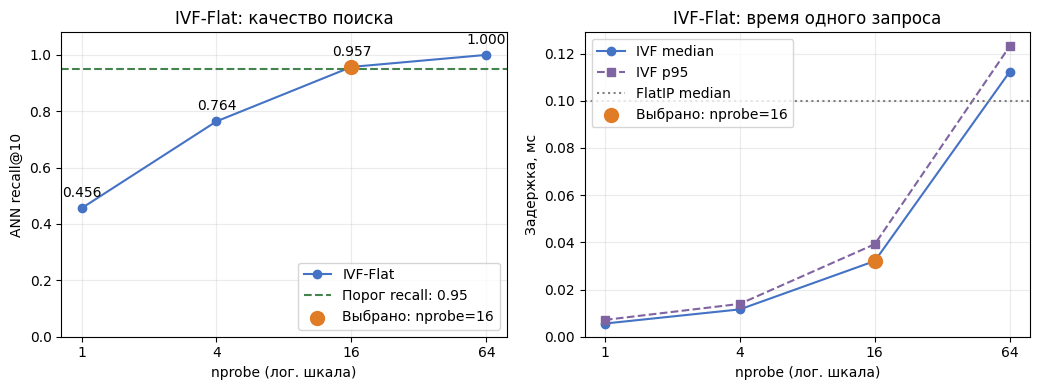

In [77]:
import matplotlib.pyplot as plt

ivf_recalls = [result[f"recall@{TOP_K}"] for result in ivf_sweep_results]
ivf_medians = [result["median_ms"] for result in ivf_sweep_results]
ivf_p95 = [result["p95_ms"] for result in ivf_sweep_results]

fig, (recall_ax, latency_ax) = plt.subplots(1, 2, figsize=(10.5, 4))
recall_ax.plot(ivf_nprobes, ivf_recalls, "o-", color="#4472c4", label="IVF-Flat")
recall_ax.axhline(
    IVF_TARGET_RECALL, color="#43834c", linestyle="--",
    label=f"Порог recall: {IVF_TARGET_RECALL:.2f}",
)
recall_ax.set_title("IVF-Flat: качество поиска")
recall_ax.set_ylabel(f"ANN recall@{TOP_K}")
recall_ax.set_ylim(0, 1.08)
for nprobe, recall in zip(ivf_nprobes, ivf_recalls):
    recall_ax.annotate(
        f"{recall:.3f}", (nprobe, recall),
        xytext=(0, 8), textcoords="offset points", ha="center",
    )

latency_ax.plot(ivf_nprobes, ivf_medians, "o-", color="#4472c4", label="IVF median")
latency_ax.plot(ivf_nprobes, ivf_p95, "s--", color="#8064a2", label="IVF p95")
latency_ax.axhline(
    exact_result["median_ms"], color="gray", linestyle=":", label="FlatIP median",
)
latency_ax.set_title("IVF-Flat: время одного запроса")
latency_ax.set_ylabel("Задержка, мс")
latency_ax.set_ylim(bottom=0)

if ivf_working_result is not None:
    recall_ax.scatter(
        ivf_working_nprobe, ivf_working_result[f"recall@{TOP_K}"],
        color="#e07b26", s=100, zorder=4, label=f"Выбрано: nprobe={ivf_working_nprobe}",
    )
    latency_ax.scatter(
        ivf_working_nprobe, ivf_working_result["median_ms"],
        color="#e07b26", s=100, zorder=4, label=f"Выбрано: nprobe={ivf_working_nprobe}",
    )

for ax in (recall_ax, latency_ax):
    ax.set_xscale("log", base=2)
    ax.set_xticks(ivf_nprobes, labels=[str(nprobe) for nprobe in ivf_nprobes])
    ax.set_xlabel("nprobe (лог. шкала)")
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)
recall_ax.legend(loc="lower right")
latency_ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

### Параметры PQ для коллекции SciFact

В корпусе 5183 документа. В каждом подпространстве PQ обучает `2**nbits` центроидов. При `nbits=8` это 256 центроидов; стандартная рекомендация FAISS — не менее 39 обучающих векторов на центроид, то есть `39 × 256 = 9984`.

Для этого семинара используем `PQ32x6`:

- `M=32` — делим вектор размерности 384 на 32 части по 12 координат;
- `nbits=6` — обучаем 64 центроида в каждой части; рекомендуемый минимум равен `39 × 64 = 2496` документов;
- Собственно PQ-код занимает `32 × 6 / 8 = 24` байта на документ: это `pq.code_size`. Для отдельного кодирования через `pq.sa_encode` нужен ещё номер IVF-списка: при `NLIST=64` он занимает 1 байт, поэтому `pq.sa_code_size()` равен 25 байтам. Исходный вектор занимает `384 × 4 = 1536` байт; файл всего индекса дополнительно содержит ID документов, центроиды и служебные данные.

Каждая таблица центроидов обучается на соответствующих частях всех 5183 векторов: число обучающих примеров не делится на `M`. Для coarse-квантизатора с `NLIST=64` рекомендация также составляет 2496 документов.

Уменьшение числа бит сокращает число центроидов, а увеличение числа подпространств относительно прежних восьми помогает сохранить качество сжатия. Это выбранный для нашего примера компромисс; отсутствие предупреждений само по себе не гарантирует высокий recall, поэтому ниже измеряем его при разных `nprobe`.


In [78]:
# IVF-PQ: 32 подпространства, по 6 бит на часть вектора.
PQ_M = 32
PQ_NBITS = 6
pq = faiss.IndexIVFPQ(
    faiss.IndexFlatIP(DIM),
    DIM,
    NLIST,
    PQ_M,
    PQ_NBITS,
    faiss.METRIC_INNER_PRODUCT,
)
pq.train(docs)
pq.add(docs)
pq_path = INDEX_DIR / "ivf_pq.index"
faiss.write_index(pq, str(pq_path))
pq_size = file_size(pq_path)
print("trained:", pq.is_trained, "items:", pq.ntotal, "size MiB:", round(pq_size, 2))
print("PQ centroids per subspace:", pq.pq.ksub)
print("PQ payload bytes per vector (code_size):", pq.code_size)
print("IVF list-number prefix bytes (coarse_code_size):", pq.coarse_code_size())
print("Standalone bytes per vector (sa_code_size):", pq.sa_code_size())

trained: True items: 5183 size MiB: 0.35
PQ centroids per subspace: 64
PQ payload bytes per vector (code_size): 24
IVF list-number prefix bytes (coarse_code_size): 1
Standalone bytes per vector (sa_code_size): 25


In [79]:
pq.nprobe = 1

def pq_search_nprobe_1(query, k):
    return pq.search(query.reshape(1, -1), k)[1][0]

pq_result_1, _ = benchmark(
    "IVF-PQ nprobe=1",
    pq_search_nprobe_1,
    index_size_mb=pq_size,
)

print_results([exact_result, pq_result_1], k=TOP_K)

index            ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------
exact / FlatIP           1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=1          0.361            0.454         0.016         0.018          0.35


In [80]:
pq.nprobe = 16

def pq_search_nprobe_16(query, k):
    return pq.search(query.reshape(1, -1), k)[1][0]

pq_result_16, _ = benchmark(
    "IVF-PQ nprobe=16",
    pq_search_nprobe_16,
    index_size_mb=pq_size,
)

print_results([exact_result, pq_result_16], k=TOP_K)

index             ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------
exact / FlatIP            1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=16          0.504            0.753         0.049         0.055          0.35


In [81]:
pq.nprobe = 64

def pq_search_nprobe_64(query, k):
    return pq.search(query.reshape(1, -1), k)[1][0]

pq_result_64, _ = benchmark(
    "IVF-PQ nprobe=64",
    pq_search_nprobe_64,
    index_size_mb=pq_size,
)

print_results([exact_result, pq_result_64], k=TOP_K)

index             ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------
exact / FlatIP            1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=64          0.507            0.762         0.151         0.166          0.35


IVF-PQ занимает меньше места, потому что хранит сжатые коды векторов вместо исходных чисел. Цена — приближённые расстояния и обычно меньший recall. `nprobe` добавляет второй компромисс: больше посещённых ячеек повышает качество и latency.

### Обучение на подвыборке, поиск по всему корпусу

Выберем **3000 документов без повторений** для `train`, а в `add` передадим все **5183 документа SciFact**. Для IVF-Flat и IVF-PQ сохраняем прежние `NLIST`, параметры PQ и seed кластеризации, используем `nprobe=16`. Сравниваем с уже измеренными вариантами, обученными на всём корпусе, по тем же запросам, exact top-k и qrels.

При 64 coarse-центроидах и 64 центроидах в каждой части PQ ориентир FAISS составляет `39 × 64 = 2496` обучающих векторов. Выборка из 3000 превышает этот порог предупреждения; достаточность размера для нужного recall проверяется отдельно. Один такой опыт показывает чувствительность к выборке и не гарантирует монотонного роста качества при добавлении обучающих документов.

In [82]:
TRAIN_SAMPLE_SIZE = 3000
np.random.seed(SEED)
train_positions = np.sort(np.random.choice(len(docs), TRAIN_SAMPLE_SIZE, replace=False))
train_vectors = docs[train_positions]

coarse_training_threshold = ivf.cp.min_points_per_centroid * NLIST
pq_training_threshold = pq.pq.cp.min_points_per_centroid * pq.pq.ksub
print("training sample seed:", SEED)
print("full / subset training documents:", len(docs), len(train_vectors))
print("indexed documents in both cases:", len(docs))
print("indexed documents outside training subset:", len(docs) - len(train_vectors))
print("first training positions:", train_positions[:10].tolist())
print("FAISS warning thresholds, coarse / PQ:", coarse_training_threshold, pq_training_threshold)

training sample seed: 42
full / subset training documents: 5183 3000
indexed documents in both cases: 5183
indexed documents outside training subset: 2183
first training positions: [0, 6, 7, 8, 12, 14, 17, 19, 22, 23]
FAISS warning thresholds, coarse / PQ: 2496 2496


In [83]:
# Новый необученный IVF-Flat: меняем только матрицу для train.
ivf_subset = faiss.IndexIVFFlat(
    faiss.IndexFlatIP(DIM), DIM, NLIST, faiss.METRIC_INNER_PRODUCT
)
ivf_subset.cp.seed = ivf.cp.seed
ivf_subset.train(train_vectors)
print("after train: trained / stored documents:", ivf_subset.is_trained, ivf_subset.ntotal)

ivf_subset.add(docs)
ivf_subset.nprobe = 16
ivf_subset.max_codes = 0
ivf_subset_path = INDEX_DIR / "ivf_train_subset.index"
faiss.write_index(ivf_subset, str(ivf_subset_path))

def ivf_subset_search(query, k):
    return ivf_subset.search(query.reshape(1, -1), k)[1][0]

ivf_subset_result, ivf_subset_ids = benchmark(
    "IVF train=3000, nprobe=16",
    ivf_subset_search,
    index_size_mb=file_size(ivf_subset_path),
)
print("train / indexed documents:", len(train_vectors), ivf_subset.ntotal)
print("nlist / nprobe / clustering seed:", ivf_subset.nlist, ivf_subset.nprobe, ivf_subset.cp.seed)
print_results([exact_result, ivf_result_16, ivf_subset_result], k=TOP_K)

after train: trained / stored documents: True 0


train / indexed documents: 3000 5183
nlist / nprobe / clustering seed: 64 16 1234
index                      ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------------
exact / FlatIP                     1.000            0.860         0.100         0.111          7.59
IVF nprobe=16                      0.957            0.840         0.032         0.039          7.73
IVF train=3000, nprobe=16          0.961            0.846         0.035         0.044          7.73


In [84]:
# Coarse-центроиды и кодовые книги PQ обучаются на той же подвыборке.
pq_subset = faiss.IndexIVFPQ(
    faiss.IndexFlatIP(DIM), DIM, NLIST, PQ_M, PQ_NBITS, faiss.METRIC_INNER_PRODUCT
)
pq_subset.cp.seed = pq.cp.seed
pq_subset.pq.cp.seed = pq.pq.cp.seed
pq_subset.by_residual = pq.by_residual
pq_subset.train(train_vectors)
print("after train: trained / stored documents:", pq_subset.is_trained, pq_subset.ntotal)

pq_subset.add(docs)
pq_subset.nprobe = 16
pq_subset.max_codes = 0
pq_subset_path = INDEX_DIR / "ivf_pq_train_subset.index"
faiss.write_index(pq_subset, str(pq_subset_path))

def pq_subset_search(query, k):
    return pq_subset.search(query.reshape(1, -1), k)[1][0]

pq_subset_result, pq_subset_ids = benchmark(
    "IVF-PQ train=3000, nprobe=16",
    pq_subset_search,
    index_size_mb=file_size(pq_subset_path),
)
print("train / indexed documents:", len(train_vectors), pq_subset.ntotal)
print("nlist / nprobe / M / nbits:", pq_subset.nlist, pq_subset.nprobe, pq_subset.pq.M, pq_subset.pq.nbits)
print("coarse / PQ clustering seeds:", pq_subset.cp.seed, pq_subset.pq.cp.seed)
print_results([exact_result, pq_result_16, pq_subset_result], k=TOP_K)

after train: trained / stored documents: True 0
train / indexed documents: 3000 5183
nlist / nprobe / M / nbits: 64 16 32 6
coarse / PQ clustering seeds: 1234 1234
index                         ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------
exact / FlatIP                        1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=16                      0.504            0.753         0.049         0.055          0.35
IVF-PQ train=3000, nprobe=16          0.496            0.728         0.052         0.061          0.35


### Фабрика индексов: `index_factory`

FAISS умеет собирать индексы по строковому описанию. Это удобно, когда конфигурация индекса приходит из YAML или другого конфига, а не зашита в Python-классах.

In [85]:
factory_flat = faiss.index_factory(DIM, "Flat", faiss.METRIC_INNER_PRODUCT)
factory_ivf = faiss.index_factory(DIM, f"IVF{NLIST},Flat", faiss.METRIC_INNER_PRODUCT)
factory_pq = faiss.index_factory(DIM, f"IVF{NLIST},PQ{PQ_M}x{PQ_NBITS}", faiss.METRIC_INNER_PRODUCT)
print("Flat:", type(factory_flat).__name__)
print("IVF:", type(factory_ivf).__name__)
print("IVF-PQ:", type(factory_pq).__name__)

Flat: IndexFlat
IVF: IndexIVFFlat
IVF-PQ: IndexIVFPQ


In [86]:
factory_ivf.train(docs)
factory_ivf.add(docs)
factory_ivf.nprobe = 16
factory_ivf_path = INDEX_DIR / "factory_ivf.index"
faiss.write_index(factory_ivf, str(factory_ivf_path))

def factory_ivf_search(query, k):
    return factory_ivf.search(query.reshape(1, -1), k)[1][0]

factory_ivf_result, _ = benchmark(
    "Factory IVF nprobe=16",
    factory_ivf_search,
    index_size_mb=file_size(factory_ivf_path),
)

print_results([exact_result, factory_ivf_result], k=TOP_K)

index                  ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------
exact / FlatIP                 1.000            0.860         0.100         0.111          7.59
Factory IVF nprobe=16          0.957            0.840         0.033         0.038          7.73


## 6. Расширенная часть FAISS

Дальше разберём, как повысить точность поиска, ограничить выдачу, выбрать устройство индекса и работать с изменениями коллекции.

| Разделы | Тема | Для чего нужна |
| --- | --- | --- |
| 7 | `IndexRefineFlat` | Точно пересчитать близость найденных кандидатов. |
| 8–10 | Фильтры, варианты поиска и реконструкция | Ограничивать выдачу, разбирать ID, коды и восстановленные векторы. |
| 11–13 | Преобразования, SQ8 и HNSW | Сравнить качество поиска, задержку и размер индекса. |
| 14–15 | `index_factory` и автотюнинг | Собирать индексы и подбирать параметры под целевой recall. |
| 16–17 | Жизненный цикл, шарды и реплики | Обновлять данные и объединять индексы в одном процессе. |
| 18–19 | Бинарные индексы и дополнительные метрики | Разобрать битовые коды и другие меры близости. |


## 7. FAISS как конструктор: `IndexRefineFlat`

У IVF-PQ есть две причины потери качества: IVF может не просмотреть нужный список, а PQ — неточно оценить близость векторов внутри просмотренных списков. `IndexRefineFlat` помогает со второй причиной: базовый индекс возвращает расширенный список кандидатов, а отдельный `IndexFlat` пересчитывает их скоры по исходным векторам и выбирает итоговый top-k. Здесь скор — inner product, который для наших нормализованных векторов равен cosine similarity.

Для этой демонстрации нужен именно **IVF-PQ**. У `IndexIVFFlat` скоры внутри просмотренных списков уже точные. Если взять его top-20 или top-40 и ещё раз посчитать те же скоры, итоговый top-10 не изменится (кроме возможных перестановок при равных скорах или погрешности вычислений).

Коэффициент `k_factor` задаёт размер списка для точного пересчёта: при `TOP_K=10` значения `2`, `4` и `8` дают соответственно 20, 40 и 80 кандидатов. Он **не меняет `nprobe`**: во всех трёх опытах базовый индекс просматривает те же четыре IVF-списка. При `k_factor=1` второй этап может переставить найденные десять документов, но не добавить новые, поэтому ANN recall@10 останется прежним.

In [87]:
# Создаём новый IVF-PQ с параметрами квантования из предыдущего раздела.
refine_base = faiss.IndexIVFPQ(
    faiss.IndexFlatIP(DIM), DIM, NLIST, PQ_M, PQ_NBITS, faiss.METRIC_INNER_PRODUCT
)
refine_base.train(docs)
refine_base.nprobe = 4
refine_base.max_codes = 0  # Просматриваем выбранные списки без лимита числа кодов.

# Оборачиваем обученный, но ещё пустой индекс. add() синхронно добавит
# PQ-коды в базовый индекс, а исходные векторы — в точный refine-индекс.
refine = faiss.IndexRefineFlat(refine_base)
refine.add(docs)

# Сохраняем отдельно базовый IVF-PQ и весь составной индекс после добавления данных.
refine_base_path = INDEX_DIR / "refine_base.index"
refine_path = INDEX_DIR / "refine.index"
faiss.write_index(refine_base, str(refine_base_path))
faiss.write_index(refine, str(refine_path))
refine_base_size = file_size(refine_base_path)
refine_size = file_size(refine_path)

print("base type:", type(refine_base).__name__)
print("refine type:", type(refine).__name__)
print("base ntotal:", refine_base.ntotal, "refine ntotal:", refine.ntotal)
print("base IVF-PQ size MiB:", round(refine_base_size, 2))
print("with RefineFlat size MiB:", round(refine_size, 2))
print("additional storage MiB:", round(refine_size - refine_base_size, 2))
print("original float32 vectors MiB:", round(docs.nbytes / 1024**2, 2))

base type: IndexIVFPQ
refine type: IndexRefineFlat
base ntotal: 5183 refine ntotal: 5183
base IVF-PQ size MiB: 0.35
with RefineFlat size MiB: 7.94
additional storage MiB: 7.59
original float32 vectors MiB: 7.59


In [88]:
# Базовый IVF-PQ: те же документы, запросы, TOP_K и nprobe=4.
refine_base_result, refine_base_ids = benchmark(
    "IVF-PQ nprobe=4 (refine base)",
    lambda query, k: refine_base.search(query.reshape(1, -1), k)[1][0],
    index_size_mb=refine_base_size,
)
print_results([exact_result, refine_base_result], k=TOP_K)
print("IVF-PQ query 0 ids:", refine_base_ids[0].tolist())

index                          ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------------
exact / FlatIP                         1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=4 (refine base)          0.474            0.682         0.021         0.024          0.35
IVF-PQ query 0 ids: [4132, 1490, 1815, 5147, 4241, 5017, 1879, 3245, 2660, 1144]


In [89]:
# k_factor=2 означает, что точный этап пересчитает 2 * TOP_K кандидатов.
refine.k_factor = 2
refine_result_2, refine_ids_2 = benchmark(
    "IVF-PQ + RefineFlat nprobe=4, k_factor=2",
    lambda query, k: refine.search(query.reshape(1, -1), k)[1][0],
    index_size_mb=refine_size,
)
print_results([exact_result, refine_base_result, refine_result_2], k=TOP_K)
print("k_factor=2 query 0 ids:", refine_ids_2[0].tolist())

index                                     ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------------------
exact / FlatIP                                    1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=4 (refine base)                     0.474            0.682         0.021         0.024          0.35
IVF-PQ + RefineFlat nprobe=4, k_factor=2          0.609            0.710         0.072         0.083          7.94
k_factor=2 query 0 ids: [4132, 2554, 1373, 3245, 4564, 4501, 5147, 4241, 149, 5017]


In [90]:
# Теперь пересчитываем 4 * TOP_K = 40 кандидатов при том же nprobe=4.
refine.k_factor = 4
refine_result_4, refine_ids_4 = benchmark(
    "IVF-PQ + RefineFlat nprobe=4, k_factor=4",
    lambda query, k: refine.search(query.reshape(1, -1), k)[1][0],
    index_size_mb=refine_size,
)
print_results([exact_result, refine_base_result, refine_result_4], k=TOP_K)
print("k_factor=4 query 0 ids:", refine_ids_4[0].tolist())
print(f"queries with changed top-{TOP_K} vs k_factor=2:",
      np.count_nonzero(np.any(refine_ids_4 != refine_ids_2, axis=1)), "/", len(queries))

index                                     ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------------------
exact / FlatIP                                    1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=4 (refine base)                     0.474            0.682         0.021         0.024          0.35
IVF-PQ + RefineFlat nprobe=4, k_factor=4          0.698            0.721         0.074         0.084          7.94
k_factor=4 query 0 ids: [4132, 4368, 2554, 1373, 3190, 3245, 4564, 2321, 4501, 3975]
queries with changed top-10 vs k_factor=2: 938 / 1109


In [91]:
# При k_factor=8 точный этап получает 80 кандидатов из тех же IVF-списков.
refine.k_factor = 8
refine_result_8, refine_ids_8 = benchmark(
    "IVF-PQ + RefineFlat nprobe=4, k_factor=8",
    lambda query, k: refine.search(query.reshape(1, -1), k)[1][0],
    index_size_mb=refine_size,
)
print_results([exact_result, refine_base_result, refine_result_8], k=TOP_K)
print("k_factor=8 query 0 ids:", refine_ids_8[0].tolist())
print(f"queries with changed top-{TOP_K} vs k_factor=4:",
      np.count_nonzero(np.any(refine_ids_8 != refine_ids_4, axis=1)), "/", len(queries))

index                                     ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------------------
exact / FlatIP                                    1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=4 (refine base)                     0.474            0.682         0.021         0.024          0.35
IVF-PQ + RefineFlat nprobe=4, k_factor=8          0.748            0.726         0.076         0.088          7.94
k_factor=8 query 0 ids: [4132, 4368, 2554, 1373, 3190, 4908, 3245, 4564, 2321, 4501]
queries with changed top-10 vs k_factor=4: 663 / 1109


In [92]:
# Сводка уже выполненных измерений: качество, задержка и размер индекса.
print_results([
    exact_result,
    refine_base_result,
    refine_result_2,
    refine_result_4,
    refine_result_8,
], k=TOP_K)

index                                     ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
------------------------------------------------------------------------------------------------------------------
exact / FlatIP                                    1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=4 (refine base)                     0.474            0.682         0.021         0.024          0.35
IVF-PQ + RefineFlat nprobe=4, k_factor=2          0.609            0.710         0.072         0.083          7.94
IVF-PQ + RefineFlat nprobe=4, k_factor=4          0.698            0.721         0.074         0.084          7.94
IVF-PQ + RefineFlat nprobe=4, k_factor=8          0.748            0.726         0.076         0.088          7.94


Сравниваем базовый IVF-PQ и три варианта `IndexRefineFlat` при одинаковом `nprobe=4`. Таблица показывает ANN/qrels recall, median/p95 полного поиска и размер сериализованного индекса.

**`IndexRefineFlat` дополнительно хранит полные float32-векторы**, а точный пересчёт не возвращает документы, отсутствующие среди кандидатов. `size MiB` измеряет файл на диске, а не оперативную память; увеличение `k_factor` меняет поиск и временные буферы, но не состав хранимых векторов.

<details>
<summary>Как читать компромисс качества, времени и памяти</summary>

`benchmark` последовательно обрабатывает все запросы по одному, как в остальных сравнениях ноутбука. Для `IndexRefineFlat` замер охватывает весь вызов `search`: получение кандидатов из IVF-PQ, точный пересчёт их скоров и выбор итогового top-k. Обучение, добавление документов и запись файлов выполняются до замера. Поэтому median/p95 можно сопоставлять с остальными строками общей таблицы в том же режиме одиночных запросов.

Точный второй этап не вернёт документ, который не попал в список кандидатов. `nprobe` расширяет набор просматриваемых IVF-списков, а `k_factor` — число кандидатов из этих списков, переданных на пересчёт. Увеличение `k_factor` постепенно исчерпывает пользу: документы из непросмотренных списков так и останутся недоступны.

За пересчёт платим временем и памятью. `IndexRefineFlat` хранит **полные исходные float32-векторы** дополнительно к IVF-PQ. Базовый файл `indexes/refine_base.index` содержит IVF-PQ, а составной `indexes/refine.index` — оба этапа. Разница их размеров примерно соответствует объёму исходных векторов `docs.nbytes`; небольшую добавку дают служебные поля.

В столбце `size MiB` указан размер файла на диске. Занятая оперативная память дополнительно зависит от служебных структур и временных буферов поиска. При `k_factor=2/4/8` сохраняются одни и те же документы и коды, поэтому размер хранимого индекса одинаков. Меняются число кандидатов, объём работы при поиске и временные буферы.

Большее число кандидатов обычно повышает recall и стоимость поиска. На небольшом корпусе отдельные замеры времени могут колебаться, поэтому таблицу следует читать как результат текущего запуска, а не обещание строгого роста latency при каждом увеличении `k_factor`.

</details>

### Полнота кандидатов: где теряются документы до refine

Сравним все документы в четырёх выбранных IVF-списках, расширенный пул кандидатов и итоговый top-10. Для контроля построим `IndexIVFFlat` с **теми же обученными центроидами**: он выберет те же списки, но отберёт кандидатов по точному inner product.

Пересчёт устраняет ошибку скоров только внутри уже отобранного пула. Покрытие точных соседей и покрытие qrels — разные показатели; потери размеченных документов нельзя целиком приписывать PQ.

<details>
<summary>Candidate recall, два эталона и разделение причин потерь</summary>

Для запроса обозначим через `S` все документы в выбранных IVF-списках, через `P_C` — `C` кандидатов IVF-PQ, а через `T_10` — итоговый top-10 после refine. Здесь `T_10` входит в `P_C`, а `P_C` — в `S`. Поскольку `max_codes=0` и дополнительных фильтров нет, базовый индекс рассматривает все записи выбранных списков. Увеличение `k_factor` расширяет `P_C`, но не меняет `S`.

В таблицах есть два независимых эталона. **ANN coverage@10** — доля соседей исходного точного top-10, присутствующих во всём рассматриваемом пуле; знаменатель остаётся равным 10 даже для 20, 40 или 80 кандидатов. **Qrels recall** — доля размеченных релевантных документов в этом пуле; знаменатель — число qrels данного запроса. На строках кандидатов это candidate recall, на строке `After refine` — обычный qrels recall итогового top-10. Обе доли усредняются по запросам; запросы без qrels пропускаются при расчёте второй метрики.

`qrels pairs` показывает общее число найденных размеченных пар «запрос — документ». Один документ, релевантный двум запросам, участвует в двух парах. Доля от общего числа пар и средний recall по запросам могут различаться: у запросов разное число релевантных документов.

Строка `All probed lists` показывает доступность документов до отбора кандидатов. Строка `Exact candidates` ограничивает пул теми же `C` документами, но использует точные скоры; она нужна для сравнения с `PQ candidates`. Центроиды копируем из базового IVF-PQ и заново не обучаем. Повторное обучение независимого IVF создало бы другое разбиение и смешало причины различий.

Для соседей исходного top-10 разделение особенно простое. При `C >= 10` точный пул внутри выбранных списков содержит всех доступных в этих списках соседей исходного top-10. Поэтому `1 - coverage(S)` — потери из-за непросмотренных списков, а `coverage(S) - coverage(P_C)` — потери при отборе по PQ-скорам в ограниченный пул. Точный refine возвращает присутствующих в `P_C` соседей исходного top-10. Эти три доли — две потери и итоговое покрытие — дают единицу, с оговоркой о равных скорах и численных погрешностях.

Для qrels нельзя всю разницу между `All probed lists` и `PQ candidates` приписать ошибке квантования. Размеченный документ может иметь низкую cosine similarity и не попасть даже в точный top-C. Сравниваем оба пула одинакового размера; разность их qrels recall — итоговый эффект замены точных скоров приближёнными, который вообще может быть любого знака. После refine qrels recall может уменьшиться относительно candidate recall: из `C` кандидатов остаются десять, а точный inner product не гарантирует высокого ранга размеченным документам.

Это дополнительный разбор уже построенного индекса. Поиски для диагностики и восстановление состава списков выполняются вне замеров latency; строки таблиц с кандидатами не добавляются в общий benchmark как новые поисковые конфигурации.

</details>

In [93]:
import pandas as pd

# Точный контроль использует центроиды того же IVF-PQ: train здесь не нужен.
refine_pool_flat = faiss.IndexIVFFlat(
    faiss.clone_index(refine_base.quantizer),
    DIM,
    refine_base.nlist,
    faiss.METRIC_INNER_PRODUCT,
)
refine_pool_flat.nprobe = refine_base.nprobe
refine_pool_flat.max_codes = 0
refine_pool_flat.add(docs)

# ID равны позициям docs; после add этот индекс не обновлялся и не удалял записи.
refine_doc_lists = refine_base.quantizer.assign(docs, 1).ravel()
refine_probe_lists = refine_base.quantizer.search(query_matrix, refine_base.nprobe)[1]
refine_scanned_ids = [
    np.flatnonzero(np.isin(refine_doc_lists, list_ids))
    for list_ids in refine_probe_lists
]

def refine_pool_stats(stage, candidate_ids):
    pools = [set(row) - {-1} for row in candidate_ids]
    ann_coverage = [
        len(pool & set(truth)) / TOP_K
        for pool, truth in zip(pools, exact_ids)
    ]
    qrels_hits = [len(pool & relevant) for pool, relevant in zip(pools, relevant_positions)]
    qrels_recalls = [
        hits / len(relevant)
        for hits, relevant in zip(qrels_hits, relevant_positions)
        if relevant
    ]
    return {
        "stage": stage,
        "mean pool size": float(np.mean([len(pool) for pool in pools])),
        f"ANN coverage@{TOP_K}": float(np.mean(ann_coverage)),
        "qrels recall": float(np.mean(qrels_recalls)),
        "qrels pairs": sum(qrels_hits),
    }

refine_scanned_stats = refine_pool_stats("All probed lists", refine_scanned_ids)
print("queries:", len(query_matrix), "nprobe:", refine_base.nprobe, "max_codes:", refine_base.max_codes)
print("total annotated query-document pairs:", sum(map(len, relevant_positions)))
pd.DataFrame([refine_scanned_stats]).set_index("stage").round(4)

queries: 1109 nprobe: 4 max_codes: 0
total annotated query-document pairs: 1258


,mean pool size,ANN coverage@10,qrels recall,qrels pairs
stage,,,,
All probed lists,358.4851,0.7641,0.7917,1011


In [94]:
# 20 кандидатов при TOP_K=10, как в уже измеренном опыте k_factor=2.
_, refine_candidates_2 = refine_base.search(query_matrix, 2 * TOP_K)
_, refine_exact_candidates_2 = refine_pool_flat.search(query_matrix, 2 * TOP_K)
refine_candidates_stats_2 = refine_pool_stats(f"PQ candidates, C={2 * TOP_K}", refine_candidates_2)
refine_exact_stats_2 = refine_pool_stats(f"Exact candidates, C={2 * TOP_K}", refine_exact_candidates_2)
refine_final_stats_2 = refine_pool_stats(f"After refine, k={TOP_K}", refine_ids_2)

pd.DataFrame([
    refine_scanned_stats,
    refine_exact_stats_2,
    refine_candidates_stats_2,
    refine_final_stats_2,
]).set_index("stage").round(4)

,mean pool size,ANN coverage@10,qrels recall,qrels pairs
stage,,,,
All probed lists,358.4851,0.7641,0.7917,1011
"Exact candidates, C=20",20.0000,0.7641,0.7534,960
"PQ candidates, C=20",20.0000,0.6095,0.7272,927
"After refine, k=10",10.0000,0.6095,0.7102,902


In [95]:
# 40 кандидатов из тех же четырёх списков; точный контроль имеет такой же бюджет.
_, refine_candidates_4 = refine_base.search(query_matrix, 4 * TOP_K)
_, refine_exact_candidates_4 = refine_pool_flat.search(query_matrix, 4 * TOP_K)
refine_candidates_stats_4 = refine_pool_stats(f"PQ candidates, C={4 * TOP_K}", refine_candidates_4)
refine_exact_stats_4 = refine_pool_stats(f"Exact candidates, C={4 * TOP_K}", refine_exact_candidates_4)
refine_final_stats_4 = refine_pool_stats(f"After refine, k={TOP_K}", refine_ids_4)

pd.DataFrame([
    refine_scanned_stats,
    refine_exact_stats_4,
    refine_candidates_stats_4,
    refine_final_stats_4,
]).set_index("stage").round(4)

,mean pool size,ANN coverage@10,qrels recall,qrels pairs
stage,,,,
All probed lists,358.4851,0.7641,0.7917,1011
"Exact candidates, C=40",40.0000,0.7641,0.7764,990
"PQ candidates, C=40",40.0000,0.6976,0.7559,967
"After refine, k=10",10.0000,0.6976,0.7214,917


In [96]:
# 80 кандидатов: проверяем, насколько приблизились к покрытию выбранных списков.
_, refine_candidates_8 = refine_base.search(query_matrix, 8 * TOP_K)
_, refine_exact_candidates_8 = refine_pool_flat.search(query_matrix, 8 * TOP_K)
refine_candidates_stats_8 = refine_pool_stats(f"PQ candidates, C={8 * TOP_K}", refine_candidates_8)
refine_exact_stats_8 = refine_pool_stats(f"Exact candidates, C={8 * TOP_K}", refine_exact_candidates_8)
refine_final_stats_8 = refine_pool_stats(f"After refine, k={TOP_K}", refine_ids_8)

pd.DataFrame([
    refine_scanned_stats,
    refine_exact_stats_8,
    refine_candidates_stats_8,
    refine_final_stats_8,
]).set_index("stage").round(4)

,mean pool size,ANN coverage@10,qrels recall,qrels pairs
stage,,,,
All probed lists,358.4851,0.7641,0.7917,1011
"Exact candidates, C=80",80.0000,0.7641,0.7836,1001
"PQ candidates, C=80",80.0000,0.7484,0.7741,990
"After refine, k=10",10.0000,0.7484,0.7264,923


In [97]:
# Разложение потерь относительно исходного точного top-k, а не относительно qrels.
refine_coverage_key = f"ANN coverage@{TOP_K}"
refine_list_coverage = refine_scanned_stats[refine_coverage_key]
refine_ann_losses = pd.DataFrame({
    "candidates": [2 * TOP_K, 4 * TOP_K, 8 * TOP_K],
    "outside IVF lists": [1 - refine_list_coverage] * 3,
    "missed by PQ selection": [
        refine_list_coverage - refine_candidates_stats_2[refine_coverage_key],
        refine_list_coverage - refine_candidates_stats_4[refine_coverage_key],
        refine_list_coverage - refine_candidates_stats_8[refine_coverage_key],
    ],
    "returned after refine": [
        refine_final_stats_2[refine_coverage_key],
        refine_final_stats_4[refine_coverage_key],
        refine_final_stats_8[refine_coverage_key],
    ],
}).set_index("candidates")
refine_ann_losses.round(4)

,outside IVF lists,missed by PQ selection,returned after refine
candidates,,,
20,0.2359,0.1546,0.6095
40,0.2359,0.0665,0.6976
80,0.2359,0.0157,0.7484


## 8. Фильтрация внутри IVF: `SearchParametersIVF` и `IDSelector`

Постфильтрация после ANN может оставить меньше `k` документов. FAISS умеет передать селектор во время поиска IVF, чтобы запрещённые ID вообще не участвовали в выдаче. Покажем три формы селектора:

- `IDSelectorBatch` — произвольное множество разрешённых ID;
- `IDSelectorRange` — непрерывный диапазон ID;
- `IDSelectorBitmap` — компактная битовая маска для больших наборов.

В production условие обычно строится по индексу метаданных, а здесь мы явно создаём маленькие списки разрешённых ID.

**ID `-1` — заполнитель:** удаляем его перед обращением к метаданным и той же маской отбираем скоры. Принадлежность фильтру и количество результатов проверяем отдельно: пустая выдача тоже проходит `np.all`.

<details>
<summary>Как проверять неполную и пустую выдачу: ID -1 и число результатов</summary>

FAISS возвращает матрицу с `k` позициями даже тогда, когда подходящих документов меньше. Незанятые позиции содержат ID `-1`. Это служебное значение: в NumPy выражение `metadata[-1]` обращается к последнему документу, поэтому такой ID нельзя передавать в индексацию метаданных.

Сначала оставляем только ID `>= 0`. Если используем скоры, применяем к ним ту же маску. Затем отдельно проверяем количество найденных документов и принадлежность разрешённому множеству. Одной проверки `np.all` недостаточно: на пустом массиве она возвращает `True`.

В примерах трёх селекторов и граничных случаев задаём `nprobe=NLIST` и `max_codes=0`: поиск просматривает все записи всех списков, а разрешённые ID существуют в исходном индексе. Поэтому ожидаем `min(TOP_K, число разрешённых документов)` настоящих ID. Если разрешены три документа и запрошено десять, корректный результат содержит три ID и семь заполнителей `-1`. Если не разрешено ничего, корректна пустая выдача после маскирования; выводим это явно и не печатаем для неё успешную проверку принадлежности.

Для ANN с ограниченным `nprobe` документы из непросмотренных списков могут остаться недоступны. В таком режиме недостаточная выдача сама по себе не означает ошибку селектора; проверку количества нужно связывать с параметрами поиска.

</details>


In [98]:
faiss_filter_tenant = doc_bucket
faiss_filter_query_tenant = int(query_bucket[0])
allowed_batch_ids = np.flatnonzero(
    faiss_filter_tenant == faiss_filter_query_tenant
).astype("int64")
selector_batch = faiss.IDSelectorBatch(allowed_batch_ids)
params_batch = faiss.SearchParametersIVF()
params_batch.nprobe = NLIST
params_batch.max_codes = 0
params_batch.sel = selector_batch
filtered_distances, filtered_ids = ivf.search(
    query_matrix[:1], TOP_K, params=params_batch
)

# -1 означает незаполненную позицию, а не ID последнего документа.
valid_filtered_mask = filtered_ids[0] >= 0
valid_filtered_ids = filtered_ids[0][valid_filtered_mask]
expected_filtered_count = min(TOP_K, len(allowed_batch_ids))
print("allowed ids:", len(allowed_batch_ids))
print("native batch-filter ids:", valid_filtered_ids.tolist())
print("returned / expected / requested:", len(valid_filtered_ids), expected_filtered_count, TOP_K)
assert len(valid_filtered_ids) == expected_filtered_count
if len(valid_filtered_ids):
    batch_filter_ok = bool(np.all(np.isin(valid_filtered_ids, allowed_batch_ids)))
    print("all ids obey filter:", batch_filter_ok)
    assert batch_filter_ok
else:
    print("No allowed documents: the result is empty.")

allowed ids: 1296
native batch-filter ids: [4132, 4368, 2324, 4908, 4564, 2488, 1044, 760, 1728, 2660]
returned / expected / requested: 10 10 10
all ids obey filter: True


In [99]:
# IDSelectorRange удобен, если разрешение задаётся диапазоном внутренних ID.
range_selector = faiss.IDSelectorRange(0, RANGE_LIMIT)
params_range = faiss.SearchParametersIVF()
params_range.nprobe = NLIST
params_range.max_codes = 0
params_range.sel = range_selector
range_distances, range_ids = ivf.search(query_matrix[:1], TOP_K, params=params_range)

valid_range_mask = range_ids[0] >= 0
valid_range_ids = range_ids[0][valid_range_mask]
expected_range_count = min(TOP_K, RANGE_LIMIT, len(docs))
print("range [0, %d) ids:" % RANGE_LIMIT, valid_range_ids.tolist())
print("returned / expected / requested:", len(valid_range_ids), expected_range_count, TOP_K)
assert len(valid_range_ids) == expected_range_count
if len(valid_range_ids):
    range_filter_ok = bool(np.all(valid_range_ids < RANGE_LIMIT))
    print("all ids in range:", range_filter_ok)
    assert range_filter_ok
else:
    print("No allowed documents: the result is empty.")

range [0, 1000) ids: [766, 166, 869, 687, 149, 760, 697, 606, 190, 394]
returned / expected / requested: 10 10 10
all ids in range: True


### Как устроен bitmap-фильтр

**Bitmap хранит один бит разрешения на ID: 1 разрешает документ, 0 запрещает.** В `IDSelectorBitmap` передаём число байтов и сохраняем массив в памяти; повторяющиеся номера байтов обрабатываем через `np.bitwise_or.at`, чтобы не потерять биты.

<details>
<summary>Подробнее о bitmap-фильтре и IDSelectorBitmap</summary>

`allowed_batch_ids` содержит позиции документов, разрешённых для tenant текущего запроса. `IDSelectorBatch` хранит набор таких ID, а `IDSelectorBitmap` кодирует тот же набор битовой маской: **бит 1 разрешает документ, бит 0 запрещает**. Здесь ID — позиции в матрице `docs` от 0 до `len(docs) - 1`, а не строковые ID корпуса SciFact.

Один элемент массива `uint8` занимает байт и хранит восемь битов. Поэтому для N документов нужно `(N + 7) // 8` байтов — деление на восемь с округлением вверх. У документа с ID `i` номер байта равен `i // 8`, а номер бита внутри байта — `i % 8`. Биты нумеруются от младшего к старшему: `1 << 0` равно `00000001`, а `1 << 4` — `00010000`.

Например, разрешим ID `[0, 4, 8, 12]`. Документы 0 и 4 относятся к первому байту, 8 и 12 — ко второму. В обоих байтах нужно выставить биты 0 и 4: `00000001 | 00010000 = 00010001`, то есть 17. Получится массив `[17, 17]`.

`np.bitwise_or.at` последовательно объединяет битовые маски для каждого байта. Обычная запись `bitmap[byte_ids] |= masks` здесь неверна: при повторяющихся `byte_ids` NumPy работает с временной копией, и обновления одного байта не накапливаются. В нашем примере такая запись потеряла бы разрешённые ID 0 и 8.

В `IDSelectorBitmap` передаём **число байтов** `len(bitmap)` и указатель `faiss.swig_ptr(bitmap)` на данные NumPy. В этой форме вызова FAISS использует существующий буфер, поэтому массив должен оставаться в памяти всё время использования селектора.

`params_bitmap.sel` включает фильтр внутри поиска. `nprobe=NLIST` заставляет IVF просмотреть все списки: здесь это позволяет сравнить способы фильтрации без потерь из-за отбора списков. `query_matrix[:1]` передаёт один запрос в форме матрицы, а `TOP_K` задаёт число соседей. ID `-1` означает незаполненное место, если подходящих документов меньше `TOP_K`.

После удаления заполнителей `-1` проверяем ожидаемое число результатов и принадлежность каждого найденного ID множеству `allowed_batch_ids`. Пустую выдачу обрабатываем отдельно: для неё не печатаем успешный `all ids obey bitmap`. Эти проверки ещё не доказывают, что не потеряны разрешённые документы за пределами top-k. Поэтому также сравниваем выдачу с `IDSelectorBatch`, которому передан тот же набор разрешённых ID.

</details>


In [100]:
# Один бит на ID, восемь ID на байт. Округляем число байтов вверх.
bitmap = np.zeros((len(docs) + 7) // 8, dtype="uint8")
# Несколько ID могут попадать в один байт: .at накапливает все их биты.
np.bitwise_or.at(
    bitmap,
    allowed_batch_ids // 8,
    (1 << (allowed_batch_ids % 8)).astype("uint8"),
)
# Передаём число байтов и указатель на массив. bitmap сохраняем в памяти.
selector_bitmap = faiss.IDSelectorBitmap(len(bitmap), faiss.swig_ptr(bitmap))
params_bitmap = faiss.SearchParametersIVF()
params_bitmap.nprobe = NLIST
params_bitmap.max_codes = 0
params_bitmap.sel = selector_bitmap
bitmap_distances, bitmap_ids = ivf.search(
    query_matrix[:1], TOP_K, params=params_bitmap
)

valid_bitmap_mask = bitmap_ids[0] >= 0
valid_bitmap_ids = bitmap_ids[0][valid_bitmap_mask]
expected_bitmap_count = min(TOP_K, len(allowed_batch_ids))
print("bitmap-filter ids:", valid_bitmap_ids.tolist())
print("returned / expected / requested:", len(valid_bitmap_ids), expected_bitmap_count, TOP_K)
assert len(valid_bitmap_ids) == expected_bitmap_count
if len(valid_bitmap_ids):
    bitmap_filter_ok = bool(np.all(np.isin(valid_bitmap_ids, allowed_batch_ids)))
    print("all ids obey bitmap:", bitmap_filter_ok)
    assert bitmap_filter_ok
else:
    print("No allowed documents: the result is empty.")
print("same top-k as IDSelectorBatch:", np.array_equal(bitmap_ids, filtered_ids))

bitmap-filter ids: [4132, 4368, 2324, 4908, 4564, 2488, 1044, 760, 1728, 2660]
returned / expected / requested: 10 10 10
all ids obey bitmap: True
same top-k as IDSelectorBatch: True


### Неполная и пустая выдача

В следующих двух примерах меняем разрешённое множество, сохраняя запрос, `TOP_K` и полный просмотр IVF-списков. Смотрим на исходные ID, результат маскирования и число настоящих соседей.

In [101]:
# Разрешаем только три документа, но по-прежнему запрашиваем TOP_K=10 позиций.
few_allowed_ids = allowed_batch_ids[:3]
few_selector = faiss.IDSelectorBatch(few_allowed_ids)
few_params = faiss.SearchParametersIVF()
few_params.nprobe = NLIST
few_params.max_codes = 0
few_params.sel = few_selector
few_distances, few_ids = ivf.search(query_matrix[:1], TOP_K, params=few_params)

few_valid_mask = few_ids[0] >= 0
few_valid_ids = few_ids[0][few_valid_mask]
few_valid_scores = few_distances[0][few_valid_mask]
few_expected_count = min(TOP_K, len(few_allowed_ids))
print("raw IDs:", few_ids[0].tolist())
print("valid IDs:", few_valid_ids.tolist())
print("valid scores:", few_valid_scores)
print("returned / expected / requested:", len(few_valid_ids), few_expected_count, TOP_K)
assert len(few_valid_ids) == few_expected_count
if len(few_valid_ids):
    assert np.all(np.isin(few_valid_ids, few_allowed_ids))
else:
    print("No allowed documents: the result is empty.")

raw IDs: [0, 8, 4, -1, -1, -1, -1, -1, -1, -1]
valid IDs: [0, 8, 4]
valid scores: [0.567 0.515 0.503]
returned / expected / requested: 3 3 10


In [102]:
# Ни один документ не разрешён: FAISS возвращает только заполнители -1.
empty_allowed_ids = np.array([], dtype="int64")
empty_selector = faiss.IDSelectorBatch(empty_allowed_ids)
empty_params = faiss.SearchParametersIVF()
empty_params.nprobe = NLIST
empty_params.max_codes = 0
empty_params.sel = empty_selector
empty_distances, empty_ids = ivf.search(query_matrix[:1], TOP_K, params=empty_params)

empty_valid_mask = empty_ids[0] >= 0
empty_valid_ids = empty_ids[0][empty_valid_mask]
empty_valid_scores = empty_distances[0][empty_valid_mask]
empty_expected_count = min(TOP_K, len(empty_allowed_ids))
print("raw IDs:", empty_ids[0].tolist())
print("valid IDs:", empty_valid_ids.tolist())
print("valid scores:", empty_valid_scores)
print("returned / expected / requested:", len(empty_valid_ids), empty_expected_count, TOP_K)
assert len(empty_valid_ids) == empty_expected_count
if len(empty_valid_ids):
    assert np.all(np.isin(empty_valid_ids, empty_allowed_ids))
else:
    print("No allowed documents: the result is empty.")

raw IDs: [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
valid IDs: []
valid scores: []
returned / expected / requested: 0 0 10
No allowed documents: the result is empty.


### Встроенный фильтр и oversampling с постфильтром

Используем **один и тот же IVF-Flat**, один запрос, одно разрешённое множество и `nprobe=4`. Сначала найдём top-10 с встроенным фильтром, затем запросим без фильтра 10 и 40 кандидатов и оставим разрешённые документы. Это три отдельных запуска с одинаковым набором доступных IVF-списков.

`fetch_k` расширяет возвращаемый пул, а `nprobe` — набор просматриваемых IVF-списков. Полный ответ из десяти документов и совпадение с встроенным фильтром ещё не означают recall=1 относительно точной разрешённой коллекции.

<details>
<summary>Что меняет fetch_k и с чем сравниваем выдачу</summary>

`TOP_K=10` задаёт желаемое число документов после фильтрации. `fetch_k` — число кандидатов, которое приложение запрашивает у ANN до постфильтра. При `fetch_k=TOP_K` часть десяти соседей может принадлежать другим tenant-ам, и после фильтра останется меньше десяти результатов. Oversampling означает `fetch_k > TOP_K`: ниже запрашиваем `4 * TOP_K = 40`, фильтруем этот пул и берём первые десять разрешённых ID, сохраняя порядок скоров.

Оба режима вызывают `ivf.search` на том же индексе. Два объекта `SearchParametersIVF` задают одинаковые `nprobe=4` и `max_codes=0`; только вариант со встроенным фильтром получает `selector_batch`. Поэтому coarse-квантизатор выбирает одинаковые четыре списка. Встроенный фильтр отбирает лучших разрешённых соседей внутри этих списков, а постфильтр видит только уже возвращённый общий top-fetch_k.

`fetch_k` не задаёт число просматриваемых списков и не заменяет `nprobe`. Увеличение пула меняет размер выдачи и работу по отбору/постфильтрации кандидатов, но не открывает документы в остальных списках. Если в выбранных списках недостаточно разрешённых документов, встроенный фильтр тоже может вернуть меньше `TOP_K`. `max_codes=0` означает отсутствие дополнительного ограничения числа просматриваемых кодов.

Даже когда разрешена примерно четверть корпуса, правило `fetch_k=4*TOP_K` не гарантирует десяти подходящих результатов: доля разрешённых документов среди ближайших кандидатов может отличаться от доли в корпусе. При достаточно большом пуле постфильтр может воспроизвести выдачу со встроенным фильтром в тех же списках; равенство проверяем по фактическим ID.

Для оценки отдельно строим точный `IndexFlatIP` **только по разрешённым документам**. Его локальные позиции переводим обратно в ID исходного корпуса. Этот индекс задаёт filtered exact top-10, но не участвует как один из сравниваемых способов фильтрации ANN. В данном опыте разрешено больше десяти документов, поэтому filtered recall@10 — число совпадений с этим эталоном, делённое на десять. Это совпадение с точными соседями среди разрешённых документов, а не qrels recall.

Перед обращением к метаданным удаляем ID `-1` и той же маской отбираем скоры. Число возвращённых документов и filtered recall показываем отдельно: заполненные десять позиций ещё не означают recall=1. Здесь разбираем состав выдачи на одном запросе; скорость и влияние доли разрешённых документов требуют отдельного сравнения на серии запросов.

</details>

In [103]:
# Одинаковый бюджет IVF для встроенного фильтра и обоих вариантов постфильтра.
FILTER_NPROBE = 4
filter_query = query_matrix[:1]
postfilter_params = faiss.SearchParametersIVF()
postfilter_params.nprobe = FILTER_NPROBE
postfilter_params.max_codes = 0
native_filter_params = faiss.SearchParametersIVF()
native_filter_params.nprobe = FILTER_NPROBE
native_filter_params.max_codes = 0
native_filter_params.sel = selector_batch

# Точный поиск по разрешённой коллекции нужен только как эталон качества.
filter_exact = faiss.IndexFlatIP(DIM)
filter_exact.add(docs[allowed_batch_ids])
filter_truth_distances, filter_truth_positions = filter_exact.search(filter_query, TOP_K)
filter_truth_mask = filter_truth_positions[0] >= 0
filter_truth_ids = allowed_batch_ids[filter_truth_positions[0][filter_truth_mask]]
filter_truth_scores = filter_truth_distances[0][filter_truth_mask]

print("IVF lists / nprobe:", ivf.nlist, FILTER_NPROBE)
print("post-filter nprobe / max_codes:", postfilter_params.nprobe, postfilter_params.max_codes)
print("native filter nprobe / max_codes:", native_filter_params.nprobe, native_filter_params.max_codes)
print("allowed documents / requested results:", len(allowed_batch_ids), TOP_K)
print("filtered exact top-k:", filter_truth_ids.tolist())

IVF lists / nprobe: 64 4
post-filter nprobe / max_codes: 4 0
native filter nprobe / max_codes: 4 0
allowed documents / requested results: 1296 10
filtered exact top-k: [4132, 4368, 2324, 4908, 4564, 2488, 1044, 760, 1728, 2660]


In [104]:
# Селектор участвует в поиске: top-k выбирается среди разрешённых ID.
native_compare_distances, native_compare_ids = ivf.search(
    filter_query, TOP_K, params=native_filter_params
)
native_compare_mask = native_compare_ids[0] >= 0
native_filtered = native_compare_ids[0][native_compare_mask]
native_filtered_scores = native_compare_distances[0][native_compare_mask]

print("native filter returned:", native_filtered.tolist())
print("requested / returned:", TOP_K, len(native_filtered))
print("filtered recall@10:", round(
    recall_at_k([native_filtered], [filter_truth_ids], k=TOP_K), 3
))

native filter returned: [4132, 4368, 4908, 4564, 1728, 2660, 1684, 100, 1948, 2256]
requested / returned: 10 10
filtered recall@10: 0.6


In [105]:
# Без oversampling запрашиваем ровно столько кандидатов, сколько нужно в ответе.
fetch_k_small = TOP_K
postfilter_small_distances, postfilter_small_ids = ivf.search(
    filter_query, fetch_k_small, params=postfilter_params
)
postfilter_small_mask = postfilter_small_ids[0] >= 0
postfilter_small_candidates = postfilter_small_ids[0][postfilter_small_mask]
postfilter_small_scores = postfilter_small_distances[0][postfilter_small_mask]
postfilter_small_allowed = np.isin(postfilter_small_candidates, allowed_batch_ids)
postfiltered_small = postfilter_small_candidates[postfilter_small_allowed][:TOP_K]
postfiltered_small_scores = postfilter_small_scores[postfilter_small_allowed][:TOP_K]

print("fetch_k / valid candidates / allowed candidates / returned:",
      fetch_k_small, len(postfilter_small_candidates), int(postfilter_small_allowed.sum()), len(postfiltered_small))
print("post-filter returned:", postfiltered_small.tolist())
print("filtered recall@10:", round(
    recall_at_k([postfiltered_small], [filter_truth_ids], k=TOP_K), 3
))

fetch_k / valid candidates / allowed candidates / returned: 10 10 4 4
post-filter returned: [4132, 4368, 4908, 4564]
filtered recall@10: 0.4


In [106]:
# Oversampling: расширяем пул кандидатов, сохраняя тот же nprobe.
fetch_k = 4 * TOP_K
postfilter_distances, postfilter_ids = ivf.search(
    filter_query, fetch_k, params=postfilter_params
)
postfilter_mask = postfilter_ids[0] >= 0
postfilter_candidates = postfilter_ids[0][postfilter_mask]
postfilter_scores = postfilter_distances[0][postfilter_mask]
postfilter_allowed = np.isin(postfilter_candidates, allowed_batch_ids)
postfiltered = postfilter_candidates[postfilter_allowed][:TOP_K]
postfiltered_scores = postfilter_scores[postfilter_allowed][:TOP_K]

print("fetch_k / valid candidates / allowed candidates / returned:",
      fetch_k, len(postfilter_candidates), int(postfilter_allowed.sum()), len(postfiltered))
print("post-filter returned:", postfiltered.tolist())
print("filtered recall@10:", round(
    recall_at_k([postfiltered], [filter_truth_ids], k=TOP_K), 3
))
print("same ordered IDs as native filter:", np.array_equal(postfiltered, native_filtered))

fetch_k / valid candidates / allowed candidates / returned: 40 40 12 10
post-filter returned: [4132, 4368, 4908, 4564, 1728, 2660, 1684, 100, 1948, 2256]
filtered recall@10: 0.6
same ordered IDs as native filter: True


Oversampling может устранить нехватку кандидатов после фильтра, но не потери от непросмотренных IVF-списков. Поэтому сравниваем и число результатов, и recall относительно точного поиска по разрешённой коллекции. Совпадение постфильтра с выдачей со встроенным фильтром само по себе не означает recall=1.

## 9. `range_search`, `assign` и формат результатов

`search` запрашивает `k` позиций, а `range_search` отбирает объекты по порогу. Для используемого `IndexFlatIP` проходят документы с inner product **строго выше** порога. Число результатов может различаться между запросами и быть как больше, так и меньше `k`.

Результат упакован в три массива:

- `lims` длины `nq + 1` — границы блока каждого запроса;
- `D` — значения метрики всех найденных объектов; здесь это inner product;
- `I` — соответствующие ID документов.

`range_search` не гарантирует сортировку результатов. Для `IndexFlatIP` более строгий порог уменьшает выдачу, но не отменяет сравнение запроса со всеми документами.

<details>
<summary>Выбор порога, срезы по lims и порядок результатов</summary>

Сначала посмотрим распределение scores для двух демонстрационных запросов по всем документам. Затем возьмём 90-й, 99-й и 99,9-й процентили объединённого распределения как три общих порога. Порог 90-го процентиля оставляет примерно 10% пар «запрос — документ» в этой выборке, но не обязательно 10% документов для каждого запроса. Чем выше порог inner product, тем строже отбор. Это учебные ориентиры; рабочий порог выбирают по качеству на представительных запросах и разметке.

Результаты запроса `q` находятся в `I[lims[q]:lims[q + 1]]` и таком же срезе `D`. Поэтому `np.diff(lims)` даёт число совпадений для каждого запроса. Для двух запросов с `n0` и `n1` совпадениями границы имеют вид `[0, n0, n0 + n1]`; последняя граница равна общей длине `I` и `D`. Если совпадений нет, соседние границы равны и срез пуст.

`range_search` не гарантирует сортировку результатов по близости. Первые пять элементов среза не обязательно лучшие. Чтобы вывести лучшие совпадения для inner product, отдельно сортируем scores по убыванию и применяем тот же порядок к ID.

`IndexFlatIP` вычисляет сходство со всем корпусом даже при строгом пороге. Меняется размер выдачи, а не число сравниваемых векторов. Меньшее число результатов само по себе не доказывает ускорения поиска.

</details>

`assign` возвращает те же ID соседей, что и `search`, но без матрицы расстояний. Значение этих ID зависит от содержимого конкретного индекса: ниже отдельно посмотрим на документы и центроиды IVF.


In [107]:
# Scores всех документов для двух запросов: основа для выбора порогов.
range_queries = query_matrix[:2]
range_all_scores, _ = exact.search(range_queries, len(docs))
range_quantiles = np.quantile(range_all_scores, [0, 0.5, 0.9, 0.99, 0.999, 1], axis=1).T
print("rows: queries 0 and 1; columns: min, median, p90, p99, p99.9, max")
print(range_quantiles)


rows: queries 0 and 1; columns: min, median, p90, p99, p99.9, max
[[0.379 0.501 0.546 0.592 0.633 0.674]
 [0.394 0.529 0.575 0.622 0.656 0.703]]


In [108]:
range_threshold_90 = float(np.quantile(range_all_scores, 0.90))
range_lims_90, range_D_90, range_I_90 = exact.range_search(
    range_queries, range_threshold_90
)
print(f"pooled p90 threshold: {range_threshold_90:.6f}")
print("lims:", range_lims_90.tolist())
print("matches per query:", np.diff(range_lims_90).tolist())
print("total matches:", len(range_I_90))


pooled p90 threshold: 0.564633
lims: [0, 223, 1037]
matches per query: [223, 814]
total matches: 1037


In [109]:
range_threshold_99 = float(np.quantile(range_all_scores, 0.99))
range_lims_99, range_D_99, range_I_99 = exact.range_search(
    range_queries, range_threshold_99
)
print(f"pooled p99 threshold: {range_threshold_99:.6f}")
print("lims:", range_lims_99.tolist())
print("matches per query:", np.diff(range_lims_99).tolist())
print("total matches:", len(range_I_99))


pooled p99 threshold: 0.611780
lims: [0, 17, 104]
matches per query: [17, 87]
total matches: 104


In [110]:
range_threshold_999 = float(np.quantile(range_all_scores, 0.999))
range_lims_999, range_D_999, range_I_999 = exact.range_search(
    range_queries, range_threshold_999
)
print(f"pooled p99.9 threshold: {range_threshold_999:.6f}")
print("lims:", range_lims_999.tolist())
print("matches per query:", np.diff(range_lims_999).tolist())
print("total matches:", len(range_I_999))


pooled p99.9 threshold: 0.650676
lims: [0, 2, 11]
matches per query: [2, 9]
total matches: 11


In [111]:
# Разбираем результат для p99: каждый запрос имеет собственный срез.
for query_no in range(len(range_queries)):
    start, stop = int(range_lims_99[query_no]), int(range_lims_99[query_no + 1])
    range_query_ids = range_I_99[start:stop]
    range_query_scores = range_D_99[start:stop]
    range_score_order = np.argsort(-range_query_scores)

    print(f"query {query_no}: slice [{start}:{stop}], {stop - start} matches")
    print("first returned IDs:", range_query_ids[:5].tolist())
    print("first returned scores:", range_query_scores[:5])
    print("best five IDs after sorting:", range_query_ids[range_score_order[:5]].tolist())
    print("best five scores after sorting:", range_query_scores[range_score_order[:5]])


query 0: slice [0:17], 17 matches
first returned IDs: [166, 766, 1163, 1373, 2324]
first returned scores: [0.628 0.674 0.623 0.632 0.634]
best five IDs after sorting: [766, 2723, 4132, 4368, 2324]
best five scores after sorting: [0.674 0.666 0.649 0.635 0.634]
query 1: slice [17:104], 87 matches
first returned IDs: [31, 100, 136, 149, 166]
first returned scores: [0.613 0.613 0.616 0.612 0.652]
best five IDs after sorting: [766, 2723, 4132, 1373, 3190]
best five scores after sorting: [0.703 0.694 0.683 0.666 0.659]


### `assign`: ID документов и номера IVF-списков

| Вызов | Что возвращается |
|---|---|
| `exact.assign(q, k)` | ID ближайших документов из полного Flat-индекса |
| `ivf.assign(q, k)` | ID документов, найденных в просмотренных IVF-списках |
| `ivf.quantizer.assign(q, ivf.nprobe)` | Номера ближайших центроидов — списков, выбранных для поиска |

<details>
<summary>Почему `k` и `nprobe` относятся к разным объектам</summary>

В `exact` и `ivf` хранятся документы. Поэтому их `assign` выполняет поиск документов и возвращает ту же матрицу ID, что и `search`; матрица расстояний отбрасывается. Вызов `ivf.assign` не является отдельной операцией маршрутизации по центроидам.

`ivf.quantizer` — другой индекс: в нём находятся `nlist` центроидов, а их номера соответствуют IVF-спискам. Именно обращение к этому объекту позволяет увидеть, какие списки выбираются для запроса. В нашем примере coarse-квантизатор — точный `IndexFlatIP`.

- `nlist` задаёт общее число списков в индексе.
- `nprobe` задаёт число списков, выбранных для поиска одного запроса.
- `k` в `ivf.assign(q, k)` задаёт число возвращаемых документов из этих списков.

Ниже используем **`k=5` и `nprobe=3`**: для каждого из двух запросов выбираются три списка, а результат содержит пять позиций для документов. Номера списков получаем через `ivf.quantizer.assign(q, ivf.nprobe)` — здесь вторым аргументом запрашиваем именно центроиды. Не каждый выбранный список обязан дать документ в итоговый top-k: результаты из всех просмотренных списков ранжируются вместе.

При `add` каждый документ этого IVF-индекса помещается в один список по ближайшему центроиду. Для первого запроса проверим, что списки найденных документов входят в выбранные три. Используем тот же обученный квантизатор, с которым добавляли документы. Метка `-1`, если она есть в выдаче, означает незаполненную позицию; перед обращением к матрице документов её исключаем.

</details>

In [112]:
# В exact хранятся документы: assign возвращает ID документов.
document_ids = exact.assign(query_matrix[:2], 5)
_, search_document_ids = exact.search(query_matrix[:2], 5)
print("Flat document_ids shape:", document_ids.shape)
print("Flat document IDs:", document_ids.tolist())
print("assign matches search document IDs:", np.array_equal(document_ids, search_document_ids))

Flat document_ids shape: (2, 5)
Flat document IDs: [[766, 2723, 4132, 4368, 2324], [766, 2723, 4132, 1373, 3190]]
assign matches search document IDs: True


In [113]:
# У IVF assign тоже возвращает ID документов, а не номера списков.
ivf.nprobe = 3
ivf_document_ids = ivf.assign(query_matrix[:2], 5)
_, ivf_search_document_ids = ivf.search(query_matrix[:2], 5)
print("IVF nlist / nprobe:", ivf.nlist, ivf.nprobe)
print("IVF document_ids shape:", ivf_document_ids.shape)
print("IVF document IDs:", ivf_document_ids.tolist())
print("assign matches search document IDs:", np.array_equal(ivf_document_ids, ivf_search_document_ids))

IVF nlist / nprobe: 64 3
IVF document_ids shape: (2, 5)
IVF document IDs: [[4132, 4368, 2554, 3190, 3485], [4132, 3190, 4368, 4241, 2554]]
assign matches search document IDs: True


In [114]:
# В quantizer хранятся центроиды: их ID — номера IVF-списков.
cell_ids = ivf.quantizer.assign(query_matrix[:2], ivf.nprobe)
print("cell_ids shape:", cell_ids.shape)
print("selected IVF list IDs:", cell_ids.tolist())

# Проверяем, в каких списках лежат документы из выдачи первого запроса.
found_document_ids = ivf_document_ids[0][ivf_document_ids[0] >= 0]
document_cell_ids = ivf.quantizer.assign(docs[found_document_ids], 1)[:, 0]
print("query 0, document ID -> list ID:", list(zip(
    found_document_ids.tolist(), document_cell_ids.tolist()
)))
print("all returned documents belong to selected lists:", bool(
    np.all(np.isin(document_cell_ids, cell_ids[0]))
))

cell_ids shape: (2, 3)
selected IVF list IDs: [[16, 61, 27], [16, 61, 27]]
query 0, document ID -> list ID: [(4132, 61), (4368, 61), (2554, 61), (3190, 61), (3485, 27)]
all returned documents belong to selected lists: True


## 10. Реконструкция, коды и `search_and_reconstruct`

Сжатые индексы хранят код, а не исходный `float32`-вектор. Методы реконструкции позволяют проверить, что именно лежит внутри индекса:

- `reconstruct` — один вектор;
- `reconstruct_n` — последовательный диапазон;
- `search_and_reconstruct` — поиск и восстановление найденных кандидатов одной операцией;
- `sa_encode`/`sa_decode` — явно показать кодирование и декодирование.

У IVF для произвольного ID часто нужен `DirectMap`: он хранит обратное соответствие «ID → список и позиция».

In [115]:
# Включаем обратную карту для IVF и реконструируем несколько исходных строк.
ivf_reconstruct = faiss.clone_index(ivf)
ivf_reconstruct.make_direct_map()
reconstructed_one = np.zeros(DIM, dtype="float32")
ivf_reconstruct.reconstruct(0, reconstructed_one)
reconstructed_many = np.zeros((3, DIM), dtype="float32")
ivf_reconstruct.reconstruct_n(0, 3, reconstructed_many)
print("one shape:", reconstructed_one.shape)
print("three shape:", reconstructed_many.shape)
print("reconstruction error for id=0:", float(np.linalg.norm(reconstructed_one - docs[0])))

one shape: (384,)
three shape: (3, 384)
reconstruction error for id=0: 0.0


In [116]:
# Для Flat реконструкция точная и не требует DirectMap.
flat_reconstructed_D, flat_reconstructed_I, flat_reconstructed_X = exact.search_and_reconstruct(
    query_matrix[:1], 3
)
print("ids:", flat_reconstructed_I[0].tolist())
print("reconstructed shape:", flat_reconstructed_X.shape)
print("first error:", float(np.linalg.norm(
    flat_reconstructed_X[0, 0] - docs[int(flat_reconstructed_I[0, 0])]
)))

ids: [766, 2723, 4132]
reconstructed shape: (1, 3, 384)
first error: 0.0


### Размер PQ-кода и standalone-кода IVF-PQ

У `PQ32x6` сам PQ-код занимает **24 байта**. Результат `sa_encode` для нашего IVF-PQ занимает **25 байт на вектор**: 1 байт номера IVF-списка и 24 байта PQ-кода.

Эти 24/25 байт не включают ID документов, общие таблицы квантования и остальные структуры индекса. Размер кода одного вектора нельзя принимать за полный расход памяти.

<details>
<summary>Зачем standalone-коду дополнительный байт и что входит в эти размеры</summary>

| API | В нашем индексе | Что измеряем |
| --- | ---: | --- |
| `pq.code_size` | 24 байта | PQ-код одного вектора внутри IVF-списка |
| `pq.coarse_code_size()` | 1 байт | Префикс с номером IVF-списка в standalone-коде |
| `pq.sa_code_size()` | 25 байт | Полную строку результата `sa_encode`: префикс + PQ-код |

`sa` означает *standalone*: код отдельного вектора можно передать в `sa_decode` обученного индекса. При `NLIST=64` номера списков лежат в диапазоне `0..63` и помещаются в один байт. Его размер зависит от числа списков; в коде используем `coarse_code_size()`, а не прибавляем единицу вручную. Дополнительный байт хранит номер списка, а не ID документа и не ещё одну часть PQ.

Внутри IVF принадлежность к списку уже определяется местом хранения, поэтому префикс не нужен в каждом PQ-коде. При отдельном кодировании номер списка добавляется в начало строки. В нашей конфигурации PQ кодирует остаток относительно coarse-центроида; его номер нужен, чтобы при декодировании выбрать соответствующий центроид и прибавить восстановленный остаток.

Standalone-код не содержит сами coarse-центроиды и таблицы PQ. Для `sa_decode` нужен индекс с теми же обученными параметрами. Эти 25 байт не являются сериализацией всего индекса или оценкой всей памяти на документ: файл индекса также содержит общие таблицы, ID документов и служебные структуры. У `IndexPQ` без IVF нет такого префикса; здесь переменная `pq` содержит именно `IndexIVFPQ`.

</details>


In [117]:
# Standalone-код IVF-PQ: [номер IVF-списка | PQ-код].
pq_payload_bytes = pq.code_size
pq_list_prefix_bytes = pq.coarse_code_size()
pq_standalone_bytes = pq.sa_code_size()
pq_codes = pq.sa_encode(docs[:3])
pq_decoded = pq.sa_decode(pq_codes)

print("PQ payload (code_size), bytes:", pq_payload_bytes)
print("IVF list-number prefix (coarse_code_size), bytes:", pq_list_prefix_bytes)
print("Standalone code (sa_code_size), bytes:", pq_standalone_bytes)
print("standalone = prefix + PQ payload:", pq_standalone_bytes == pq_list_prefix_bytes + pq_payload_bytes)
print("standalone codes dtype/shape:", pq_codes.dtype, pq_codes.shape)
print("IVF list-number prefix bytes:", pq_codes[:, :pq_list_prefix_bytes].tolist())
print("PQ payload shape:", pq_codes[:, pq_list_prefix_bytes:].shape)
print("mean reconstruction error:", float(np.mean(np.linalg.norm(pq_decoded - docs[:3], axis=1))))


PQ payload (code_size), bytes:

 24
IVF list-number prefix (coarse_code_size), bytes: 1
Standalone code (sa_code_size), bytes: 25
standalone = prefix + PQ payload: True
standalone codes dtype/shape: uint8 (3, 25)
IVF list-number prefix bytes: [[33], [38], [24]]
PQ payload shape: (3, 24)
mean reconstruction error: 0.37903842329978943


Для Flat ошибка реконструкции равна нулю, потому что индекс хранит исходные числа. Для PQ ошибка — часть цены за уменьшение памяти: расстояния и восстановленные векторы становятся приближёнными. Если downstream-логике нужны исходные эмбеддинги, их часто хранят отдельно или используют `IndexRefineFlat`.

## 11. Преобразования перед индексом: `IndexPreTransform`

FAISS умеет объединять преобразование и индекс в один объект. Это позволяет одинаково преобразовывать векторы при `train`, `add` и `search`, не дублируя код в приложении. Покажем три типичных преобразования:

- `NormalizationTransform` — привести каждый вектор к единичной норме;
- `PCAMatrix` — уменьшить размерность и убрать коррелированные направления;
- `OPQMatrix` — повернуть пространство так, чтобы PQ сжимал его эффективнее.

### Нормализация: возвращаем cosine similarity

Умножим каждый исходный эмбеддинг на свой положительный коэффициент. Направления сохранятся, а длины изменятся. Сравним точный поиск без нормализации и `NormalizationTransform + IndexFlatIP` с исходным FlatIP на единичных векторах — по всем запросам.

Разные длины документов могут изменить ранжирование по inner product. Нормализация здесь восстанавливает исходные направления и косинусные скоры; совпадение проверяется с учётом погрешности float32.

<details>
<summary>Что меняется при масштабировании и что проверяет пример</summary>

Для исходных единичных векторов `q` и `x` inner product равен cosine similarity. После масштабирования `q_raw = b * q`, `x_raw = a * x` получаем `q_raw @ x_raw = a * b * (q @ x)`. Коэффициенты здесь строго положительные. Разные коэффициенты `a` у документов могут изменить их порядок в выдаче. Коэффициент `b` одного запроса одинаково умножает все его скоры и сам по себе не меняет порядок документов.

`NormalizationTransform(DIM, 2.0)` делит каждый ненулевой вектор на его L2-норму. Поскольку мы меняли только длины, это возвращает исходные направления и единичные нормы. Нормализация документов устраняет влияние их длины на ранжирование. Нормализация запроса также нужна, чтобы сами скоры равнялись cosine similarity и их можно было сопоставлять с косинусным порогом.

В `add` и `search` передаём ненормализованные копии. `IndexPreTransform` сам применяет преобразование к документам перед сохранением во внутренний Flat и к запросам перед поиском. Для проверки читаем сохранённые векторы из внутреннего Flat через `reconstruct_n`, а `apply_py` отдельно показывает результат того же преобразования запросов.

Сначала сравниваем диапазоны норм, затем близость преобразованных векторов к исходным. После этого проверяем совпадение упорядоченных ID через `array_equal`, долю соседей из исходного top-k через `recall_at_k` и значения скоров через `allclose`. Все запросы сравниваются с тем же исходным `exact_ids` и `exact_distances`.

Вычисления выполняются в float32: после масштабирования и деления возможны небольшие погрешности. У документов с равными или очень близкими скорами порядок может различаться; `array_equal` строже, чем сравнение множеств соседей. Все три варианта используют точный FlatIP, поэтому здесь совпадение top-k показывает влияние преобразования, а не потери от приближённого поиска.

</details>

In [118]:
# Меняем только длины: положительный коэффициент сохраняет направление вектора.
raw_docs = (docs * np.random.uniform(0.5, 2.5, size=(len(docs), 1))).astype("float32")
raw_queries = (queries * np.random.uniform(0.5, 2.5, size=(len(queries), 1))).astype("float32")
raw_doc_norms = np.linalg.norm(raw_docs, axis=1)
raw_query_norms = np.linalg.norm(raw_queries, axis=1)

print("original document norms are unit:", np.allclose(np.linalg.norm(docs, axis=1), 1.0))
print("original query norms are unit:", np.allclose(np.linalg.norm(queries, axis=1), 1.0))
print(f"raw document norms: min={raw_doc_norms.min():.6f}, max={raw_doc_norms.max():.6f}")
print(f"raw query norms: min={raw_query_norms.min():.6f}, max={raw_query_norms.max():.6f}")

# Контроль: обычный FlatIP сохраняет влияние длины документов на скоры и выдачу.
raw_ip_index = faiss.IndexFlatIP(DIM)
raw_ip_index.add(raw_docs)
raw_D, raw_I = raw_ip_index.search(raw_queries, TOP_K)
print("raw IP top-5 IDs, query 0:", raw_I[0, :5].tolist())
print("raw IP top-5 scores, query 0:", raw_D[0, :5])

original document norms are unit: True
original query norms are unit: True
raw document norms: min=0.500373, max=2.499698
raw query norms: min=0.500370, max=2.498993
raw IP top-5 IDs, query 0: [1163, 4721, 3747, 2554, 4851]
raw IP top-5 scores, query 0: [2.69  2.68  2.668 2.632 2.627]


In [119]:
normalizer = faiss.NormalizationTransform(DIM, 2.0)
normalization_flat = faiss.IndexFlatIP(DIM)
normalizing_index = faiss.IndexPreTransform(normalizer, normalization_flat)
normalizing_index.add(raw_docs)
normalized_D, normalized_I = normalizing_index.search(raw_queries, TOP_K)

# Проверяем именно сохранённые во внутреннем Flat документы.
normalized_docs = normalization_flat.reconstruct_n(0, normalization_flat.ntotal)
normalized_queries = normalizer.apply_py(raw_queries)
normalized_doc_norms = np.linalg.norm(normalized_docs, axis=1)
normalized_query_norms = np.linalg.norm(normalized_queries, axis=1)

print("stored items:", normalizing_index.ntotal)
print(f"stored document norms: min={normalized_doc_norms.min():.6f}, max={normalized_doc_norms.max():.6f}")
print(f"transformed query norms: min={normalized_query_norms.min():.6f}, max={normalized_query_norms.max():.6f}")
print("all stored document norms are unit:", np.allclose(normalized_doc_norms, 1.0, atol=1e-6, rtol=0))
print("all transformed query norms are unit:", np.allclose(normalized_query_norms, 1.0, atol=1e-6, rtol=0))
print("stored documents match originals:", np.allclose(normalized_docs, docs, atol=1e-6, rtol=0))
print("transformed queries match originals:", np.allclose(normalized_queries, queries, atol=1e-6, rtol=0))

stored items: 5183
stored document norms: min=1.000000, max=1.000000
transformed query norms: min=1.000000, max=1.000000
all stored document norms are unit: True
all transformed query norms are unit: True
stored documents match originals: True
transformed queries match originals: True


In [120]:
raw_normalization_recall = recall_at_k(raw_I, exact_ids, TOP_K)
normalized_recall = recall_at_k(normalized_I, exact_ids, TOP_K)

print("queries compared:", len(raw_queries), "result shape:", normalized_I.shape)
print(f"top-{TOP_K} overlap with original Flat, raw IP:", round(raw_normalization_recall, 6))
print(f"top-{TOP_K} overlap with original Flat, normalized IP:", round(normalized_recall, 6))
print("raw IP ordered IDs match original Flat:", np.array_equal(raw_I, exact_ids))
print("normalized IP ordered IDs match original Flat:", np.array_equal(normalized_I, exact_ids))
print("normalized scores match original Flat:", np.allclose(normalized_D, exact_distances, atol=1e-6, rtol=0))
print("max score difference from original Flat:", float(np.max(np.abs(normalized_D - exact_distances))))

print("original / raw IP / normalized IP top-5 IDs, query 0:")
print(exact_ids[0, :5].tolist())
print(raw_I[0, :5].tolist())
print(normalized_I[0, :5].tolist())
print("original / normalized IP top-5 scores, query 0:")
print(exact_distances[0, :5])
print(normalized_D[0, :5])

queries compared: 1109 result shape: (1109, 10)
top-10 overlap with original Flat, raw IP: 0.140487
top-10 overlap with original Flat, normalized IP: 1.0
raw IP ordered IDs match original Flat: False
normalized IP ordered IDs match original Flat: True
normalized scores match original Flat: True
max score difference from original Flat: 4.76837158203125e-07
original / raw IP / normalized IP top-5 IDs, query 0:
[766, 2723, 4132, 4368, 2324]
[1163, 4721, 3747, 2554, 4851]
[766, 2723, 4132, 4368, 2324]
original / normalized IP top-5 scores, query 0:
[0.674 0.666 0.649 0.635 0.634]
[0.674 0.666 0.649 0.635 0.634]


### PCA: размерность, дисперсия и качество поиска

Сравним два варианта: **32 компоненты** как пример сильного сжатия и **минимальное число компонент для сохранения 90% дисперсии** корпуса. Для обоих посчитаем ANN recall и qrels recall по всем запросам. Отдельно проверим влияние центрирования без уменьшения размерности.

**90% сохранённой дисперсии не означает 90% recall.** PCA центрирует и проецирует векторы, меняя inner product и нормы; даже точный поиск после PCA может вернуть других соседей.

<details>
<summary>Как выбираем d_out и почему explained variance не равна recall</summary>

`PCAMatrix` сначала вычитает средний вектор документов, затем проецирует данные на главные компоненты. Здесь используется PCA без whitening: `eigen_power=0`. Компоненты упорядочены по убыванию дисперсии; собственные значения в `pca.eigenvalues` позволяют оценить долю, сохранённую первыми `d_out` компонентами:

`explained_variance(d_out) = sum(eigenvalues[:d_out]) / sum(eigenvalues)`.

Обучение на нашем корпусе возвращает спектр для всех исходных координат, даже если преобразование оставляет только 32. Из-за точности вычислений отдельное собственное значение около нуля может оказаться слегка отрицательным. Проверяем, что отрицательная часть мала относительно максимального значения, и при расчёте долей заменяем её нулём.

32 компоненты оставлены как явный учебный пример сильного сжатия: для текущих 384-мерных эмбеддингов число хранимых координат уменьшается в 12 раз. Это не рекомендация по размерности для SciFact. Второй вариант выбирается из накопленной дисперсии: берём первую размерность, на которой доля достигает 90%. Порог 90% — учебный ориентир сохранения вариативности, а не требование к качеству RAG. При его выборе не используются запросы и qrels.

Explained variance описывает **центрированные векторы документов**. Она не измеряет сохранение ближайших соседей и не гарантирует нахождение релевантных текстов. Поэтому рядом показываем ANN recall относительно исходного FlatIP и qrels recall по всем имеющимся запросам. Для рабочей системы размерность выбирают с учётом бюджета хранения и качества поиска на отдельном validation-наборе.

После PCA нормы векторов меняются: inner product в новом пространстве уже не равен cosine similarity исходных эмбеддингов. Само центрирование тоже меняет inner product. Даже без сокращения координат скоры становятся `(q - mean) @ (x - mean)`, что может изменить порядок документов. Контрольный FlatIP на центрированных векторах отделяет этот эффект от потерь при уменьшении размерности.

Все индексы ниже выполняют точный перебор в своём пространстве. Потери ANN recall относительно исходного FlatIP здесь характеризуют изменение представления векторов, а не пропущенные узлы графа или IVF-списки.

</details>

In [121]:
# 32 компоненты — пример сильного сжатия исходных DIM координат.
pca = faiss.PCAMatrix(DIM, 32)
pca.train(docs)

# FAISS возвращает полный спектр; небольшие отрицательные значения — погрешность.
pca_eigenvalues = faiss.vector_to_array(pca.eigenvalues).astype("float64")
assert len(pca_eigenvalues) == DIM
assert pca_eigenvalues.min() >= -1e-6 * pca_eigenvalues.max()
pca_eigenvalues = np.maximum(pca_eigenvalues, 0)
assert pca_eigenvalues.sum() > 0
pca_cumulative_variance = np.cumsum(pca_eigenvalues) / pca_eigenvalues.sum()
pca_target_variance = 0.90
pca_variance_dim = int(np.searchsorted(pca_cumulative_variance, pca_target_variance) + 1)

pca_index = faiss.IndexPreTransform(pca, faiss.IndexFlatIP(pca.d_out))
pca_index.add(docs)
pca_D, pca_I = pca_index.search(query_matrix, TOP_K)
pca_recall = recall_at_k(pca_I, exact_ids, TOP_K)
pca_qrels_recall = qrels_recall_at_k(pca_I, TOP_K)

print("original dimension / PCA dimension:", DIM, pca.d_out)
print("queries:", len(query_matrix), "result shape:", pca_I.shape)
print(f"variance retained at d={pca.d_out}: {pca_cumulative_variance[pca.d_out - 1]:.2%}")
print(f"minimum d for {pca_target_variance:.0%} variance:", pca_variance_dim)
print(f"ANN recall@{TOP_K}, all queries:", round(pca_recall, 4))
print(f"qrels recall@{TOP_K}, all queries:", round(pca_qrels_recall, 4))

original dimension / PCA dimension: 384 32
queries: 1109 result shape: (1109, 10)
variance retained at d=32: 47.12%
minimum d for 90% variance: 216
ANN recall@10, all queries: 0.32
qrels recall@10, all queries: 0.5152


In [122]:
# Размерность выбирается по дисперсии документов, до оценки качества на запросах.
pca_variance = faiss.PCAMatrix(DIM, pca_variance_dim)
pca_variance_index = faiss.IndexPreTransform(
    pca_variance, faiss.IndexFlatIP(pca_variance_dim)
)
pca_variance_index.train(docs)
pca_variance_index.add(docs)
pca_variance_D, pca_variance_I = pca_variance_index.search(query_matrix, TOP_K)
pca_variance_recall = recall_at_k(pca_variance_I, exact_ids, TOP_K)
pca_variance_qrels = qrels_recall_at_k(pca_variance_I, TOP_K)

print("chosen d_out:", pca_variance_dim)
print("queries:", len(query_matrix), "result shape:", pca_variance_I.shape)
print(f"retained variance: {pca_cumulative_variance[pca_variance_dim - 1]:.2%}")
print(f"ANN recall@{TOP_K}, all queries:", round(pca_variance_recall, 4))
print(f"qrels recall@{TOP_K}, all queries:", round(pca_variance_qrels, 4))

chosen d_out: 216
queries: 1109 result shape: (1109, 10)
retained variance: 90.06%
ANN recall@10, all queries: 0.5963
qrels recall@10, all queries: 0.7955


In [123]:
# Контроль: только вычитаем то же среднее, сохраняя все DIM координат.
pca_mean = faiss.vector_to_array(pca.mean)
pca_centered_exact = faiss.IndexFlatIP(DIM)
pca_centered_exact.add(docs - pca_mean)
pca_centered_D, pca_centered_I = pca_centered_exact.search(
    query_matrix - pca_mean, TOP_K
)
pca_centered_recall = recall_at_k(pca_centered_I, exact_ids, TOP_K)
pca_centered_qrels = qrels_recall_at_k(pca_centered_I, TOP_K)

print("centered FlatIP dimension:", DIM)
print("queries:", len(query_matrix), "result shape:", pca_centered_I.shape)
print(f"ANN recall@{TOP_K} vs original FlatIP:", round(pca_centered_recall, 4))
print(f"qrels recall@{TOP_K}, all queries:", round(pca_centered_qrels, 4))

centered FlatIP dimension: 384
queries: 1109 result shape: (1109, 10)
ANN recall@10 vs original FlatIP: 0.6189
qrels recall@10, all queries: 0.8031


representation        dimension  variance kept   ANN recall@10   qrels recall@10
--------------------------------------------------------------------------------
Original FlatIP             384        100.00%          1.0000            0.8605
Centered FlatIP             384        100.00%          0.6189            0.8031
PCA d=32                     32         47.12%          0.3200            0.5152
PCA variance >= 90%         216         90.06%          0.5963            0.7955


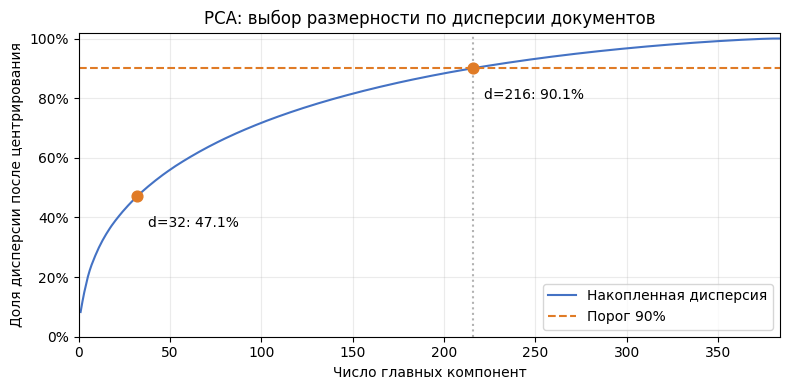

In [124]:
# Используем готовые результаты поиска: здесь только таблица и график спектра.
pca_summary_rows = [
    ("Original FlatIP", DIM, 1.0, exact_result[f"recall@{TOP_K}"], exact_result[f"qrels_recall@{TOP_K}"]),
    ("Centered FlatIP", DIM, 1.0, pca_centered_recall, pca_centered_qrels),
    (f"PCA d={pca.d_out}", pca.d_out, pca_cumulative_variance[pca.d_out - 1], pca_recall, pca_qrels_recall),
    (f"PCA variance >= {pca_target_variance:.0%}", pca_variance_dim, pca_cumulative_variance[pca_variance_dim - 1], pca_variance_recall, pca_variance_qrels),
]
pca_header = (
    f"{'representation':<20}  {'dimension':>9}  {'variance kept':>13}"
    f"  {f'ANN recall@{TOP_K}':>14}  {f'qrels recall@{TOP_K}':>16}"
)
print(pca_header)
print("-" * len(pca_header))
for name, dimension, variance, ann_recall, qrels_recall in pca_summary_rows:
    print(f"{name:<20}  {dimension:>9}  {variance:>13.2%}  {ann_recall:>14.4f}  {qrels_recall:>16.4f}")

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, DIM + 1), pca_cumulative_variance, color="#4472c4", label="Накопленная дисперсия")
ax.axhline(pca_target_variance, color="#e07b26", linestyle="--", label=f"Порог {pca_target_variance:.0%}")
ax.axvline(pca_variance_dim, color="gray", linestyle=":", alpha=0.6)
ax.scatter(
    [pca.d_out, pca_variance_dim],
    [pca_cumulative_variance[pca.d_out - 1], pca_cumulative_variance[pca_variance_dim - 1]],
    color="#e07b26", s=60, zorder=3,
)
ax.annotate(
    f"d={pca.d_out}: {pca_cumulative_variance[pca.d_out - 1]:.1%}",
    (pca.d_out, pca_cumulative_variance[pca.d_out - 1]),
    xytext=(8, -22), textcoords="offset points",
)
ax.annotate(
    f"d={pca_variance_dim}: {pca_cumulative_variance[pca_variance_dim - 1]:.1%}",
    (pca_variance_dim, pca_cumulative_variance[pca_variance_dim - 1]),
    xytext=(8, -22), textcoords="offset points",
)
ax.set_title("PCA: выбор размерности по дисперсии документов")
ax.set_xlabel("Число главных компонент")
ax.set_ylabel("Доля дисперсии после центрирования")
ax.set_xlim(0, DIM)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### OPQ: бюджет обучения и качество поиска

Сравним **2 и 50 внешних итераций OPQ** с IVF-PQ без преобразования. Две итерации — намеренно сокращённое обучение; 50 — стандартный бюджет `OPQMatrix` в используемой версии FAISS. Для всех трёх вариантов сохраняем `nlist=64`, `nprobe=16`, `PQ32x6`, метрику и весь корпус. ANN/qrels recall и задержки считаем на **всех запросах** через общий `benchmark`.

Здесь OPQ сохраняет размерность 384 и точный inner product с вычислительной погрешностью. Ни `is_trained`, ни 50 итераций не доказывают сходимость: ошибка реконструкции и качество поиска проверяются отдельно.

<details>
<summary>Как обучается OPQ → IVF-PQ и как оценивать результат</summary>

OPQ ищет преобразование, удобное для Product Quantization: чередует обучение PQ в преобразованном пространстве и обновление матрицы вращения. Здесь входная и выходная размерности равны `DIM=384`, поэтому ортогональное преобразование сохраняет точные inner product и нормы с точностью до вычислительной погрешности. Ошибки итогового поиска возникают при отборе IVF-списков и приближённой оценке скоров по PQ-кодам.

`niter` задаёт число внешних шагов OPQ. `niter_pq_0=40` задаёт число итераций кластеризации внутреннего PQ на первом шаге, `niter_pq=4` — на последующих. Эти два параметра одинаковы в обоих опытах: меняем только `niter`. Внутренний PQ для обучения OPQ явно делаем 6-битным и сохраняем ссылку на него. Это отдельный объект; финальный IVF-PQ обучает собственные кодовые книги на остатках относительно coarse-центроидов. Его параметры и seed совпадают с вариантом без OPQ.

Создаём необученные `OPQMatrix` и `IndexIVFPQ`, объединяем через `IndexPreTransform` и вызываем `train(docs)` у всей цепочки. Сначала обучается OPQ, затем преобразуется обучающая матрица и обучается внутренний IVF-PQ. Уже обученное преобразование `IndexPreTransform` применяет, но повторно не обучает; предварительный вызов `opq.train(docs)` не нужен. Это поведение описано в [реализации `IndexPreTransform::train`](https://github.com/facebookresearch/faiss/blob/v1.15.1/faiss/IndexPreTransform.cpp#L62-L120).

Два бюджета обучаются **с нуля в разных объектах**. Вторая цепочка не продолжает обучение первой. Таймер охватывает весь вызов `train`: OPQ, применение преобразования к обучающим векторам и обучение IVF-PQ. Создание объектов, `add`, сериализация и поиск находятся вне этого замера. Флаги `is_trained` показывают готовность параметров, но не подтверждают сходимость или достаточный recall.

Поиск передаёт исходный запрос внешнему `IndexPreTransform`, поэтому median/p95 включают преобразование запроса и поиск по IVF-PQ. Каждая строка получена на всех запросах тем же способом, что и IVF-PQ без OPQ. ANN recall сравнивает выдачу с исходным точным FlatIP, qrels recall — с разметкой SciFact. Размер файла включает матрицу OPQ и служебные структуры; сами PQ-коды по-прежнему занимают 24 байта на документ.

Дополнительно восстановим векторы из готовых индексов и посчитаем средний квадрат L2-ошибки: `mean(||x - reconstructed_x||²)`. Для цепочки `reconstruct_n` декодирует IVF-PQ и выполняет обратное преобразование OPQ, поэтому сравнение идёт в исходных координатах. Это ошибка **конечного индекса на обучающем корпусе**, а не независимая оценка обобщения и не значение внутренней целевой функции OPQ. Внутренний PQ OPQ и финальный residual PQ обучаются в разных условиях.

Больше итераций даёт больший бюджет оптимизации, но не гарантирует улучшения каждого показателя. OPQ оптимизирует ошибку реконструкции, а не qrels или recall@10; даже меньшая ошибка может переставить близких соседей. Две итерации не считаем подтверждением качества обучения, а стандартные 50 — гарантией сходимости. Рабочий бюджет выбирают по стабильности ошибки и качеству поиска на validation-запросах при подходящем размере обучающей выборки, затем фиксируют для итоговой проверки на отдельном test. Повторно используемые запросы семинара служат для демонстрации этих зависимостей.

</details>

In [125]:
# Сокращённый бюджет: две внешние итерации, отдельная цепочка с нуля.
opq_short = faiss.OPQMatrix(DIM, PQ_M)
opq_short_pq = faiss.ProductQuantizer(DIM, PQ_M, PQ_NBITS)
opq_short_pq.cp.seed = pq.pq.cp.seed
opq_short.pq = opq_short_pq
opq_short.niter = 2
opq_short.niter_pq_0 = 40
opq_short.niter_pq = 4

opq_short_ivf = faiss.IndexIVFPQ(
    faiss.IndexFlatIP(DIM), DIM, NLIST, PQ_M, PQ_NBITS, faiss.METRIC_INNER_PRODUCT
)
opq_short_ivf.cp.seed = pq.cp.seed
opq_short_ivf.pq.cp.seed = pq.pq.cp.seed
opq_short_ivf.by_residual = pq.by_residual
opq_short_index = faiss.IndexPreTransform(opq_short, opq_short_ivf)
print("OPQ iterations (outer / first PQ / later PQ):",
      opq_short.niter, opq_short.niter_pq_0, opq_short.niter_pq)
print("trained before (OPQ / chain):", opq_short.is_trained, opq_short_index.is_trained)

opq_short_train_started = perf_counter()
opq_short_index.train(docs)
opq_short_train_seconds = perf_counter() - opq_short_train_started
print("OPQ 2 + IVF-PQ training time, s:", round(opq_short_train_seconds, 3))
print("trained after (OPQ / chain):", opq_short.is_trained, opq_short_index.is_trained)

OPQ iterations (outer / first PQ / later PQ): 2 40 4
trained before (OPQ / chain): False False


OPQ 2 + IVF-PQ training time, s: 1.009
trained after (OPQ / chain): True True


In [126]:
# Добавление и поиск используют исходные векторы: OPQ применяет сама цепочка.
opq_short_index.add(docs)
opq_short_ivf.nprobe = 16
opq_short_ivf.max_codes = 0
opq_short_path = INDEX_DIR / "opq_2_ivf_pq.index"
faiss.write_index(opq_short_index, str(opq_short_path))

def opq_short_search(query, k):
    return opq_short_index.search(query.reshape(1, -1), k)[1][0]

opq_short_result, opq_short_ids = benchmark(
    "OPQ 2 iterations + IVF-PQ",
    opq_short_search,
    index_size_mb=file_size(opq_short_path),
)
print("indexed documents / evaluated queries:", opq_short_index.ntotal, len(queries))
print("nlist / nprobe / PQ M / PQ nbits:",
      opq_short_ivf.nlist, opq_short_ivf.nprobe, opq_short_ivf.pq.M, opq_short_ivf.pq.nbits)
print_results([exact_result, pq_result_16, opq_short_result], k=TOP_K)

indexed documents / evaluated queries: 5183 1109
nlist / nprobe / PQ M / PQ nbits: 64 16 32 6
index                      ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------------
exact / FlatIP                     1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=16                   0.504            0.753         0.049         0.055          0.35
OPQ 2 iterations + IVF-PQ          0.527            0.758         0.061         0.067          0.91


In [127]:
# Стандартный бюджет OPQ: 50 внешних итераций, новая необученная цепочка.
opq = faiss.OPQMatrix(DIM, PQ_M)
opq_pq = faiss.ProductQuantizer(DIM, PQ_M, PQ_NBITS)
opq_pq.cp.seed = pq.pq.cp.seed
opq.pq = opq_pq
opq.niter = 50
opq.niter_pq_0 = 40
opq.niter_pq = 4

opq_ivf = faiss.IndexIVFPQ(
    faiss.IndexFlatIP(DIM), DIM, NLIST, PQ_M, PQ_NBITS, faiss.METRIC_INNER_PRODUCT
)
opq_ivf.cp.seed = pq.cp.seed
opq_ivf.pq.cp.seed = pq.pq.cp.seed
opq_ivf.by_residual = pq.by_residual
opq_index = faiss.IndexPreTransform(opq, opq_ivf)
print("OPQ iterations (outer / first PQ / later PQ):", opq.niter, opq.niter_pq_0, opq.niter_pq)
print("trained before (OPQ / chain):", opq.is_trained, opq_index.is_trained)

opq_train_started = perf_counter()
opq_index.train(docs)
opq_train_seconds = perf_counter() - opq_train_started
print("OPQ 50 + IVF-PQ training time, s:", round(opq_train_seconds, 3))
print("trained after (OPQ / chain):", opq.is_trained, opq_index.is_trained)

OPQ iterations (outer / first PQ / later PQ): 50 40 4
trained before (OPQ / chain): False False


OPQ 50 + IVF-PQ training time, s: 6.709
trained after (OPQ / chain): True True


In [128]:
opq_index.add(docs)
opq_ivf.nprobe = 16
opq_ivf.max_codes = 0
opq_path = INDEX_DIR / "opq_50_ivf_pq.index"
faiss.write_index(opq_index, str(opq_path))

def opq_search(query, k):
    return opq_index.search(query.reshape(1, -1), k)[1][0]

opq_result, opq_ids = benchmark(
    "OPQ 50 iterations + IVF-PQ",
    opq_search,
    index_size_mb=file_size(opq_path),
)
print("indexed documents / evaluated queries:", opq_index.ntotal, len(queries))
print("OPQ input / output dimensions:", opq.d_in, opq.d_out)
print("nlist / nprobe / PQ M / PQ nbits:",
      opq_ivf.nlist, opq_ivf.nprobe, opq_ivf.pq.M, opq_ivf.pq.nbits)
print_results([exact_result, pq_result_16, opq_short_result, opq_result], k=TOP_K)

indexed documents / evaluated queries: 5183 1109
OPQ input / output dimensions: 384 384
nlist / nprobe / PQ M / PQ nbits: 64 16 32 6
index                       ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------------------
exact / FlatIP                      1.000            0.860         0.100         0.111          7.59
IVF-PQ nprobe=16                    0.504            0.753         0.049         0.055          0.35
OPQ 2 iterations + IVF-PQ           0.527            0.758         0.061         0.067          0.91
OPQ 50 iterations + IVF-PQ          0.579            0.770         0.055         0.066          0.91


In [129]:
# Диагностика после benchmark: сравниваем восстановленные векторы в исходных координатах.
pq_reconstructed = pq.reconstruct_n(0, len(docs))
opq_short_reconstructed = opq_short_index.reconstruct_n(0, len(docs))
opq_reconstructed = opq_index.reconstruct_n(0, len(docs))

pq_reconstruction_error = float(np.mean(np.sum((docs - pq_reconstructed) ** 2, axis=1)))
opq_short_reconstruction_error = float(np.mean(np.sum((docs - opq_short_reconstructed) ** 2, axis=1)))
opq_reconstruction_error = float(np.mean(np.sum((docs - opq_reconstructed) ** 2, axis=1)))

print("Mean squared L2 reconstruction error on training/indexed documents:")
print("IVF-PQ without OPQ:", round(pq_reconstruction_error, 6))
print("OPQ 2 iterations + IVF-PQ:", round(opq_short_reconstruction_error, 6))
print("OPQ 50 iterations + IVF-PQ:", round(opq_reconstruction_error, 6))

Mean squared L2 reconstruction error on training/indexed documents:
IVF-PQ without OPQ: 0.148941
OPQ 2 iterations + IVF-PQ: 0.136596
OPQ 50 iterations + IVF-PQ: 0.114015


## 12. Scalar Quantizer: `SQ8` и `IVFScalarQuantizer`

Scalar Quantizer квантует каждую координату независимо. **SQ8 хранит один байт на координату вместо четырёх у `float32`.** Сравним точный `IndexFlatIP`, полный перебор SQ8-кодов и IVF-SQ8 при `nprobe=16` через общий `benchmark`.

Полный просмотр SQ8-кодов остаётся приближённым по скорам: квантование уже изменило векторы. У IVF-SQ8 добавляются потери от выбора списков; сравниваем оба варианта с исходным точным FlatIP.

<details>
<summary>Что хранит SQ8 и как измеряются качество, время и размер</summary>

Product Quantization делит вектор на подпространства и хранит код каждой части. Scalar Quantizer квантует каждую координату отдельно: `QT_8bit` обучается на документах и подбирает для каждой координаты диапазон, кодируемый 256 уровнями. При восстановлении получаем приближённые значения, поэтому скоры и порядок соседей могут отличаться от `IndexFlatIP`.

Код SQ8-вектора занимает в четыре раза меньше места, чем исходный float32-вектор: при `DIM=384` это 384 байта вместо 1536. Полный файл индекса включает также параметры квантования и служебные данные, а IVF добавляет центроиды и ID документов в списках. Поэтому сравниваем отдельно размер кода и размер сериализованного индекса.

Все поисковые измерения используют одну модель, корпус, запросы, `TOP_K` и точный эталон. `benchmark` отправляет запросы по одному и считает median/p95 времени вызова Python-функции поиска, а также ANN recall и qrels recall. Эти поля имеют тот же смысл, что в таблицах Annoy, IVF и HNSW. Обучение, добавление векторов, сохранение файла и реконструкция выполняются вне поисковых таймеров.

В итоговую таблицу этого раздела собираем готовые результаты exact/SQ8/IVF-SQ8. Размер относится к сохранённому файлу; это не измерение пикового потребления RAM. Латентность измеряется на текущем компьютере, поэтому наличие сжатия само по себе не является обещанием более быстрого поиска.

</details>

In [130]:
sq8_type = faiss.ScalarQuantizer.QT_8bit
scalar = faiss.IndexScalarQuantizer(DIM, sq8_type, faiss.METRIC_INNER_PRODUCT)
if not scalar.is_trained:
    scalar.train(docs)
scalar.add(docs)
scalar_path = INDEX_DIR / "scalar.index"
faiss.write_index(scalar, str(scalar_path))

def scalar_search(query, k):
    return scalar.search(query.reshape(1, -1), k)[1][0]

scalar_result, scalar_I = benchmark(
    "FAISS SQ8",
    scalar_search,
    index_size_mb=file_size(scalar_path),
)

scalar_reconstructed = np.empty((1, DIM), dtype="float32")
scalar.reconstruct(0, scalar_reconstructed[0])
print("trained:", scalar.is_trained, "ntotal:", scalar.ntotal)
print("float32 bytes per vector:", DIM * docs.dtype.itemsize)
print("SQ8 code bytes per vector:", scalar.code_size)
print("SQ8 reconstruction error:", float(np.linalg.norm(scalar_reconstructed[0] - docs[0])))
print_results([exact_result, scalar_result], k=TOP_K)

trained: True ntotal: 5183
float32 bytes per vector: 1536
SQ8 code bytes per vector: 384
SQ8 reconstruction error: 0.00503488490357995
index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
FAISS SQ8               0.994            0.860         0.390         0.426          1.90


In [131]:
sq8_type = faiss.ScalarQuantizer.QT_8bit
ivf_sq = faiss.IndexIVFScalarQuantizer(
    faiss.IndexFlatIP(DIM), DIM, NLIST, sq8_type, faiss.METRIC_INNER_PRODUCT
)
# До обучения явно выбираем квантование остатков относительно coarse-центроидов.
ivf_sq.by_residual = True
ivf_sq.train(docs)
ivf_sq.add(docs)
ivf_sq.nprobe = 16
ivf_sq_path = INDEX_DIR / "ivf_sq.index"
faiss.write_index(ivf_sq, str(ivf_sq_path))

def ivf_sq_search(query, k):
    return ivf_sq.search(query.reshape(1, -1), k)[1][0]

ivf_sq_result, ivf_sq_I = benchmark(
    f"FAISS IVF-SQ8 nprobe={ivf_sq.nprobe}",
    ivf_sq_search,
    index_size_mb=file_size(ivf_sq_path),
)

print("IVF-SQ8 ntotal:", ivf_sq.ntotal)
print("IVF-SQ8 nlist / nprobe:", ivf_sq.nlist, ivf_sq.nprobe)
print("IVF-SQ8 by_residual:", ivf_sq.by_residual)
print("IVF-SQ8 code bytes per vector:", ivf_sq.code_size)
print_results([exact_result, ivf_sq_result], k=TOP_K)

IVF-SQ8 ntotal: 5183
IVF-SQ8 nlist / nprobe: 64 16
IVF-SQ8 by_residual: True
IVF-SQ8 code bytes per vector: 384
index                    ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------
exact / FlatIP                   1.000            0.860         0.100         0.111          7.59
FAISS IVF-SQ8 nprobe=16          0.954            0.840         0.098         0.111          2.03


### Exact, SQ8 и IVF-SQ8: итоговое сравнение

Сопоставим ANN/qrels recall, median/p95 одиночного поиска и размер файла для всех трёх вариантов.

В этом IVF-SQ8 явно задано `by_residual=True`: квантируются остатки относительно центроидов. Уменьшение файла и полный просмотр кодов сами по себе не гарантируют сохранения точных соседей.

<details>
<summary>Как интерпретировать различия между индексами</summary>

У `IndexScalarQuantizer` **нет IVF-списков**: он перебирает все квантованные векторы. Полный перебор здесь не означает точных скоров — из-за квантования ANN recall может быть ниже единицы.

`IndexIVFScalarQuantizer` распределяет документы по IVF-спискам и просматривает только `nprobe` из них. В этом примере перед обучением явно задаём `by_residual=True`: квантуем остаток вектора относительно центроида его списка. Значение настройки выводится в ячейке построения. У него две причины потери качества: пропущенные списки и ошибка квантования. Даже при `nprobe=NLIST` ошибка квантования остаётся.

В этом сравнении IVF-SQ8 просматривает 16 списков из 64. Его скорость оцениваем по измеренным median/p95, а допустимость потери качества — по ANN и qrels recall. Сокращение размера файла не гарантирует уменьшения задержки: на неё влияют объём просмотра кодов, расчёт скоров и накладные расходы поиска.

Все три строки используют уже полученные результаты `benchmark`; повторный поиск для этой таблицы не выполняется.

</details>

In [132]:
print_results([exact_result, scalar_result, ivf_sq_result], k=TOP_K)

index                    ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------
exact / FlatIP                   1.000            0.860         0.100         0.111          7.59
FAISS SQ8                        0.994            0.860         0.390         0.426          1.90
FAISS IVF-SQ8 nprobe=16          0.954            0.840         0.098         0.111          2.03


## 13. HNSW внутри FAISS

Внешний `hnswlib` — не единственный способ использовать HNSW. FAISS предоставляет `IndexHNSWFlat` с интерфейсом `add/search/write_index`. Это другая реализация того же алгоритма: одинаковые параметры в FAISS и hnswlib не означают одинаковый граф и выдачу.

Сравним `efSearch=16/64/128` на одном графе с `M=8`, затем `M=8` и `M=32` при общем `efSearch=64`. Во всех опытах `efConstruction=40`. Общий `benchmark` покажет ANN/qrels recall, median/p95 одиночного поиска и размер файла; стоимость построения измерим отдельно.

<details>
<summary>Параметры графа и протокол сравнения</summary>

`Flat` в названии означает хранение исходных float32-векторов без квантования. Скоры для посещённых векторов точные, но сам поиск приближённый: обход графа может не добраться до нужных документов. Обучение `train` не требуется, граф строится при `add`. Индекс хранит и векторы, и граф, поэтому требует больше памяти, чем `IndexFlatIP`.

`M` передаём в конструктор, а `efConstruction` и `efSearch` задаём через поле `index.hnsw`:

- `M` задаётся при создании и определяет лимиты связей. В стандартной конфигурации FAISS на нулевом уровне выделяется до `2 * M` соседей на вершину, на верхних — до `M`. Фактических соседей может быть меньше. Параметр влияет на размер графа и поиск.
- `efConstruction` задаёт ширину поиска соседей при добавлении векторов. Устанавливаем его перед `add`: изменение параметра после построения не перестроит существующий граф.
- `efSearch` управляет шириной поиска по готовому графу. Это не точное число посещаемых вершин. Его можно менять без перестроения; обычно больший бюджет улучшает recall ценой времени поиска, но не обязан менять выдачу каждого запроса.

`benchmark` отправляет все запросы по одному и измеряет длительность вызова Python-функции поиска, включая подготовку формы массива и получение результата FAISS. Из этих измерений получаются median и p95. ANN recall, qrels recall и `k` считаются так же, как для Annoy и IVF; используется тот же корпус, набор запросов и точный эталон. Построение и сохранение индекса выполняются до поисковых замеров.

Время построения — wall time от создания `IndexHNSWFlat` до завершения `add(docs)`, включая настройку параметров. Сохранение файла и поиск находятся вне этого таймера. Каждый из двух графов строится один раз; изменение `efSearch` не требует нового построения. В сводке отдельно показываем две стоимости построения и текущий лимит потоков OpenMP. Времена относятся к данному компьютеру и запуску.

`efSearch=128` задаём объектом `SearchParametersHNSW`, созданным до замеров. Он передаётся в каждый одиночный вызов `search`, а значение по умолчанию у индекса остаётся равным 64. Размер файла относится к тому же графу; параметры отдельного вызова его не изменяют.

В локальной и общей таблицах доступны все четыре настройки. При выборе рабочей конфигурации сопоставляют требуемый recall, median/p95, размер файла и стоимость построения. Сравнение `M=8/32` выполняется при одинаковых `efConstruction=40` и `efSearch=64`; три строки для `M=8` показывают влияние поискового бюджета на одном графе.

</details>

In [133]:
faiss_hnsw_small_started = perf_counter()
faiss_hnsw_small = faiss.IndexHNSWFlat(DIM, 8, faiss.METRIC_INNER_PRODUCT)
faiss_hnsw_small.hnsw.efConstruction = 40
faiss_hnsw_small.hnsw.efSearch = 16
faiss_hnsw_small.add(docs)
faiss_hnsw_small_build_s = perf_counter() - faiss_hnsw_small_started

faiss_hnsw_small_path = INDEX_DIR / "faiss_hnsw_small.index"
faiss.write_index(faiss_hnsw_small, str(faiss_hnsw_small_path))
faiss_hnsw_small_size = file_size(faiss_hnsw_small_path)

def faiss_hnsw_search_16(query, k):
    return faiss_hnsw_small.search(query.reshape(1, -1), k)[1][0]

faiss_hnsw_result_16, hnsw_small_I = benchmark(
    "FAISS HNSW M=8 ef=16",
    faiss_hnsw_search_16,
    index_size_mb=faiss_hnsw_small_size,
)

print("M=8, efConstruction=40, efSearch=16")
print("build time, s:", round(faiss_hnsw_small_build_s, 3))
print("neighbor limits at levels 0 and 1:",
      faiss_hnsw_small.hnsw.nb_neighbors(0), faiss_hnsw_small.hnsw.nb_neighbors(1))
print_results([exact_result, faiss_hnsw_result_16], k=TOP_K)

M=8, efConstruction=40, efSearch=16
build time, s: 0.038
neighbor limits at levels 0 and 1: 16 8
index                 ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------------
exact / FlatIP                1.000            0.860         0.100         0.111          7.59
FAISS HNSW M=8 ef=16          0.859            0.792         0.010         0.015          7.99


In [134]:
faiss_hnsw_small.hnsw.efSearch = 64
# Сохраняем индекс заново: сравниваем размеры файлов до и после изменения.
faiss.write_index(faiss_hnsw_small, str(faiss_hnsw_small_path))
faiss_hnsw_ef64_size = file_size(faiss_hnsw_small_path)

def faiss_hnsw_search_64(query, k):
    return faiss_hnsw_small.search(query.reshape(1, -1), k)[1][0]

faiss_hnsw_result_64, hnsw_ef64_I = benchmark(
    "FAISS HNSW M=8 ef=64",
    faiss_hnsw_search_64,
    index_size_mb=faiss_hnsw_ef64_size,
)

print("same graph: M=8, efConstruction=40, efSearch=64")
print("serialized size unchanged:", faiss_hnsw_ef64_size == faiss_hnsw_small_size)
print_results([exact_result, faiss_hnsw_result_64], k=TOP_K)

same graph: M=8, efConstruction=40, efSearch=64
serialized size unchanged: True
index                 ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------------
exact / FlatIP                1.000            0.860         0.100         0.111          7.59
FAISS HNSW M=8 ef=64          0.962            0.842         0.027         0.035          7.99


In [135]:
# Параметры передаются в каждый одиночный search внутри benchmark.
# Значение efSearch по умолчанию у самого индекса остаётся равным 64.
hnsw_params = faiss.SearchParametersHNSW()
hnsw_params.efSearch = 128

def faiss_hnsw_search_128(query, k):
    return faiss_hnsw_small.search(
        query.reshape(1, -1), k, params=hnsw_params
    )[1][0]

faiss_hnsw_result_128, params_I = benchmark(
    "FAISS HNSW M=8 ef=128",
    faiss_hnsw_search_128,
    index_size_mb=faiss_hnsw_ef64_size,
)

print("per-call efSearch:", hnsw_params.efSearch)
print("index efSearch after search:", faiss_hnsw_small.hnsw.efSearch)
print_results([exact_result, faiss_hnsw_result_128], k=TOP_K)

per-call efSearch: 128
index efSearch after search: 64
index                  ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------
exact / FlatIP                 1.000            0.860         0.100         0.111          7.59
FAISS HNSW M=8 ef=128          0.984            0.854         0.055         0.065          7.99


In [136]:
# Меняем только M относительно опыта с M=8 и efSearch=64.
faiss_hnsw_large_started = perf_counter()
faiss_hnsw_large = faiss.IndexHNSWFlat(DIM, 32, faiss.METRIC_INNER_PRODUCT)
faiss_hnsw_large.hnsw.efConstruction = 40
faiss_hnsw_large.hnsw.efSearch = 64
faiss_hnsw_large.add(docs)
faiss_hnsw_large_build_s = perf_counter() - faiss_hnsw_large_started

faiss_hnsw_large_path = INDEX_DIR / "faiss_hnsw_large.index"
faiss.write_index(faiss_hnsw_large, str(faiss_hnsw_large_path))
faiss_hnsw_large_size = file_size(faiss_hnsw_large_path)

def faiss_hnsw_m32_search(query, k):
    return faiss_hnsw_large.search(query.reshape(1, -1), k)[1][0]

faiss_hnsw_m32_result, large_I = benchmark(
    "FAISS HNSW M=32 ef=64",
    faiss_hnsw_m32_search,
    index_size_mb=faiss_hnsw_large_size,
)

print("M=32, efConstruction=40, efSearch=64")
print("build time, s:", round(faiss_hnsw_large_build_s, 3))
print_results([exact_result, faiss_hnsw_m32_result], k=TOP_K)

M=32, efConstruction=40, efSearch=64
build time, s: 0.045
index                  ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------
exact / FlatIP                 1.000            0.860         0.100         0.111          7.59
FAISS HNSW M=32 ef=64          0.996            0.860         0.047         0.060          8.93


In [137]:
# Используем готовые результаты: повторного построения и поиска здесь нет.
print_results([
    exact_result,
    faiss_hnsw_result_16,
    faiss_hnsw_result_64,
    faiss_hnsw_result_128,
    faiss_hnsw_m32_result,
], k=TOP_K)

print("\nGraph construction (constructor + add):")
print(f"{'M':>3}  {'efConstruction':>14}  {'build seconds':>13}")
print(f"{8:>3}  {40:>14}  {faiss_hnsw_small_build_s:>13.3f}")
print(f"{32:>3}  {40:>14}  {faiss_hnsw_large_build_s:>13.3f}")
print("OpenMP thread limit:", faiss.omp_get_max_threads())

index                  ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------
exact / FlatIP                 1.000            0.860         0.100         0.111          7.59
FAISS HNSW M=8 ef=16           0.859            0.792         0.010         0.015          7.99
FAISS HNSW M=8 ef=64           0.962            0.842         0.027         0.035          7.99
FAISS HNSW M=8 ef=128          0.984            0.854         0.055         0.065          7.99
FAISS HNSW M=32 ef=64          0.996            0.860         0.047         0.060          8.93

Graph construction (constructor + add):
  M  efConstruction  build seconds
  8              40          0.038
 32              40          0.045
OpenMP thread limit: 12


## 14. Расширенный `index_factory`

Строка фабрики индексов описывает структуру индекса: преобразования, coarse quantizer и способ хранения векторов.

**`OPQ8_64` уменьшает размерность с 384 до 64, а не только поворачивает пространство.** `PQ8x6` добавляет сжатие до 6 байт кода; inner product после проекции уже не равен cosine similarity исходных эмбеддингов.

<details>
<summary>Подробнее о цепочке OPQ → IVF → PQ и оценке качества</summary>

`OPQ8_64,IVF32,PQ8x6` разбирается слева направо:

- `OPQ8_64` — обучаемое преобразование в 64-мерное пространство, рассчитанное на PQ с восемью подпространствами. Для наших 384-мерных эмбеддингов это **уменьшение размерности**, а не только поворот.
- `IVF32` — распределение преобразованных векторов по 32 IVF-спискам.
- `PQ8x6` — восемь частей по 6 бит: 48 бит, или **6 байтов кода на вектор**. Это не полный расход памяти: дополнительно хранятся ID, кодовые книги, центроиды и преобразование.

Метрика передаётся отдельным аргументом `index_factory`; ниже используем inner product. Внешний `IndexPreTransform` принимает исходные векторы размерности `DIM` и сам применяет обученное преобразование при `add` и `search`. Внутренний IVF-PQ работает уже с размерностью 64. Чтобы задать `nprobe`, получаем именно внутренний IVF-индекс через `extract_index_ivf`.

Строка не описывает все настройки обучения. У `OPQMatrix` есть внутренний PQ для обучения преобразования; по умолчанию он 8-битный, даже если в конце строки указано `PQ8x6`. Поэтому явно задаём 6-битный PQ и для OPQ и сохраняем ссылку на этот объект. Для 64 центроид на подпространство рекомендация FAISS составляет `39 * 64 = 2496` обучающих векторов, а у нас их 5183. Это устраняет предупреждение о размере обучающей выборки, но не гарантирует высокого recall.

Снижение размерности меняет скоры и нормы векторов. **Inner product после OPQ64 уже не равен cosine similarity исходных эмбеддингов.** ANN recall относительно исходного `IndexFlatIP` показывает суммарное влияние проекции, отбора IVF-списков и PQ. Отдельным точным поиском после OPQ посмотрим, как изменилась выдача ещё до IVF и PQ.

</details>


In [138]:
factory_description = f"OPQ8_64,IVF32,PQ8x{PQ_NBITS}"
factory_chain = faiss.index_factory(
    DIM, factory_description, faiss.METRIC_INNER_PRODUCT
)
# Настраиваем отдельный PQ, с которым OPQ обучает преобразование.
# Сохраняем ссылку factory_opq_pq на всё время его использования.
factory_opq = faiss.downcast_VectorTransform(factory_chain.chain.at(0))
factory_opq_pq = faiss.ProductQuantizer(factory_opq.d_out, factory_opq.M, PQ_NBITS)
factory_opq.pq = factory_opq_pq

print("outer type:", type(factory_chain).__name__)
print("is trained:", factory_chain.is_trained)
print("factory description:", factory_description)
print("OPQ input / output dimensions:", factory_opq.d_in, factory_opq.d_out)
print("OPQ training PQ bits per subspace:", factory_opq_pq.nbits)

outer type: IndexPreTransform
is trained: False
factory description: OPQ8_64,IVF32,PQ8x6
OPQ input / output dimensions: 384 64
OPQ training PQ bits per subspace: 6


In [139]:
# Обучаем цепочку и передаём исходные docs: повторять OPQ вручную не нужно.
factory_chain.train(docs)
factory_chain.add(docs)
# downcast показывает конкретный класс внутреннего индекса — IndexIVFPQ.
factory_chain_ivf = faiss.downcast_index(faiss.extract_index_ivf(factory_chain))
factory_chain_ivf.nprobe = 8
factory_chain_D, factory_chain_I = factory_chain.search(query_matrix, TOP_K)
factory_chain_path = INDEX_DIR / "factory_chain.index"
faiss.write_index(factory_chain, str(factory_chain_path))
print("trained:", factory_chain.is_trained, "ntotal:", factory_chain.ntotal)
print("inner IVF type:", type(factory_chain_ivf).__name__)
print("outer / inner dimensions:", factory_chain.d, factory_chain_ivf.d)
print("IVF nlist / nprobe:", factory_chain_ivf.nlist, factory_chain_ivf.nprobe)
print("final PQ bits per subspace:", factory_chain_ivf.pq.nbits)
print("PQ code bytes per vector:", factory_chain_ivf.code_size)
print("serialized size MiB:", round(file_size(factory_chain_path), 2))
print("ANN recall@10 vs original FlatIP, all queries:", round(
    recall_at_k(factory_chain_I, exact_ids), 3
))

trained: True ntotal: 5183
inner IVF type: IndexIVFPQ
outer / inner dimensions: 384 64
IVF nlist / nprobe: 32 8
final PQ bits per subspace: 6
PQ code bytes per vector: 6
serialized size MiB: 0.19
ANN recall@10 vs original FlatIP, all queries: 0.288


In [140]:
# Диагностика: точный перебор в том же пространстве OPQ64, без IVF и PQ.
# Только для этой проверки применяем преобразование вручную к docs и queries.
factory_opq_docs = factory_opq.apply_py(docs)
factory_opq_queries = factory_opq.apply_py(query_matrix)
factory_opq_exact = faiss.IndexFlatIP(factory_opq.d_out)
factory_opq_exact.add(factory_opq_docs)
factory_opq_exact_D, factory_opq_exact_I = factory_opq_exact.search(
    factory_opq_queries, TOP_K
)
print("Exact OPQ64 recall@10 vs original FlatIP, all queries:", round(
    recall_at_k(factory_opq_exact_I, exact_ids), 3
))
print("Full chain ANN recall@10 vs exact OPQ64, all queries:", round(
    recall_at_k(factory_chain_I, factory_opq_exact_I), 3
))
factory_opq_norms = np.linalg.norm(factory_opq_docs, axis=1)
print("OPQ64 document norm min / max:",
      factory_opq_norms.min().round(3), factory_opq_norms.max().round(3))

Exact OPQ64 recall@10 vs original FlatIP, all queries: 0.541
Full chain ANN recall@10 vs exact OPQ64, all queries: 0.382
OPQ64 document norm min / max: 0.413 0.684


### Цепочка с PCA

`PCA32,IVF32,Flat` хранит векторы в 32 измерениях. `Flat` внутри цепочки не отменяет ни потери от PCA, ни пропуски IVF-списков; метрика в новом пространстве отличается от исходной.

<details>
<summary>Подробнее о PCA, метрике и интерпретации recall</summary>

`PCA32,IVF32,Flat` тоже принимает исходные 384-мерные векторы. PCA центрирует их и уменьшает размерность до 32, IVF распределяет результат по 32 спискам, а `Flat` хранит **32-мерные** векторы без дополнительного квантования. `Flat` внутри этой цепочки не восстанавливает исходные 384 координаты и не делает весь поиск точным: остаются потери от PCA и отбора IVF-списков.

Используем inner product и явно задаём `nprobe=8`. L2 здесь тоже допустим, но после PCA нормы документов уже не обязаны быть единичными, поэтому L2 и inner product могут давать разный порядок соседей. Нормализация после проекции дала бы cosine similarity в новом пространстве, а не вернула исходную геометрию.

Обе строки в разделе показывают, как составлять цепочки. Их небольшие размерности и короткий PQ-код не являются рекомендацией по параметрам для SciFact: качество проверяем на всех запросах. В примерах с OPQ отдельно подписаны два эталона: исходный FlatIP оценивает общую потерю соседей, а точный OPQ64 — приближение поиска после уже выполненного преобразования.

</details>


In [141]:
# Сохраняем inner product, как в предыдущей цепочке, и задаём nprobe явно.
factory_pca = faiss.index_factory(DIM, "PCA32,IVF32,Flat", faiss.METRIC_INNER_PRODUCT)
factory_pca.train(docs)
factory_pca.add(docs)
factory_pca_ivf = faiss.downcast_index(faiss.extract_index_ivf(factory_pca))
factory_pca_ivf.nprobe = 8
factory_pca_D, factory_pca_I = factory_pca.search(query_matrix, TOP_K)
factory_pca_path = INDEX_DIR / "factory_pca.index"
faiss.write_index(factory_pca, str(factory_pca_path))
print("PCA factory type:", type(factory_pca).__name__)
print("inner IVF type:", type(factory_pca_ivf).__name__)
print("outer / inner dimensions:", factory_pca.d, factory_pca_ivf.d)
print("IVF nlist / nprobe:", factory_pca_ivf.nlist, factory_pca_ivf.nprobe)
print("factory PCA ntotal:", factory_pca.ntotal)
print("serialized size MiB:", round(file_size(factory_pca_path), 2))
print("ANN recall@10 vs original FlatIP, all queries:", round(
    recall_at_k(factory_pca_I, exact_ids), 3
))

PCA factory type: IndexPreTransform
inner IVF type: IndexIVFFlat
outer / inner dimensions: 384 32
IVF nlist / nprobe: 32 8
factory PCA ntotal: 5183
serialized size MiB: 1.29
ANN recall@10 vs original FlatIP, all queries: 0.318


## 15. Автотюнинг через `ParameterSpace`: скорость при заданном recall

Подберём самый быстрый вариант поиска для готового IVF-индекса при **ANN recall@10 не ниже 0.95**. FAISS измерит конфигурации, а выбранную настройку проверим на отдельных запросах.

**Параметр выбираем по 200 запросам; остальные используем только для контроля в этом опыте.** Это локальное учебное разбиение уже исследуемой коллекции, а не независимый итоговый тест; по контрольному результату настройку повторно не подбираем. Критерий — ANN recall, он не использует qrels.

<details>
<summary>Что именно подбираем и как устроена проверка</summary>

Практическая задача: индекс уже построен, но значение `nprobe` ещё нужно выбрать. Маленькое значение ускоряет поиск и теряет соседей; большое повышает полноту и увеличивает объём работы. Требование к качеству задаём заранее: сохранить в среднем не менее 95% точных соседей из top-10.

`ParameterSpace` умеет не только применять строку вроде `nprobe=16`. Метод **`explore` выполняет поиск с разными настройками, измеряет качество и время и возвращает `OperatingPoints`**. Затем выбираем самый быстрый из измеренных вариантов, удовлетворяющих порогу, и явно применяем его к индексу. Метод `initialize` сам по себе ничего не подбирает.

Для качества используем `IntersectionCriterion`: долю общих документов между найденным и точным top-10, усреднённую по запросам. Это тот же ANN recall@10, который считает наша функция `recall_at_k`. `OneRecallAtRCriterion` измерял бы другое: попал ли единственный ближайший сосед в top-R. Ни один из этих критериев не использует SciFact qrels и не оценивает семантическую релевантность модели.

Случайно перемешиваем все загруженные запросы с фиксированным seed: первые 200 используем для подбора, остальные — для контрольной проверки (сейчас их 909). Это локальное разбиение размеченных запросов SciFact, не официальный validation split. Контрольные запросы не передаём в `explore` и не используем при выборе параметров в этом опыте. Они встречались в других демонстрациях ноутбука, поэтому эту проверку нельзя считать независимым финальным тестом всей разработки.

Настраиваем копию уже обученного `IndexIVFFlat`. Число списков, векторы и размер индекса фиксированы: здесь подбираются параметры поиска, а не архитектура и обучение индекса.

</details>

In [142]:
TARGET_ANN_RECALL = 0.95

# Отдельная копия: подбор меняет параметры индекса во время экспериментов.
tuning_index = faiss.clone_index(ivf)

np.random.seed(SEED)
tuning_order = np.random.permutation(len(query_matrix))
tuning_positions = tuning_order[:200]
holdout_positions = tuning_order[200:]
tuning_queries = query_matrix[tuning_positions]
holdout_queries = query_matrix[holdout_positions]

print("index:", type(tuning_index).__name__, "nlist:", tuning_index.nlist)
print("queries for tuning:", len(tuning_queries))
print("queries for holdout:", len(holdout_queries))
print("target ANN recall@10:", TARGET_ANN_RECALL)

index: IndexIVFFlat nlist: 64
queries for tuning: 200
queries for holdout: 909
target ANN recall@10: 0.95


In [143]:
parameter_space = faiss.ParameterSpace()
parameter_space.initialize(tuning_index)
nprobe_range = parameter_space.add_range("nprobe")
print("nprobe values from initialize:", faiss.vector_to_array(nprobe_range.values).astype(int).tolist())

# initialize не включает nprobe=nlist. Добавляем полный просмотр списков
# как контрольный вариант с точным поиском для нашего IndexIVFFlat.
nprobe_range.values.push_back(tuning_index.nlist)
print("nprobe values for tuning:", faiss.vector_to_array(nprobe_range.values).astype(int).tolist())
print("number of configurations:", parameter_space.n_combinations())

nprobe values from initialize: [1, 2, 4, 8, 16, 32]
nprobe values for tuning: [1, 2, 4, 8, 16, 32, 64]
number of configurations: 7


In [144]:
# Эталон — точные top-10 только для запросов, участвующих в подборе.
tuning_criterion = faiss.IntersectionCriterion(len(tuning_queries), TOP_K)
tuning_criterion.set_groundtruth(None, exact_ids[tuning_positions])

# Запросы выполняются по одному, последовательно, внутри C++.
parameter_space.batchsize = 1
parameter_space.thread_over_batches = False
# Положительный бюджет включает повторные измерения и эвристики explore.
parameter_space.n_experiments = parameter_space.n_combinations()
parameter_space.min_test_duration = 0.2
parameter_space.verbose = 0

tuning_started = perf_counter()
operating_points = parameter_space.explore(tuning_index, tuning_queries, tuning_criterion)
print("measured configurations:", operating_points.all_pts.size(),
      "/", parameter_space.n_combinations())
print("tuning elapsed seconds:", round(perf_counter() - tuning_started, 2))
print("FAISS threads:", faiss.omp_get_max_threads())

measured configurations: 7 / 7
tuning elapsed seconds: 1.41
FAISS threads: 12


In [145]:
tuning_points = [
    operating_points.all_pts.at(i)
    for i in range(operating_points.all_pts.size())
]
# FAISS добавляет служебную точку «ничего не искать»: cno=-1, recall=0, time=0.
# Она не является конфигурацией индекса, поэтому исключаем её из списка.
tuning_pareto = [
    operating_points.optimal_pts.at(i)
    for i in range(operating_points.optimal_pts.size())
    if operating_points.optimal_pts.at(i).cno >= 0
]
pareto_keys = {point.key for point in tuning_pareto}

config_width = max([len("parameters")] + [len(point.key) for point in tuning_points])
header = (
    f"{'parameters':<{config_width}}  {'ANN recall':>10}  {'mean ms/query':>14}"
    f"  {'Pareto':>7}  {'meets target':>12}"
)
print(header)
print("-" * len(header))
# Здесь только выводим измерения: поиск по конфигурациям уже выполнил explore.
for point in sorted(tuning_points, key=lambda point: point.cno):
    # explore возвращает секунды на проход по всем запросам для подбора.
    mean_ms = point.t * 1000 / len(tuning_queries)
    print(
        f"{point.key:<{config_width}}  {point.perf:>10.3f}  {mean_ms:>14.4f}"
        f"  {str(point.key in pareto_keys):>7}  {str(point.perf >= TARGET_ANN_RECALL):>12}"
    )

parameters  ANN recall   mean ms/query   Pareto  meets target
-------------------------------------------------------------
nprobe=1         0.464          0.0042     True         False
nprobe=2         0.611          0.0062     True         False
nprobe=4         0.761          0.0100     True         False
nprobe=8         0.877          0.0175     True         False
nprobe=16        0.954          0.0318     True          True
nprobe=32        0.994          0.0591     True          True
nprobe=64        1.000          0.1122     True          True


In [146]:
# Из подходящих точек выбираем самую быструю по измерениям на tuning-запросах.
best_point = min(
    (point for point in tuning_pareto if point.perf >= TARGET_ANN_RECALL),
    key=lambda point: point.t,
)
selected_parameters = best_point.key

# explore оставляет последнюю проверенную настройку, а не обязательно лучшую.
parameter_space.set_index_parameters(tuning_index, selected_parameters)
tuned_index_path = INDEX_DIR / "autotuned_ivf.index"
faiss.write_index(tuning_index, str(tuned_index_path))
print("selected parameters:", selected_parameters)
print("tuning ANN recall@10:", round(best_point.perf, 3))
print("tuning mean ms/query:", round(best_point.t * 1000 / len(tuning_queries), 4))
print("saved:", tuned_index_path)

selected parameters: nprobe=16
tuning ANN recall@10: 0.954
tuning mean ms/query: 0.0318
saved: indexes/autotuned_ivf.index


In [147]:
# Впервые проверяем выбранный вариант на запросах, не участвовавших в подборе.
holdout_D, holdout_I = tuning_index.search(holdout_queries, TOP_K)
holdout_recall = recall_at_k(holdout_I, exact_ids[holdout_positions])
print("selected parameters:", selected_parameters)
print("holdout queries:", len(holdout_queries))
print("holdout ANN recall@10:", round(holdout_recall, 3))
print("holdout meets target:", holdout_recall >= TARGET_ANN_RECALL)

selected parameters: nprobe=16
holdout queries: 909
holdout ANN recall@10: 0.958
holdout meets target: True


**Время в таблице — среднее на запрос внутри C++**, без Python-обвязки, а не median/p95 задержки сервиса. Выбранная настройка лучшая только среди измеренных допустимых вариантов; контрольный recall может не достичь заданного порога.

<details>
<summary>Как читать результаты, измеренное время и границу Парето</summary>

Каждая строка таблицы — реально измеренная конфигурация. `Pareto=True` означает, что среди измеренных вариантов нет другого с не меньшим recall и не большим временем, который был бы строго лучше хотя бы по одному из этих показателей. Такие варианты образуют границу Парето. Единственной «лучшей настройки» без требования к качеству нет: быстрый поиск с низким recall и медленный с высоким recall решают разные задачи. Для одного параметра `nprobe` все строки могут оказаться на границе: каждый прирост качества сопровождается увеличением времени. Это нормальный результат, а порог recall позволяет выбрать подходящий вариант.

Мы выбираем минимальное измеренное время среди точек с `recall >= TARGET_ANN_RECALL`. Это выбор из заданного пространства на текущем компьютере и текущих запросах. Он не доказывает оптимальность среди всех целых `nprobe`, других структур индекса или другой нагрузки. `explore` использует эвристики для пропуска заведомо невыгодных по его оценке вариантов, поэтому отдельно выводим число фактически измеренных конфигураций.

При `batchsize=1` FAISS последовательно выполняет отдельные запросы. `min_test_duration=0.2` заставляет повторять проходы, чтобы уменьшить влияние случайных колебаний. В FAISS 1.15.1 для этого нужен положительный `n_experiments`: ветка `n_experiments=0` перебирает все комбинации с одиночным замером и не использует этот режим повторов.

В результатах `explore` поле `t` содержит **секунды на один проход по всем запросам для подбора**. Переводим в миллисекунды и делим на число запросов. Получается среднее время поиска в C++ при последовательной обработке, без Python-обвязки каждого запроса. Это не median, не p95 и не полная задержка сервиса. Реализацию измерений можно сверить в [AutoTune.cpp для FAISS 1.15.1](https://github.com/facebookresearch/faiss/blob/v1.15.1/faiss/AutoTune.cpp#L694).

Контрольный recall может отличаться от recall на запросах для подбора. Если выбранная конфигурация не достигла порога на контрольных запросах, это нужно показать как результат проверки, а не незаметно подобрать другой параметр на тех же контрольных данных.

Здесь меняется только `nprobe`. Для выбора `nlist`, размерности, PQ-кода или `M` HNSW потребуется построение и сравнение разных индексов. О механизме подбора и `OperatingPoints` подробнее написано в [документации FAISS](https://github.com/facebookresearch/faiss/wiki/Index-IO,-cloning-and-hyper-parameter-tuning#auto-tuning-the-runtime-parameters).

</details>

## 16. Жизненный цикл IVF: удаление, DirectMap и обновление

FAISS поддерживает удаление и обновление для части индексов. На копии `IndexIVFFlat` удалим ID `0..9` и проверим поиск, число записей, размер файла и DirectMap после загрузки. Для полного просмотра зададим `nprobe=nlist` и `max_codes=0` — без ограничения числа просмотренных кодов.

Для этого удаления используем `DirectMap.Hashtable`; вызов `make_direct_map()` переключил бы карту в `Array`. Уменьшение сохранённого файла после удаления не доказывает немедленного освобождения оперативной памяти процесса.

<details>
<summary>Что меняется при удалении: выдача, списки, файл и DirectMap</summary>

`remove_ids` удаляет документы с выбранными ID. Оставшиеся ID в этом IVF-индексе не перенумеровываются. Запросом служит вектор документа 0: до удаления сам документ присутствует в выдаче, после удаления его заменяют другие соседи.

Удаление не означает, что в обычном top-k сразу появятся пустые позиции. Пока найдено достаточно оставшихся документов, выдача заполняется ими. Отдельно запросим столько результатов, сколько документов было до удаления: теперь живых документов меньше, и хвост выдачи заполняется `-1`. Это служебная метка незаполненной позиции, а не ID удалённого документа. В этом опыте просматриваются все списки, фильтров нет, поэтому нехватка результатов объясняется числом оставшихся записей. Скоры позиций с ID `-1` не интерпретируем как близость к документу.

Для удаления с обратной картой используем **`DirectMap.Hashtable`**. Она связывает ID с номером IVF-списка и позицией внутри него. Передаём `remove_ids` массив `int64`; Python-обёртка FAISS выбирает для Hashtable подходящий `IDSelectorArray`. Удалённый ID исчезает из карты, а положения перемещённых записей обновляются. После загрузки файла проверим отсутствие удалённого ключа и реконструкцию оставшегося документа.

`make_direct_map()` создаёт **`DirectMap.Array`**, рассчитанную на последовательные ID. Она не поддерживает этот путь удаления. Поэтому после `set_direct_map_type(DirectMap.Hashtable)` не вызываем `make_direct_map()`: это переключило бы тип обратно в Array. Пример `update_vectors` ниже использует отдельную копию исходного индекса с Array; удаление в первой копии на него не влияет.

В показанном `IndexIVFFlat` с обычными списками в памяти `remove_ids` удаляет сами записи списков. Для заполнения освободившегося места может перемещаться последняя запись списка; DirectMap учитывает новое положение. Проверяем не только `ntotal`, но и сумму числа записей во всех списках. При повторной сериализации удалённые коды, ID и записи карты уже не попадают в файл, поэтому он становится меньше.

**Tombstone** — другой способ удаления: запись сохраняется, но помечается как удалённая. В таких системах отдельная компакция позже убирает помеченные записи и перестраивает хранение. В этой операции FAISS IVF такой этап не требуется для уменьшения числа записей списков. При этом уменьшение списков или файла не означает немедленного уменьшения RSS процесса: внутренние буферы и аллокатор могут сохранить выделенную память. Мы измеряем размер готовых файлов, а не освобождённую RAM.

</details>

In [148]:
mutable_ivf = faiss.clone_index(ivf)
mutable_ivf.set_direct_map_type(faiss.DirectMap.Hashtable)
mutable_ivf.nprobe = mutable_ivf.nlist
mutable_ivf.max_codes = 0  # Без ограничения числа просмотренных кодов.
ids_to_remove = np.arange(10, dtype="int64")
remove_query = docs[:1]
ivf_before_count = mutable_ivf.ntotal
remove_before_D, remove_before_I = mutable_ivf.search(remove_query, TOP_K)

ivf_before_path = INDEX_DIR / "ivf_before_remove.index"
faiss.write_index(mutable_ivf, str(ivf_before_path))
ivf_before_bytes = ivf_before_path.stat().st_size

print("ntotal / records in IVF lists before:", mutable_ivf.ntotal, mutable_ivf.invlists.compute_ntotal())
print("DirectMap.Hashtable:", mutable_ivf.direct_map.type == faiss.DirectMap.Hashtable)
print("IDs to remove:", ids_to_remove.tolist())
print("query before removal:", remove_before_I[0].tolist())
print("document 0 found before removal:", 0 in remove_before_I[0])
print("serialized bytes before:", ivf_before_bytes)

ntotal / records in IVF lists before: 5183 5183
DirectMap.Hashtable: True
IDs to remove: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
query before removal: [0, 579, 2963, 1316, 268, 259, 3277, 4673, 1515, 3809]
document 0 found before removal: True
serialized bytes before: 8184443


In [149]:
# Для DirectMap.Hashtable передаём массив ID; обёртка создаст IDSelectorArray.
removed_count = mutable_ivf.remove_ids(ids_to_remove)
remove_after_D, remove_after_I = mutable_ivf.search(remove_query, TOP_K)

ivf_after_path = INDEX_DIR / "ivf_after_remove.index"
faiss.write_index(mutable_ivf, str(ivf_after_path))
ivf_after_bytes = ivf_after_path.stat().st_size

print("removed count:", removed_count)
print("ntotal / records in IVF lists after:", mutable_ivf.ntotal, mutable_ivf.invlists.compute_ntotal())
print("query after removal:", remove_after_I[0].tolist())
print("deleted IDs absent from top-k:", not np.isin(remove_after_I, ids_to_remove).any())
print("filled positions in ordinary top-k:", int((remove_after_I >= 0).sum()))
print("serialized bytes after:", ivf_after_bytes)
print("file size decrease, bytes:", ivf_before_bytes - ivf_after_bytes)

removed count: 10
ntotal / records in IVF lists after: 5173 5173
query after removal: [579, 2963, 1316, 268, 259, 3277, 4673, 1515, 3809, 3547]
deleted IDs absent from top-k: True
filled positions in ordinary top-k: 10
serialized bytes after: 8168843
file size decrease, bytes: 15600


In [150]:
# Для проверки неполной выдачи просим столько результатов, сколько было документов.
remove_all_D, remove_all_I = mutable_ivf.search(remove_query, ivf_before_count)
remaining_ids = remove_all_I[0][remove_all_I[0] >= 0]
expected_remaining_ids = np.setdiff1d(np.arange(ivf_before_count), ids_to_remove)

print("requested k:", ivf_before_count)
print("returned document IDs:", len(remaining_ids))
print("unfilled positions (-1):", int((remove_all_I == -1).sum()))
print("last IDs:", remove_all_I[0, -(len(ids_to_remove) + 2):].tolist())
print("all surviving IDs preserved:", np.array_equal(np.sort(remaining_ids), expected_remaining_ids))

requested k: 5183
returned document IDs: 5173
unfilled positions (-1): 10
last IDs: [5139, 1116, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
all surviving IDs preserved: True


In [151]:
# Проверяем удаление и DirectMap уже в индексе, загруженном из нового файла.
direct_map_ivf = faiss.read_index(str(ivf_after_path))
reloaded_remove_D, reloaded_remove_I = direct_map_ivf.search(remove_query, TOP_K)
print("restored ntotal:", direct_map_ivf.ntotal)
print("restored DirectMap.Hashtable:", direct_map_ivf.direct_map.type == faiss.DirectMap.Hashtable)
print("same top-k after reload:", np.array_equal(reloaded_remove_I, remove_after_I))

# Для удалённого ID ожидаем именно отсутствие ключа, а не произвольную ошибку.
try:
    direct_map_ivf.direct_map.get(int(ids_to_remove[0]))
except RuntimeError as error:
    if "key not found" not in str(error):
        raise
    print("deleted ID absent from DirectMap: True")
else:
    raise AssertionError("Deleted ID is still present in DirectMap")

surviving_id = 10
print("surviving ID reconstruction matches:", np.allclose(
    direct_map_ivf.reconstruct(surviving_id), docs[surviving_id]
))

restored ntotal: 5173
restored DirectMap.Hashtable: True
same top-k after reload: True
deleted ID absent from DirectMap: True
surviving ID reconstruction matches: True


### Обновление вектора: поиск, IVF-список и сохранение

На отдельной копии исходного IVF заменим вектор ID `0` эмбеддингом другого документа — ID `RANGE_LIMIT` (здесь `1000`). Проверим, как изменились выдача и размещение записи, а затем сохраним и загрузим индекс.

Копируем эмбеддинг, но не меняем текст и qrels: релевантность документа-донора не переносится на обновлённый ID. Для ANN-оценки изменённой коллекции нужен новый точный эталон.

<details>
<summary>Что проверяет этот пример и как обновление связано с qrels</summary>

`update_vectors` меняет вектор существующего ID. Число записей и сам ID сохраняются; новый вектор заново назначается coarse-квантизатором в IVF-список. Если выбран другой список, запись перемещается. Для перехода от ID к записи используем `DirectMap.Array` на независимой копии с исходными последовательными ID — удаление из предыдущего примера её не затрагивает.

Для поиска задаём `nprobe=nlist` и `max_codes=0`, чтобы просмотреть все записи без ограничения числа кодов. Запросом служит новый вектор. Так результат обновления не смешивается с потерями из-за непросмотренных списков. `DirectMap.get(id)` возвращает упакованное положение записи; `faiss.lo_listno` извлекает номер списка, а `faiss.lo_offset` — позицию в нём. Сравним фактический список после обновления с `quantizer.assign` для нового вектора и проверим ID по найденной позиции.

Вектор документа-донора остаётся в индексе. Поэтому после обновления два разных ID имеют одинаковые векторы и равные скоры для любого запроса. Проверяем присутствие обновлённого ID и его скор, не требуя, чтобы он обязательно стоял первым. При равных скорах порядок соседей сам по себе не говорит о качестве поиска.

Это демонстрация изменения индекса: эмбеддинг другого документа взят для наглядного перемещения записи. Текст статьи под ID `0` при этом не меняется. Официальные qrels связывают запросы с документами SciFact, а не с байтами эмбеддингов; копирование вектора не переносит положительную оценку релевантности с одного ID на другой.

В последней ячейке берём реальный запрос с положительной оценкой для документа-донора. Сравниваем исходную выдачу FlatIP с выдачей обновлённой копии и считаем recall по тем же qrels. Появление ID `0` рядом с донором не создаёт нового попадания в разметку. Полнота top-k относительно старого `exact_ids` после изменения векторов уже не измеряет только ошибку ANN: для такой проверки нужен exact-эталон на обновлённой матрице. Этот опыт не включаем в общий benchmark исходной коллекции.

В приложении при изменении текста под прежним ID нужно согласованно обновлять текст и его эмбеддинг, а для оценки качества — проверять актуальность разметки. FAISS сам не хранит и не обновляет тексты или qrels.

</details>


In [152]:
# Независимая копия исходного IVF: все исходные ID здесь ещё существуют.
update_ivf = faiss.clone_index(ivf)
update_ivf.make_direct_map()
update_ivf.nprobe = update_ivf.nlist
update_ivf.max_codes = 0
update_id = 0
update_source_id = RANGE_LIMIT
update_before_count = update_ivf.ntotal
old_vector = update_ivf.reconstruct(update_id)
new_vector = docs[update_source_id].copy()
update_query = new_vector.reshape(1, -1)

update_list_before = faiss.lo_listno(update_ivf.direct_map.get(update_id))
update_expected_list = int(update_ivf.quantizer.assign(update_query, 1)[0, 0])
update_before_D, update_before_I = update_ivf.search(update_query, TOP_K)

print("target document:", describe_doc(update_id))
print("embedding donor:", describe_doc(update_source_id))
print("ntotal before:", update_before_count)
print("DirectMap.Array:", update_ivf.direct_map.type == faiss.DirectMap.Array)
print("old list / expected new list:", update_list_before, update_expected_list)
print("new-vector query before update:", update_before_I[0].tolist())
print("updated ID found before:", update_id in update_before_I[0])
print("old vector score for new query:", float(old_vector @ new_vector))


target document: row=0, corpus_id=4983, title='Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.', text='Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development a…'
embedding donor: row=1000, corpus_id=5293024, title='Life is sweet: candy consumption and longevity.', text="Our attitude towards candy—“if it tastes that good, it can't be healthy”—betrays society's puritanical stance towards pl…"
ntotal before: 5183
DirectMap.Array: True
old list / expected new list: 33 43
new-vector query before update: [1000, 672, 1709, 1147, 1883, 2026, 363, 1741, 3565, 5161]
updated ID found before: False
old vector score for new query: 0.5649289488792419


In [153]:
update_ivf.update_vectors(np.array([update_id], dtype="int64"), update_query)
updated_vector = update_ivf.reconstruct(update_id)
update_after_D, update_after_I = update_ivf.search(update_query, TOP_K)
update_id_scores = update_after_D[0][update_after_I[0] == update_id]

update_location = update_ivf.direct_map.get(update_id)
update_list_after = faiss.lo_listno(update_location)
update_offset_after = faiss.lo_offset(update_location)
update_list_ids = faiss.rev_swig_ptr(
    update_ivf.invlists.get_ids(update_list_after),
    update_ivf.invlists.list_size(update_list_after),
).copy()

print("ntotal unchanged:", update_ivf.ntotal == update_before_count)
print("new reconstruction error:", float(np.linalg.norm(updated_vector - new_vector)))
print("actual new list:", update_list_after)
print("list matches quantizer.assign:", update_list_after == update_expected_list)
print("list changed:", update_list_after != update_list_before)
print("ID at DirectMap position:", int(update_list_ids[update_offset_after]))
print("new-vector query after update:", update_after_I[0].tolist())
print("updated ID found after:", update_id in update_after_I[0])
print("updated ID score:", update_id_scores.tolist())
print("score matches new vector:", len(update_id_scores) == 1 and np.allclose(
    update_id_scores, new_vector @ new_vector
))


ntotal unchanged: True
new reconstruction error: 0.0
actual new list: 43
list matches quantizer.assign: True
list changed: True
ID at DirectMap position: 0
new-vector query after update: [1000, 0, 672, 1709, 1147, 1883, 2026, 363, 1741, 3565]
updated ID found after: True
updated ID score: [1.0]
score matches new vector: True


In [154]:
update_index_file = f"{INDEX_DIR}/ivf_after_update.index"
faiss.write_index(update_ivf, update_index_file)
update_loaded = faiss.read_index(update_index_file)
update_loaded_D, update_loaded_I = update_loaded.search(update_query, TOP_K)

print("saved:", update_index_file)
print("restored ntotal:", update_loaded.ntotal)
print("restored DirectMap.Array:", update_loaded.direct_map.type == faiss.DirectMap.Array)
print("restored list:", faiss.lo_listno(update_loaded.direct_map.get(update_id)))
print("restored vector matches:", np.allclose(update_loaded.reconstruct(update_id), new_vector))
print("same query IDs after reload:", np.array_equal(update_loaded_I, update_after_I))
print("same query scores after reload:", np.allclose(update_loaded_D, update_after_D))


saved: indexes/ivf_after_update.index
restored ntotal: 5183
restored DirectMap.Array: True
restored list: 43
restored vector matches: True
same query IDs after reload: True
same query scores after reload: True


In [155]:
# Qrels остаются привязаны к исходным статьям, а не к скопированным векторам.
update_official_query = next(
    i for i, relevant in enumerate(relevant_positions) if update_source_id in relevant
)
update_relevant = relevant_positions[update_official_query]
# FlatIP хранит исходную коллекцию; обновляли только отдельную копию IVF.
update_official_before_ids = exact_ids[update_official_query:update_official_query + 1]
_, update_official_after_ids = update_loaded.search(
    queries[update_official_query:update_official_query + 1], TOP_K
)

print("official query ID:", query_ids[update_official_query])
print("query text:", query_rows[update_official_query]["text"])
print("relevant internal IDs:", sorted(update_relevant))
print("original collection top-k:", update_official_before_ids[0].tolist())
print("updated copy top-k:", update_official_after_ids[0].tolist())
print("donor ID listed as relevant:", update_source_id in update_relevant)
print("updated ID listed as relevant:", update_id in update_relevant)
print("qrels recall before / after:",
    qrels_recall_at_k(update_official_before_ids, TOP_K, [update_relevant]),
    qrels_recall_at_k(update_official_after_ids, TOP_K, [update_relevant]),
)


official query ID: 658
query text: It is not proven that moderate consumption of candy and chocolate reduces the risk of cardiovascular disease (CVD) specifically.
relevant internal IDs: [1000]
original collection top-k: [1000, 1562, 4899, 4927, 2100, 2780, 363, 3844, 2009, 5078]
updated copy top-k: [1000, 0, 1562, 4899, 4927, 2100, 2780, 363, 3844, 2009]
donor ID listed as relevant: True
updated ID listed as relevant: False
qrels recall before / after: 1.0 1.0


## 17. Шардинг и реплики

`IndexShards` объединяет несколько индексов, каждый из которых владеет частью коллекции. `successive_ids=True` сдвигает локальные ID, поэтому глобальный ID остаётся однозначным. `IndexReplicas` хранит одинаковые данные в нескольких индексах и может распределять запросы между ними.

In [156]:
shard_left = faiss.IndexFlatIP(DIM)
shard_right = faiss.IndexFlatIP(DIM)
shard_left.add(docs[: len(docs) // 2])
shard_right.add(docs[len(docs) // 2 :])
shards = faiss.IndexShards(DIM, False, True)
shards.add_shard(shard_left)
shards.add_shard(shard_right)
shard_D, shard_I = shards.search(query_matrix[:1], TOP_K)
print("shard ntotal:", shards.ntotal)
print("global IDs from successive_ids=True:", shard_I[0].tolist())
print("shard recall@10:", round(recall_at_k(shard_I, exact_ids[:1]), 3))

shard ntotal: 5183
global IDs from successive_ids=True: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]
shard recall@10: 1.0


In [157]:
replica_a = faiss.IndexFlatIP(DIM)
replica_b = faiss.IndexFlatIP(DIM)
replica_a.add(docs)
replica_b.add(docs)
replicas = faiss.IndexReplicas(DIM, False)
replicas.add_replica(replica_a)
replicas.add_replica(replica_b)
replica_D, replica_I = replicas.search(query_matrix[:1], TOP_K)
print("replica count:", replicas.count())
print("replica result equals exact:", np.array_equal(replica_I, exact_ids[:1]))

replica count: 2
replica result equals exact: True


Шардинг экономит память каждого процесса и позволяет распределять коллекцию по машинам, но запрос нужно отправить на все shard и объединить top-k. Реплики не уменьшают общий объём данных, зато повышают throughput и дают отказоустойчивость. Внешние ID нужно назначать до разбиения или хранить таблицу смещения.

## 18. Бинарные индексы и Hamming distance

FAISS имеет отдельный binary API. В бинарном индексе один объект — это `d` бит, упакованных в `d / 8` байт, а расстояние — число несовпадающих битов (Hamming distance). Это не «сжатый float-эмбеддинг»: бинаризация меняет представление и смысл близости.

Размерность бинарного индекса должна быть **кратна 8**. Проверяем это до `np.packbits` и создания индексов.

<details>
<summary>Почему нужна кратность 8 и как работает нулевой padding</summary>

В этом примере знак каждой координаты эмбеддинга превращается в один бит: положительное значение даёт `1`, остальные — `0`. Поэтому число битов равно `DIM`. `np.packbits(..., axis=1)` упаковывает каждые восемь битов в один элемент `uint8`; при `DIM=384` получается 48 байт на документ или запрос. В конструктор FAISS передаём именно число битов — `384`, а не число байтов `48`.

Если исходных битов, например, 10, `np.packbits` возвращает два байта и дополняет конец последнего байта шестью нулями. Массив уже содержит 16 битовых позиций, но исходное значение `DIM=10` при этом не меняется. Передать его в `IndexBinaryFlat`, `IndexBinaryIVF` или `IndexBinaryHNSW` нельзя: все эти классы требуют размерность, кратную 8. Явная проверка останавливает такой запуск до обращения к FAISS.

Поддержать другую размерность можно через **нулевой padding** — дополнение до следующего целого числа байтов. Число добавленных битов равно `(-DIM) % 8`, а дополненная размерность — `DIM + (-DIM) % 8`. Например, для 10 бит это 16, для 384 — по-прежнему 384.

Для такого варианта нужно одинаково дополнять документы и запросы и передавать дополненную размерность во все бинарные индексы, включая coarse-квантизатор для `IndexBinaryIVF`. `np.packbits` уже добавляет эти нули при упаковке обеих матриц; размерность конструкторов надо согласовать с полученным числом байтов. Одинаковые нули в добавленных позициях не дают несовпадений и поэтому не меняют расстояние Хэмминга между исходными битовыми векторами.

</details>

In [158]:
# FAISS binary API принимает размерность в битах, кратную целому байту.
assert DIM % 8 == 0, (
    f"FAISS binary API требует DIM, кратную 8; получено DIM={DIM}. "
    f"Для нулевого padding используйте {DIM + (-DIM) % 8} бит "
    "для документов, запросов и всех бинарных индексов."
)

binary_docs = np.packbits((docs > 0).astype("uint8"), axis=1)
binary_queries = np.packbits((queries > 0).astype("uint8"), axis=1)
binary_flat = faiss.IndexBinaryFlat(DIM)
binary_flat.add(binary_docs)
binary_D, binary_I = binary_flat.search(binary_queries[:1], TOP_K)
print("binary dimension, bits:", DIM)
print("packed bytes per vector:", binary_docs.shape[1])
print("Hamming distances:", binary_D[0].tolist())
print("binary IDs:", binary_I[0].tolist())

binary dimension, bits: 384
packed bytes per vector: 48
Hamming distances: [132, 133, 133, 133, 137, 138, 138, 138, 139, 139]
binary IDs: [2981, 2324, 2723, 4718, 4721, 766, 3386, 4841, 2488, 3368]


In [159]:
binary_quantizer = faiss.IndexBinaryFlat(DIM)
binary_ivf = faiss.IndexBinaryIVF(binary_quantizer, DIM, 16)
binary_ivf.train(binary_docs)
binary_ivf.add(binary_docs)
binary_ivf.nprobe = 4
binary_ivf_D, binary_ivf_I = binary_ivf.search(binary_queries[:1], TOP_K)
print("binary IVF ntotal:", binary_ivf.ntotal)
print("binary IVF ids:", binary_ivf_I[0].tolist())

binary IVF ntotal: 5183
binary IVF ids: [2981, 2324, 4718, 4721, 766, 3386, 2488, 3368, 3586, 3697]


In [160]:
try:
    binary_hnsw = faiss.IndexBinaryHNSW(DIM, 16)
    binary_hnsw.hnsw.efSearch = 32
    binary_hnsw.add(binary_docs)
    binary_hnsw_D, binary_hnsw_I = binary_hnsw.search(binary_queries[:1], TOP_K)
    print("binary HNSW ids:", binary_hnsw_I[0].tolist())
    print("binary HNSW distances:", binary_hnsw_D[0].tolist())
except (AttributeError, RuntimeError, TypeError) as error:
    print("IndexBinaryHNSW недоступен:", error)

binary HNSW ids: [2981, 2324, 2723, 4718, 4721, 766, 3386, 2488, 3368, 3586]
binary HNSW distances: [132, 133, 133, 133, 137, 138, 138, 139, 139, 140]


## 19. Дополнительные метрики FAISS

Для семантических эмбеддингов обычно используют inner product, cosine или L2. Другие метрики полезны, когда координаты имеют иной смысл: например, описывают доли четырёх категорий. Ниже все векторы — **строго положительные распределения с суммой координат 1**. Для каждой метрики отдельно сравним результат FAISS с формулой NumPy.

<details>
<summary>Условия на данные, формулы и направление сравнения</summary>

`p` и `q` обозначают сравниваемые векторы; операции `abs`, `min` и `max` в формулах выполняются по координатам.

| Метрика FAISS | Что вычисляется | Лучше |
|---|---|---|
| L1 | `sum(abs(p - q))` | Меньше |
| L∞ | `max(abs(p - q))` | Меньше |
| Canberra | `sum(abs(p - q) / (abs(p) + abs(q)))` | Меньше |
| Bray–Curtis | `sum(abs(p - q)) / sum(abs(p + q))` | Меньше |
| Jensen–Shannon | Полусумма KL-дивергенций от `p` и `q` до их смеси `m = (p + q) / 2` | Меньше |
| Jaccard | `sum(min(p, q)) / sum(max(p, q))` — обобщённая Jaccard similarity | Больше |

L1 и L∞ допускают знаковые координаты, а Canberra и Bray–Curtis не требуют нормировки суммы к единице. Один общий набор распределений здесь удобен для сравнения всех шести формул. На таких нормированных неотрицательных векторах знаменатель Bray–Curtis равен 2, поэтому результат совпадает с `L1 / 2`.

У Canberra совпадающие нулевые координаты приводят к выражению `0 / 0`. В Jensen–Shannon возникают логарифмы отношений вероятностей. Математическое определение допускает нулевые вероятности с предельным соглашением `0 * log(0) = 0`, но вычисления в FAISS 1.15.1 не обрабатывают все эти граничные случаи корректно. В этом примере координаты сразу заданы строго положительными; неотрицательности без этого условия недостаточно.

FAISS возвращает **Jensen–Shannon divergence с натуральным логарифмом**, без извлечения квадратного корня. Jaccard здесь возвращает **сходство**, поэтому результат сортируется по убыванию. Эти числа нельзя интерпретировать одинаково только потому, что API возвращает их в массиве `D`.

Перед поиском проверяем положительность и нормировку входных данных. После поиска проверяем допустимость всех ID и конечность значений, затем сравниваем числа с формулой NumPy. Проверка только `isfinite` недостаточна: при незаполненной позиции FAISS может вернуть ID `-1` и конечное служебное значение `float32.max`. Оно не является расстоянием до найденного документа.

Это небольшой пример математики и API. Применимость метрики определяется смыслом признаков; допустимые входные значения сами по себе не делают её подходящей для эмбеддингов SciFact.

</details>

In [161]:
# Три распределения по четырём категориям и один запрос.
metric_vectors = np.asarray([
    [0.75, 0.10, 0.10, 0.05],
    [0.10, 0.75, 0.10, 0.05],
    [0.40, 0.40, 0.10, 0.10],
], dtype="float32")
metric_query = np.asarray([[0.65, 0.20, 0.10, 0.05]], dtype="float32")
assert np.all(metric_vectors > 0) and np.all(metric_query > 0)
assert np.allclose(metric_vectors.sum(axis=1), 1)
assert np.allclose(metric_query.sum(axis=1), 1)

l1_index = faiss.IndexFlat(4, faiss.METRIC_L1)
l1_index.add(metric_vectors)
l1_D, l1_I = l1_index.search(metric_query, len(metric_vectors))
l1_expected = np.abs(metric_vectors - metric_query).sum(axis=1)

assert np.all((l1_I >= 0) & (l1_I < len(metric_vectors)))
assert np.isfinite(l1_D).all()
np.testing.assert_allclose(l1_D[0], l1_expected[l1_I[0]], rtol=1e-5, atol=1e-6)
print("L1 ids:", l1_I[0].tolist())
print("distances:", l1_D[0].astype(float).round(6).tolist())
print("NumPy formula:", l1_expected[l1_I[0]].astype(float).round(6).tolist())

L1 ids: [0, 2, 1]
distances: [0.2, 0.5, 1.1]
NumPy formula: [0.2, 0.5, 1.1]


In [162]:
linf_index = faiss.IndexFlat(4, faiss.METRIC_Linf)
linf_index.add(metric_vectors)
linf_D, linf_I = linf_index.search(metric_query, len(metric_vectors))
linf_expected = np.abs(metric_vectors - metric_query).max(axis=1)

assert np.all((linf_I >= 0) & (linf_I < len(metric_vectors)))
assert np.isfinite(linf_D).all()
np.testing.assert_allclose(linf_D[0], linf_expected[linf_I[0]], rtol=1e-5, atol=1e-6)
print("Linf ids:", linf_I[0].tolist())
print("distances:", linf_D[0].astype(float).round(6).tolist())
print("NumPy formula:", linf_expected[linf_I[0]].astype(float).round(6).tolist())

Linf ids: [0, 2, 1]
distances: [0.1, 0.25, 0.55]
NumPy formula: [0.1, 0.25, 0.55]


In [163]:
# Положительные координаты исключают нулевые знаменатели Canberra.
canberra_index = faiss.IndexFlat(4, faiss.METRIC_Canberra)
canberra_index.add(metric_vectors)
canberra_D, canberra_I = canberra_index.search(metric_query, len(metric_vectors))
canberra_expected = (
    np.abs(metric_vectors - metric_query)
    / (np.abs(metric_vectors) + np.abs(metric_query))
).sum(axis=1)

assert np.all((canberra_I >= 0) & (canberra_I < len(metric_vectors)))
assert np.isfinite(canberra_D).all()
np.testing.assert_allclose(canberra_D[0], canberra_expected[canberra_I[0]], rtol=1e-5, atol=1e-6)
print("Canberra ids:", canberra_I[0].tolist())
print("distances:", canberra_D[0].astype(float).round(6).tolist())
print("NumPy formula:", canberra_expected[canberra_I[0]].astype(float).round(6).tolist())

Canberra ids: [0, 2, 1]
distances: [0.404762, 0.904762, 1.312281]
NumPy formula: [0.404762, 0.904762, 1.312281]


In [164]:
bray_index = faiss.IndexFlat(4, faiss.METRIC_BrayCurtis)
bray_index.add(metric_vectors)
bray_D, bray_I = bray_index.search(metric_query, len(metric_vectors))
bray_expected = (
    np.abs(metric_vectors - metric_query).sum(axis=1)
    / np.abs(metric_vectors + metric_query).sum(axis=1)
)

assert np.all((bray_I >= 0) & (bray_I < len(metric_vectors)))
assert np.isfinite(bray_D).all()
np.testing.assert_allclose(bray_D[0], bray_expected[bray_I[0]], rtol=1e-5, atol=1e-6)
print("Bray-Curtis ids:", bray_I[0].tolist())
print("distances:", bray_D[0].astype(float).round(6).tolist())
print("NumPy formula:", bray_expected[bray_I[0]].astype(float).round(6).tolist())

Bray-Curtis ids: [0, 2, 1]
distances: [0.1, 0.25, 0.55]
NumPy formula: [0.1, 0.25, 0.55]


In [165]:
js_index = faiss.IndexFlat(4, faiss.METRIC_JensenShannon)
js_index.add(metric_vectors)
js_D, js_I = js_index.search(metric_query, len(metric_vectors))

# Формулу с логарифмами проверяем в float64.
js_p = metric_vectors.astype("float64")
js_q = metric_query.astype("float64")
js_mixture = (js_p + js_q) / 2
js_expected = 0.5 * np.sum(
    js_p * np.log(js_p / js_mixture) + js_q * np.log(js_q / js_mixture),
    axis=1,
)

assert np.all((js_I >= 0) & (js_I < len(metric_vectors)))
assert np.isfinite(js_D).all()
np.testing.assert_allclose(js_D[0], js_expected[js_I[0]], rtol=1e-5, atol=1e-6)
print("Jensen-Shannon ids:", js_I[0].tolist())
print("divergences (natural log, no square root):", js_D[0].astype(float).round(6).tolist())
print("NumPy formula:", js_expected[js_I[0]].round(6).tolist())

Jensen-Shannon ids: [0, 2, 1]
divergences (natural log, no square root): [0.010282, 0.036262, 0.197462]
NumPy formula: [0.010282, 0.036262, 0.197462]


In [166]:
# FAISS Jaccard возвращает similarity: большее значение лучше.
jaccard_index = faiss.IndexFlat(4, faiss.METRIC_Jaccard)
jaccard_index.add(metric_vectors)
jaccard_D, jaccard_I = jaccard_index.search(metric_query, len(metric_vectors))
jaccard_expected = (
    np.minimum(metric_vectors, metric_query).sum(axis=1)
    / np.maximum(metric_vectors, metric_query).sum(axis=1)
)

assert np.all((jaccard_I >= 0) & (jaccard_I < len(metric_vectors)))
assert np.isfinite(jaccard_D).all()
np.testing.assert_allclose(jaccard_D[0], jaccard_expected[jaccard_I[0]], rtol=1e-5, atol=1e-6)
print("Jaccard ids:", jaccard_I[0].tolist())
print("similarities (higher is better):", jaccard_D[0].astype(float).round(6).tolist())
print("NumPy formula:", jaccard_expected[jaccard_I[0]].astype(float).round(6).tolist())

Jaccard ids: [0, 2, 1]
similarities (higher is better): [0.818182, 0.6, 0.290323]
NumPy formula: [0.818182, 0.6, 0.290323]


## 20. HNSW

HNSW строит многоуровневый граф соседей. `M` влияет на число связей и размер графа, `ef_construction` — на качество построения, `ef` — на качество и задержку поиска.

Сравним `ef=10, 25, 50, 100, 200` на одном построенном графе. Для поиска `k` соседей выбираем `ef` не меньше `k`; увеличение `ef` расширяет поиск кандидатов и обычно повышает recall за счёт времени. Каждая настройка запускается отдельной ячейкой, затем собираем результаты в одну таблицу и график.

В этой серии `benchmark` отправляет запросы по одному: в каждом вызове явно задан `num_threads=1`. Median и p95 описывают задержку одиночного поиска. Ниже отдельно измерим пропускную способность пакетный поиска при одном и двух потоках.

In [167]:
hnsw = hnswlib.Index(space="cosine", dim=DIM)
hnsw.init_index(
    max_elements=len(docs),
    ef_construction=100,
    M=16,
    random_seed=SEED,
)
hnsw.set_num_threads(1)
hnsw.add_items(docs, np.arange(len(docs)), num_threads=1)
hnsw.set_ef(50)
hnsw_path = INDEX_DIR / "hnsw.bin"
hnsw.save_index(str(hnsw_path))
print("items:", hnsw.get_current_count())
print("default search threads:", hnsw.num_threads)
print("example:", [describe_doc(int(i)) for i in hnsw.knn_query(docs[0], k=3, num_threads=1)[0][0]])

items: 5183
default search threads: 1
example: ["row=0, corpus_id=4983, title='Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.', text='Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development a…'", "row=579, corpus_id=3205945, title='Midlife and Late‐Life Vascular Risk Factors and White Matter Microstructural Integrity: The Atherosclerosis Risk in Communities Neurocognitive Study', text='BACKGROUND Diffusion tensor imaging measures of white matter (WM) microstructural integrity appear to provide earlier in…'", "row=2963, corpus_id=19685306, title='Orientationally invariant indices of axon diameter and density from diffusion MRI.', text='This paper proposes and tests a technique for imaging orientationally invariant indices of axon diameter and density in …'"]


In [168]:
hnsw.set_ef(10)

def hnsw_search_ef_10(query, k):
    labels, _ = hnsw.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_result_10, _ = benchmark(
    "HNSW ef=10",
    hnsw_search_ef_10,
    index_size_mb=file_size(hnsw_path),
)

print_results([exact_result, hnsw_result_10], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
HNSW ef=10              0.868            0.806         0.036         0.053          8.33


In [169]:
hnsw.set_ef(25)

def hnsw_search_ef_25(query, k):
    labels, _ = hnsw.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_result_25, _ = benchmark(
    "HNSW ef=25",
    hnsw_search_ef_25,
    index_size_mb=file_size(hnsw_path),
)

print_results([exact_result, hnsw_result_25], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
HNSW ef=25              0.957            0.847         0.062         0.081          8.33


In [170]:
hnsw.set_ef(50)

def hnsw_search_ef_50(query, k):
    labels, _ = hnsw.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_result_50, _ = benchmark(
    "HNSW ef=50",
    hnsw_search_ef_50,
    index_size_mb=file_size(hnsw_path),
)

print_results([exact_result, hnsw_result_50], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
HNSW ef=50              0.986            0.854         0.100         0.124          8.33


In [171]:
hnsw.set_ef(100)

def hnsw_search_ef_100(query, k):
    labels, _ = hnsw.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_result_100, _ = benchmark(
    "HNSW ef=100",
    hnsw_search_ef_100,
    index_size_mb=file_size(hnsw_path),
)

print_results([exact_result, hnsw_result_100], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
HNSW ef=100             0.997            0.862         0.164         0.207          8.33


In [172]:
hnsw.set_ef(200)

def hnsw_search_ef_200(query, k):
    labels, _ = hnsw.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_result_200, _ = benchmark(
    "HNSW ef=200",
    hnsw_search_ef_200,
    index_size_mb=file_size(hnsw_path),
)

print_results([exact_result, hnsw_result_200], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
HNSW ef=200             1.000            0.860         0.270         0.332          8.33


### `ef`: качество и время поиска

Сведём результаты пяти запусков. На графике подпишем все значения `ef` и выделим `10`, `50`, `200`, чтобы сравнить начало, середину и конец серии.

<details>
<summary>Как читать кривую recall/latency</summary>

Все точки получены на одном графе с `M=16`, `ef_construction=100`, одном корпусе и одинаковых запросах, с `num_threads=1` в каждом вызове поиска. Между запусками меняется только `ef`. В сводке используются готовые результаты `benchmark`, повторный поиск для таблицы и графика не выполняется.

По горизонтали отложена median задержки одного запроса в миллисекундах, по вертикали — ANN recall относительно точного поиска. Каждая точка подписана значением `ef` и измеренным recall. Шкала recall приближена к диапазону результатов, чтобы небольшие различия были видны. В таблице дополнительно остаются p95, qrels recall и размер индекса.

Оранжевые точки `ef=10/50/200` — ориентиры для обсуждения компромисса. Они не обозначают автоматически выбранную оптимальную настройку. Смотрим, какой прирост recall получаем за дополнительное время поиска; рабочее значение выбирают с учётом требований к качеству и задержке.

Размер сохранённого графа во всех строках одинаков: `ef` управляет обходом уже построенного индекса. Для изменения связей графа нужно менять параметры построения и строить его заново.

</details>

In [173]:
hnsw_ef_values = np.array([10, 25, 50, 100, 200])
hnsw_ef_results = [
    hnsw_result_10,
    hnsw_result_25,
    hnsw_result_50,
    hnsw_result_100,
    hnsw_result_200,
]
print_results([exact_result, *hnsw_ef_results], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
HNSW ef=10              0.868            0.806         0.036         0.053          8.33
HNSW ef=25              0.957            0.847         0.062         0.081          8.33
HNSW ef=50              0.986            0.854         0.100         0.124          8.33
HNSW ef=100             0.997            0.862         0.164         0.207          8.33
HNSW ef=200             1.000            0.860         0.270         0.332          8.33


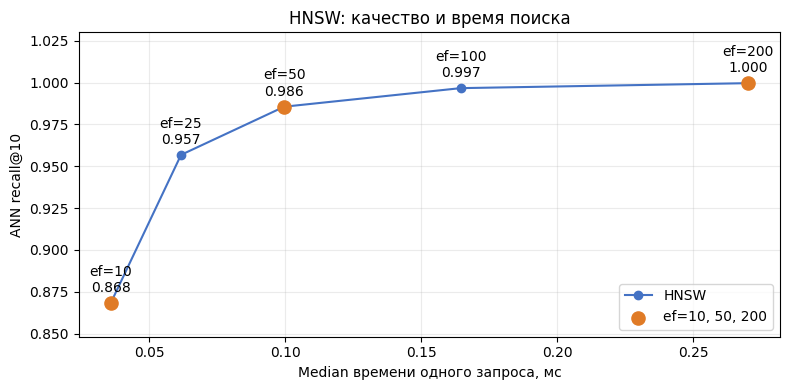

In [174]:
import matplotlib.pyplot as plt

hnsw_recalls = np.array([result[f"recall@{TOP_K}"] for result in hnsw_ef_results])
hnsw_medians = np.array([result["median_ms"] for result in hnsw_ef_results])
hnsw_highlight = np.isin(hnsw_ef_values, [10, 50, 200])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hnsw_medians, hnsw_recalls, "o-", color="#4472c4", label="HNSW")
ax.scatter(
    hnsw_medians[hnsw_highlight], hnsw_recalls[hnsw_highlight],
    color="#e07b26", s=90, zorder=3, label="ef=10, 50, 200",
)
for ef, median_ms, recall in zip(hnsw_ef_values, hnsw_medians, hnsw_recalls):
    ax.annotate(
        f"ef={ef}\n{recall:.3f}", (median_ms, recall),
        xytext=(0, 8), textcoords="offset points", ha="center",
    )
ax.set_title("HNSW: качество и время поиска")
ax.set_xlabel("Median времени одного запроса, мс")
ax.set_ylabel(f"ANN recall@{TOP_K}")
ax.set_ylim(max(0, hnsw_recalls.min() - 0.02), 1.03)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Как устроен HNSW

HNSW (Hierarchical Navigable Small World) хранит граф близких векторов с несколькими уровнями. При поиске алгоритм начинает с верхнего уровня, быстро приближается к области запроса и затем расширяет обход на нижнем уровне. В `hnswlib` основные параметры разделены по этапам:

- `M` — максимальное число связей узла; увеличивает размер графа и обычно повышает recall;
- `ef_construction` — ширина поиска во время построения; влияет на качество графа и время build;
- `ef` — ширина поиска во время конкретного запроса; влияет на recall и latency, но не перестраивает граф.

В отличие от IVF, у HNSW нет coarse-центроидов и `nprobe`: поиск идёт по графу. Сравнение всё равно проводим с тем же точным эталоном и тем же `recall@10`.

In [175]:
# Посмотрим состояние пустого объекта до инициализации. Это полезно,
# потому что init_index задаёт ёмкость и параметры графа только один раз.
hnsw_empty = hnswlib.Index(space="cosine", dim=DIM)
print("space:", hnsw_empty.space)
print("dim:", hnsw_empty.dim)
print("max_elements before init:", hnsw_empty.max_elements)
print("current count before init:", hnsw_empty.element_count)

space: cosine
dim: 384
max_elements before init: 0
current count before init: 0


In [176]:
# Для учебного примера строим отдельный индекс на 1 000 документов.
# Явные labels показывают, что label не обязан совпадать с настоящим номером эмбеддинга
hnsw_demo = hnswlib.Index(space="cosine", dim=DIM)
demo_labels = (100000 + np.arange(1000)).astype("int64")
hnsw_demo.init_index(
    max_elements=1000,
    ef_construction=100,
    M=16,
    random_seed=SEED,
    allow_replace_deleted=False,
)
hnsw_demo.add_items(docs[:1000], demo_labels, num_threads=1)
hnsw_demo.set_ef(50)
print("current count:", hnsw_demo.get_current_count())
print("max elements:", hnsw_demo.get_max_elements())
print("M:", hnsw_demo.M, "ef_construction:", hnsw_demo.ef_construction)
print("ef:", hnsw_demo.ef)
print("first labels (order is internal):", hnsw_demo.get_ids_list()[:5])

current count: 1000
max elements: 1000
M: 16 ef_construction: 100
ef: 50
first labels (order is internal): [100999, 100998, 100997, 100996, 100995]


In [177]:
# get_items восстанавливает исходные векторы по внешним labels.
# Для cosine-пространства hnswlib возвращает именно сохранённые float32-значения.
selected_labels = [demo_labels[0], demo_labels[10]]
selected_vectors = hnsw_demo.get_items(selected_labels)
print("requested labels:", selected_labels)
print("shape:", selected_vectors.shape, "dtype:", selected_vectors.dtype)
print("first reconstruction error:", float(np.linalg.norm(
    selected_vectors[0] - docs[0]
)))

requested labels: [np.int64(100000), np.int64(100010)]
shape: (2, 384) dtype: float32
first reconstruction error: 0.0


In [178]:
# knn_query принимает один вектор или batch-матрицу.
# В cosine space расстояние равно 1 - cosine similarity: у самого себя оно 0.
one_labels, one_distances = hnsw_demo.knn_query(queries[0], k=3)
batch_labels, batch_distances = hnsw_demo.knn_query(queries[:3], k=3)
print("one labels shape:", one_labels.shape, "distances:", np.round(one_distances[0], 3).tolist())
print("batch labels shape:", batch_labels.shape)
print("batch query 0 labels:", batch_labels[0].tolist())

one labels shape: (1, 3) distances: [0.32600000500679016, 0.3720000088214874, 0.39500001072883606]
batch labels shape: (3, 3)
batch query 0 labels: [100766, 100166, 100869]


In [179]:
# Пакетный поиск удобен для предварительной оценки. num_threads относится к
# конкретному вызову и не меняет структуру графа.
batch_labels_20, batch_distances_20 = hnsw_demo.knn_query(
    query_matrix[:20], k=TOP_K, num_threads=1
)
# Demo-индекс содержит только первые 1 000 документов, поэтому строим
# отдельный точный эталон на том же подмножестве. Labels сдвинуты на 100_000.
demo_exact = faiss.IndexFlatIP(DIM)
demo_exact.add(docs[:1000])
demo_truth = demo_exact.search(query_matrix[:20], TOP_K)[1] + 100000
print("batch result shapes:", batch_labels_20.shape, batch_distances_20.shape)
print("batch recall@10 on demo subset:", round(
    recall_at_k(batch_labels_20, demo_truth), 3
))


batch result shapes: (20, 10) (20, 10)
batch recall@10 on demo subset: 0.99


### Сохранение, загрузка и дозаполнение индекса

Сохраним граф на 1000 документах, загрузим его с `max_elements=1500` и добавим ещё 500 документов. Проверим число элементов, сохранность labels и поиск по новым векторам.

Зарезервированная ёмкость не равна числу добавленных документов. После `load_index` задаём `ef` явно; добавленные в памяти документы попадут в файл только после нового сохранения.

<details>
<summary>Чем ёмкость отличается от числа документов и что проверяем после загрузки</summary>

Исходный `hnsw_demo` заполнен: count и capacity равны 1000. Загрузка с `max_elements=1500` резервирует место для добавления, но не создаёт новые документы — сразу после `load_index` count остаётся равным 1000. После добавления строк `docs[1000:1500]` обе величины становятся равны 1500.

Старые labels — `100000..100999`, новые — `101000..101499`. Они не пересекаются, поэтому `add_items` вставляет новые записи. Совпадение выдачи с исходным графом проверяем до вставки. После добавления в поиске участвуют новые документы, поэтому выдача может измениться. `ef` задаём явно после `load_index`; добавление и проверочный поиск выполняем с `num_threads=1`.

Для каждой из 500 новых записей используем её вектор как запрос и проверяем наличие собственного label в top-k. Это проверка доступности добавленных объектов на текущих данных; она не заменяет оценку ANN recall и qrels recall на пользовательских запросах. При одинаковых векторах не требуем, чтобы собственный label обязательно был первым.

Добавление меняет загруженный объект `hnsw_loaded` в памяти. Исходный объект `hnsw_demo` и ранее сохранённый файл остаются снимком первых 1000 документов; для записи дополненного графа на диск понадобился бы отдельный `save_index`.

</details>


In [180]:
hnsw_demo_path = INDEX_DIR / "hnsw_demo.bin"
hnsw_demo.save_index(str(hnsw_demo_path))
print("saved:", hnsw_demo_path)
print("file size MiB:", round(hnsw_demo_path.stat().st_size / 1024**2, 3))
print("index_file_size MiB:", round(hnsw_demo.index_file_size() / 1024**2, 3))

saved: indexes/hnsw_demo.bin
file size MiB: 1.607
index_file_size MiB: 1.607


In [181]:
hnsw_loaded = hnswlib.Index(space="cosine", dim=DIM)
hnsw_loaded.load_index(
    str(hnsw_demo_path),
    max_elements=1500,
    allow_replace_deleted=False,
)
hnsw_loaded.set_ef(50)
loaded_labels, loaded_distances = hnsw_loaded.knn_query(query_matrix[:1], k=TOP_K)
print("loaded count:", hnsw_loaded.get_current_count())
print("loaded capacity:", hnsw_loaded.get_max_elements())
print("same labels after load:", np.array_equal(
    loaded_labels, hnsw_demo.knn_query(query_matrix[:1], k=TOP_K)[0]
))

loaded count: 1000
loaded capacity: 1500
same labels after load: True


In [182]:
# Используем 500 дополнительных мест, выделенных при load_index.
loaded_extra_docs = docs[1000:1500]
loaded_extra_labels = (100000 + np.arange(1000, 1500)).astype("int64")
loaded_before_extra, _ = hnsw_loaded.knn_query(
    loaded_extra_docs[:1], k=TOP_K, num_threads=1
)

hnsw_loaded.add_items(loaded_extra_docs, loaded_extra_labels, num_threads=1)
loaded_extra_neighbors, _ = hnsw_loaded.knn_query(
    loaded_extra_docs, k=TOP_K, num_threads=1
)
loaded_self_matches = np.any(
    loaded_extra_neighbors == loaded_extra_labels[:, None], axis=1
)
loaded_expected_labels = np.concatenate([demo_labels, loaded_extra_labels])

print("count/capacity after add:", hnsw_loaded.get_current_count(), hnsw_loaded.get_max_elements())
print("all old and new labels present:", np.array_equal(
    np.sort(hnsw_loaded.get_ids_list()), loaded_expected_labels
))
print("first new label:", int(loaded_extra_labels[0]))
print("first new-vector query before add:", loaded_before_extra[0].tolist())
print("first new-vector query after add:", loaded_extra_neighbors[0].tolist())
print(f"new labels found in their own top-{TOP_K}: {loaded_self_matches.sum()}/{len(loaded_extra_labels)}")
print("source demo count/capacity:", hnsw_demo.get_current_count(), hnsw_demo.get_max_elements())


count/capacity after add: 1500 1500
all old and new labels present: True
first new label: 101000
first new-vector query before add: [100672, 100363, 100931, 100265, 100935, 100646, 100331, 100424, 100156, 100765]
first new-vector query after add: [101000, 100672, 101147, 100363, 100931, 101098, 101499, 100265, 100935, 100646]
new labels found in their own top-10: 500/500
source demo count/capacity: 1000 1000


### Потоки и изменение ёмкости

`num_threads` управляет параллельным построением и поиском, но не является параметром качества. Если исходной `max_elements` недостаточно, `resize_index` увеличивает резерв графа. Уменьшать ёмкость уже заполненного индекса нельзя без пересборки.

In [183]:
# Явно задаём число потоков для добавления и поиска.
hnsw_demo.set_num_threads(1)
print("num_threads after set:", hnsw_demo.num_threads)
hnsw_demo.set_num_threads(2)
print("num_threads for the next calls:", hnsw_demo.num_threads)
# Возвращаем 1, чтобы benchmark был воспроизводимым на разных машинах.
hnsw_demo.set_num_threads(1)

num_threads after set: 1
num_threads for the next calls: 2


In [184]:
resizable_hnsw = hnswlib.Index(space="cosine", dim=DIM)
resizable_hnsw.init_index(
    max_elements=128,
    ef_construction=50,
    M=8,
    random_seed=SEED,
)
resizable_hnsw.add_items(docs[:100], np.arange(100), num_threads=1)
print("before resize count/capacity:", resizable_hnsw.get_current_count(), resizable_hnsw.get_max_elements())
resizable_hnsw.resize_index(256)
resizable_hnsw.add_items(docs[100:200], np.arange(100, 200), num_threads=1)
print("after resize count/capacity:", resizable_hnsw.get_current_count(), resizable_hnsw.get_max_elements())

before resize count/capacity: 100 128
after resize count/capacity: 200 256


### Удаление и повторное использование удалённых слотов

`mark_deleted` исключает label из выдачи, сохраняя его слот в графе. `unmark_deleted` отменяет пометку. При `allow_replace_deleted=True` вставка с `replace_deleted=True` позволяет занять удалённый слот новым label и вектором.

В отдельных ячейках сравним четыре состояния одного индекса: до удаления, после удаления, после восстановления и после замены. В таблице используем одни и те же два запроса: вектор удаляемого документа `docs[0]` и вектор добавляемого документа `docs[2000]`.

**Удаление не освобождает слот:** `get_current_count()` и `get_ids_list()` включают помеченные удалёнными записи. Активные идентификаторы приложение учитывает отдельно; размер файла не является замером RAM.

<details>
<summary>Как читать count, capacity, labels, поиск и размер файла</summary>

`get_current_count()` показывает число занятых слотов, включая помеченные удалёнными, а `get_max_elements()` — зарезервированную ёмкость. В нашем индексе занято 2000 слотов из 2100. После `mark_deleted(0)` эти числа не меняются, хотя активных документов становится 1999.

`get_ids_list()` в hnswlib 0.8.0 содержит и помеченный удалённым label. Поэтому отдельно показываем длину этого списка и наличие в нём старого label `0` и нового label `9000000`. Это список сохранённых labels, а не список только активных документов.

Строки `active count (app)` и `first active labels (app)` получаем из множества `deletable_active_labels`, которое явно ведём в Python при каждой операции. Это состояние приложения: публичный `get_ids_list()` сам не исключает удалённые labels. Первые labels сортируем только для удобства отображения.

После удаления label `0` остаётся в списке IDs, но исчезает из поиска даже по собственному вектору. `unmark_deleted(0)` снова делает его доступным. Затем повторно удаляем `0` и добавляем другой документ с label `9000000`. Удалённый слот в этот момент только один, поэтому переиспользуется именно он: старый label исчезает из IDs, новый появляется, а `count` остаётся равным 2000. Свободные 100 мест при такой замене не расходуются. Активных документов снова 2000.

Для каждого состояния вызываем `save_index` и измеряем фактический размер отдельного файла в `indexes/`. Пометка удаления не уплотняет индекс и не освобождает его слот. Размер сохранённого файла не следует считать числом активных документов или измерением занятой процессом оперативной памяти.

В примере новый label соответствует другому документу SciFact. Обновление вектора с сохранением прежнего label через повторный `add_items` рассмотрим отдельно ниже.

</details>

In [185]:
import pandas as pd

deletable_hnsw = hnswlib.Index(space="cosine", dim=DIM)
deletable_labels = np.arange(2000, dtype="int64")
deletable_hnsw.init_index(
    max_elements=2100,
    ef_construction=80,
    M=16,
    random_seed=SEED,
    allow_replace_deleted=True,
)
deletable_hnsw.add_items(docs[:2000], deletable_labels, num_threads=1)
deletable_hnsw.set_ef(50)

deleted_label = int(deletable_labels[0])
replacement_label = 9000000
replacement_vector = docs[2000:2001]
deletion_queries = docs[[0, 2000]]
# Активные labels учитывает приложение; get_ids_list включает и удалённые.
deletable_active_labels = set(deletable_labels.tolist())
deletion_states = {}

deletable_ids = set(deletable_hnsw.get_ids_list())
deletion_neighbors, _ = deletable_hnsw.knn_query(deletion_queries, k=3, num_threads=1)
deletion_before_path = INDEX_DIR / "hnsw_before_delete.bin"
deletable_hnsw.save_index(str(deletion_before_path))
deletion_states["before"] = {
    "count": deletable_hnsw.get_current_count(),
    "capacity": deletable_hnsw.get_max_elements(),
    "stored IDs": len(deletable_ids),
    "0 in IDs": deleted_label in deletable_ids,
    "9000000 in IDs": replacement_label in deletable_ids,
    "active count (app)": len(deletable_active_labels),
    "first active labels (app)": sorted(deletable_active_labels)[:3],
    "search docs[0]": deletion_neighbors[0].tolist(),
    "search docs[2000]": deletion_neighbors[1].tolist(),
    "file bytes": deletion_before_path.stat().st_size,
}
pd.DataFrame(deletion_states)

,before
count,2000
capacity,2100
stored IDs,2000
0 in IDs,True
9000000 in IDs,False
active count (app),2000
first active labels (app),"[0, 1, 2]"
search docs[0],"[0, 579, 1316]"
search docs[2000],"[1120, 1124, 1058]"
file bytes,3370024


In [186]:
deletable_hnsw.mark_deleted(deleted_label)
deletable_active_labels.remove(deleted_label)

deletable_ids = set(deletable_hnsw.get_ids_list())
deletion_neighbors, _ = deletable_hnsw.knn_query(deletion_queries, k=3, num_threads=1)
deletion_marked_path = INDEX_DIR / "hnsw_after_delete.bin"
deletable_hnsw.save_index(str(deletion_marked_path))
deletion_states["deleted"] = {
    "count": deletable_hnsw.get_current_count(),
    "capacity": deletable_hnsw.get_max_elements(),
    "stored IDs": len(deletable_ids),
    "0 in IDs": deleted_label in deletable_ids,
    "9000000 in IDs": replacement_label in deletable_ids,
    "active count (app)": len(deletable_active_labels),
    "first active labels (app)": sorted(deletable_active_labels)[:3],
    "search docs[0]": deletion_neighbors[0].tolist(),
    "search docs[2000]": deletion_neighbors[1].tolist(),
    "file bytes": deletion_marked_path.stat().st_size,
}
pd.DataFrame(deletion_states)

,before,deleted
count,2000,2000
capacity,2100,2100
stored IDs,2000,2000
0 in IDs,True,True
9000000 in IDs,False,False
active count (app),2000,1999
first active labels (app),"[0, 1, 2]","[1, 2, 3]"
search docs[0],"[0, 579, 1316]","[579, 1316, 268]"
search docs[2000],"[1120, 1124, 1058]","[1120, 1124, 1058]"
file bytes,3370024,3370024


In [187]:
# Отменяем пометку, если удаление было ошибочным.
deletable_hnsw.unmark_deleted(deleted_label)
deletable_active_labels.add(deleted_label)

deletable_ids = set(deletable_hnsw.get_ids_list())
deletion_neighbors, _ = deletable_hnsw.knn_query(deletion_queries, k=3, num_threads=1)
deletion_restored_path = INDEX_DIR / "hnsw_after_unmark.bin"
deletable_hnsw.save_index(str(deletion_restored_path))
deletion_states["restored"] = {
    "count": deletable_hnsw.get_current_count(),
    "capacity": deletable_hnsw.get_max_elements(),
    "stored IDs": len(deletable_ids),
    "0 in IDs": deleted_label in deletable_ids,
    "9000000 in IDs": replacement_label in deletable_ids,
    "active count (app)": len(deletable_active_labels),
    "first active labels (app)": sorted(deletable_active_labels)[:3],
    "search docs[0]": deletion_neighbors[0].tolist(),
    "search docs[2000]": deletion_neighbors[1].tolist(),
    "file bytes": deletion_restored_path.stat().st_size,
}
pd.DataFrame(deletion_states)

,before,deleted,restored
count,2000,2000,2000
capacity,2100,2100,2100
stored IDs,2000,2000,2000
0 in IDs,True,True,True
9000000 in IDs,False,False,False
active count (app),2000,1999,2000
first active labels (app),"[0, 1, 2]","[1, 2, 3]","[0, 1, 2]"
search docs[0],"[0, 579, 1316]","[579, 1316, 268]","[0, 579, 1316]"
search docs[2000],"[1120, 1124, 1058]","[1120, 1124, 1058]","[1120, 1124, 1058]"
file bytes,3370024,3370024,3370024


In [188]:
# Единственный удалённый слот займёт другой документ с новым label.
deletable_hnsw.mark_deleted(deleted_label)
deletable_active_labels.remove(deleted_label)
deletable_hnsw.add_items(
    replacement_vector,
    np.asarray([replacement_label], dtype="int64"),
    num_threads=1,
    replace_deleted=True,
)
deletable_active_labels.add(replacement_label)

deletable_ids = set(deletable_hnsw.get_ids_list())
deletion_neighbors, _ = deletable_hnsw.knn_query(deletion_queries, k=3, num_threads=1)
deletion_replaced_path = INDEX_DIR / "hnsw_after_replace.bin"
deletable_hnsw.save_index(str(deletion_replaced_path))
deletion_states["replaced"] = {
    "count": deletable_hnsw.get_current_count(),
    "capacity": deletable_hnsw.get_max_elements(),
    "stored IDs": len(deletable_ids),
    "0 in IDs": deleted_label in deletable_ids,
    "9000000 in IDs": replacement_label in deletable_ids,
    "active count (app)": len(deletable_active_labels),
    "first active labels (app)": sorted(deletable_active_labels)[:3],
    "search docs[0]": deletion_neighbors[0].tolist(),
    "search docs[2000]": deletion_neighbors[1].tolist(),
    "file bytes": deletion_replaced_path.stat().st_size,
}
pd.DataFrame(deletion_states)

,before,deleted,restored,replaced
count,2000,2000,2000,2000
capacity,2100,2100,2100,2100
stored IDs,2000,2000,2000,2000
0 in IDs,True,True,True,False
9000000 in IDs,False,False,False,True
active count (app),2000,1999,2000,2000
first active labels (app),"[0, 1, 2]","[1, 2, 3]","[0, 1, 2]","[1, 2, 3]"
search docs[0],"[0, 579, 1316]","[579, 1316, 268]","[0, 579, 1316]","[579, 1316, 268]"
search docs[2000],"[1120, 1124, 1058]","[1120, 1124, 1058]","[1120, 1124, 1058]","[9000000, 1120, 1124]"
file bytes,3370024,3370024,3370024,3370024


### Параметры построения: `ef_construction`

`ef_construction` используется только при добавлении элементов. После того как граф построен, изменение `ef` не может улучшить связи, которые не были созданы на этапе build. Поэтому сравниваем два новых индекса при одинаковом `M=40` и одинаковом `ef=150`.

In [189]:
hnsw_build_low = hnswlib.Index(space="cosine", dim=DIM)
hnsw_build_low.init_index(
    max_elements=len(docs),
    ef_construction=20,
    M=40,
    random_seed=SEED,
)
hnsw_build_low.add_items(docs, np.arange(len(docs)), num_threads=1)
hnsw_build_low.set_ef(150)
hnsw_build_low_path = INDEX_DIR / "hnsw_build_low.bin"
hnsw_build_low.save_index(str(hnsw_build_low_path))

def hnsw_build_low_search(query, k):
    labels, _ = hnsw_build_low.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_low_result, _ = benchmark(
    "hnswlib ef_construction=20",
    hnsw_build_low_search,
    index_size_mb=file_size(hnsw_build_low_path),
)

print_results([exact_result, hnsw_low_result], k=TOP_K)

index                       ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------------------
exact / FlatIP                      1.000            0.860         0.100         0.111          7.59
hnswlib ef_construction=20          0.998            0.860         0.208         0.263          9.27


In [190]:
hnsw_build_high = hnswlib.Index(space="cosine", dim=DIM)
hnsw_build_high.init_index(
    max_elements=len(docs),
    ef_construction=400,
    M=40,
    random_seed=SEED,
)
hnsw_build_high.add_items(docs, np.arange(len(docs)), num_threads=1)
hnsw_build_high.set_ef(150)
hnsw_build_high_path = INDEX_DIR / "hnsw_build_high.bin"
hnsw_build_high.save_index(str(hnsw_build_high_path))

def hnsw_build_high_search(query, k):
    labels, _ = hnsw_build_high.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_high_result, _ = benchmark(
    "hnswlib ef_construction=400",
    hnsw_build_high_search,
    index_size_mb=file_size(hnsw_build_high_path),
)

print_results([exact_result, hnsw_high_result], k=TOP_K)

index                        ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------------------
exact / FlatIP                       1.000            0.860         0.100         0.111          7.59
hnswlib ef_construction=400          1.000            0.860         0.297         0.378          9.27


При большем `ef_construction` построение дольше, но граф обычно лучше соединяет удалённые области. Это параметр качества самого индекса, в отличие от `ef`, который можно менять после build. В production build часто выполняют offline, поэтому можно позволить себе большой `ef_construction`, если это улучшает recall при поиске.

### Параметр `M` и размер графа

`M` задаёт число соседних связей. Увеличение `M` обычно увеличивает файл и время построения, но даёт алгоритму больше альтернативных маршрутов. Сравним два индекса при одинаковом `ef_construction` и `ef`.

Здесь размер сравнивается по файлам индексов. Это показатель объёма сохранённой структуры, а не измерение оперативной памяти процесса.

In [191]:
hnsw_m8 = hnswlib.Index(space="cosine", dim=DIM)
hnsw_m8.init_index(
    max_elements=len(docs), ef_construction=100, M=8, random_seed=SEED
)
hnsw_m8.add_items(docs, np.arange(len(docs)), num_threads=1)
hnsw_m8.set_ef(100)
hnsw_m8_path = INDEX_DIR / "hnsw_m8.bin"
hnsw_m8.save_index(str(hnsw_m8_path))

def hnsw_m8_search(query, k):
    labels, _ = hnsw_m8.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_m8_result, _ = benchmark(
    "hnswlib M=8",
    hnsw_m8_search,
    index_size_mb=file_size(hnsw_m8_path),
)

print_results([exact_result, hnsw_m8_result], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
hnswlib M=8             0.988            0.860         0.121         0.147          8.01


In [192]:
hnsw_m32 = hnswlib.Index(space="cosine", dim=DIM)
hnsw_m32.init_index(
    max_elements=len(docs), ef_construction=100, M=32, random_seed=SEED
)
hnsw_m32.add_items(docs, np.arange(len(docs)), num_threads=1)
hnsw_m32.set_ef(100)
hnsw_m32_path = INDEX_DIR / "hnsw_m32.bin"
hnsw_m32.save_index(str(hnsw_m32_path))

def hnsw_m32_search(query, k):
    labels, _ = hnsw_m32.knn_query(query.reshape(1, -1), k=k, num_threads=1)
    return labels[0]

hnsw_m32_result, _ = benchmark(
    "hnswlib M=32",
    hnsw_m32_search,
    index_size_mb=file_size(hnsw_m32_path),
)

print_results([exact_result, hnsw_m32_result], k=TOP_K)

index           ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
----------------------------------------------------------------------------------------
exact / FlatIP          1.000            0.860         0.100         0.111          7.59
hnswlib M=32            0.998            0.860         0.185         0.233          8.96


### Метрики и смысл расстояния

`hnswlib` поддерживает `l2`, `cosine` и `ip`. Для нормализованных векторов cosine и L2 задают одинаковый порядок ближайших соседей, хотя числовые значения расстояния отличаются.

In [193]:
# Для сравнения пространств используем одинаковый ef=100.
hnsw.set_ef(100)
hnsw_l2 = hnswlib.Index(space="l2", dim=DIM)
hnsw_l2.init_index(max_elements=len(docs), ef_construction=100, M=16, random_seed=SEED)
hnsw_l2.add_items(docs, np.arange(len(docs)), num_threads=1)
hnsw_l2.set_ef(100)
l2_labels, l2_distances = hnsw_l2.knn_query(query_matrix[:1], k=TOP_K)
print("L2 ids:", l2_labels[0].tolist())
print("L2 distances:", np.round(l2_distances[0], 3).tolist())
print("same top-k as cosine index:", np.array_equal(l2_labels, hnsw.knn_query(query_matrix[:1], k=TOP_K)[0]))

L2 ids: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]
L2 distances: [0.6510000228881836, 0.6679999828338623, 0.7009999752044678, 0.7300000190734863, 0.7319999933242798, 0.7329999804496765, 0.7350000143051147, 0.7429999709129333, 0.7440000176429749, 0.753000020980835]
same top-k as cosine index: True


In [194]:
hnsw_ip = hnswlib.Index(space="ip", dim=DIM)
hnsw_ip.init_index(max_elements=len(docs), ef_construction=100, M=16, random_seed=SEED)
hnsw_ip.add_items(docs, np.arange(len(docs)), num_threads=1)
hnsw_ip.set_ef(100)
ip_labels, ip_distances = hnsw_ip.knn_query(query_matrix[:1], k=TOP_K)
print("IP ids:", ip_labels[0].tolist())
print("IP distances returned by hnswlib:", np.round(ip_distances[0], 3).tolist())
print("same top-k as cosine index:", np.array_equal(ip_labels, hnsw.knn_query(query_matrix[:1], k=TOP_K)[0]))

IP ids: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]
IP distances returned by hnswlib: [0.32600000500679016, 0.33399999141693115, 0.35100001096725464, 0.36500000953674316, 0.3659999966621399, 0.3659999966621399, 0.36800000071525574, 0.3720000088214874, 0.3720000088214874, 0.37700000405311584]
same top-k as cosine index: True


Итог для HNSW: `M` и `ef_construction` выбирают качество и размер построенного графа; `ef` выбирает рабочую точку конкретного запроса; `max_elements`, labels, delete/replace и serialization определяют эксплуатационный жизненный цикл. Внешний `hnswlib` удобен как самостоятельный быстрый индекс, а `IndexHNSWFlat` выше показывает тот же алгоритм внутри единого API FAISS.

## 21. Расширение HNSW: дополнительные возможности hnswlib

В базовой части мы уже измерили `ef`, `M` и `ef_construction`. Теперь разберём возможности Python bindings, которые важны для RAG-сервиса: фильтрацию по label, точный эталон `BFIndex`, обновление существующих labels, pickle, контракты ошибок, incremental workflow и потоковые ограничения. Каждый параметрический запуск остаётся отдельной ячейкой.

### Встроенный фильтр в `knn_query`

В hnswlib фильтр можно передать прямо в `knn_query` как Python-функцию `label -> bool`. В отличие от постфильтра, граф не возвращает запрещённые labels. Но функция фильтра выполняется через Python и удерживает GIL, поэтому документация рекомендует `num_threads=1`.

In [195]:
# Моделируем tenant-фильтр на тех же labels 0..N-1, которые использует hnsw.
extension_tenant = doc_bucket
extension_query_tenant = int(query_bucket[0])
extension_filter = lambda label: int(extension_tenant[int(label)]) == extension_query_tenant
hnsw.set_ef(100)
filtered_labels, filtered_distances = hnsw.knn_query(
    query_matrix[:1], k=TOP_K, num_threads=1, filter=extension_filter
)
valid_filtered = filtered_labels[0][filtered_labels[0] >= 0]
print("requested tenant:", extension_query_tenant)
print("native filtered ids:", valid_filtered.tolist())
print("all labels pass filter:", bool(
    np.all(extension_tenant[valid_filtered] == extension_query_tenant)
))

requested tenant: 0
native filtered ids: [4132, 4368, 2324, 4908, 4564, 2488, 1044, 760, 1728, 2660]
all labels pass filter: True


In [196]:
# Сравниваем встроенную фильтрацию с постфильтрацией после exact-поиска.
# Oversampling нужен, потому что первые k глобальных соседей могут принадлежать
# другим tenant-ам.
filtered_truth_extension = exact.search(query_matrix[:1], len(docs))[1][0]
filtered_truth_extension = filtered_truth_extension[
    extension_tenant[filtered_truth_extension] == extension_query_tenant
][:TOP_K]
post_candidates_extension = exact.search(query_matrix[:1], 100)[1][0]
post_filtered_extension = post_candidates_extension[
    extension_tenant[post_candidates_extension] == extension_query_tenant
][:TOP_K]
print("filtered exact truth:", filtered_truth_extension.tolist())
print("post-filter with fetch_k=100:", post_filtered_extension.tolist())
print("post-filter recall@10:", round(
    len(set(post_filtered_extension.tolist()) & set(filtered_truth_extension.tolist())) / TOP_K, 3
))

filtered exact truth: [4132, 4368, 2324, 4908, 4564, 2488, 1044, 760, 1728, 2660]
post-filter with fetch_k=100: [4132, 4368, 2324, 4908, 4564, 2488, 1044, 760, 1728, 2660]
post-filter recall@10: 1.0


In [197]:
# Если функция фильтра запрещает всё, hnswlib не может вернуть k результатов.
try:
    hnsw.knn_query(
        query_matrix[:1], k=1, num_threads=1, filter=lambda label: False
    )
except RuntimeError as error:
    print("strict filter error:", error)

strict filter error: Cannot return the results in a contiguous 2D array. Probably ef or M is too small


### `BFIndex` как точный эталон

В hnswlib есть отдельный `BFIndex`: он использует полный перебор в том же distance API. Это удобный независимый эталон для проверки HNSW без FAISS. Он поддерживает пакетный поиск, filters, удаление и сериализацию, но не имеет графа и поэтому не даёт ANN-ускорения.

In [198]:
bf_extension = hnswlib.BFIndex(space="cosine", dim=DIM)
bf_extension.init_index(max_elements=len(docs))
bf_extension.add_items(docs, np.arange(len(docs)),)
bf_extension_path = INDEX_DIR / "bf_extension.bin"
bf_extension.save_index(str(bf_extension_path))
bf_extension_labels, bf_extension_distances = bf_extension.knn_query(
    query_matrix[:1], k=TOP_K, num_threads=1
)
print("BF count/capacity:", bf_extension.get_current_count(), bf_extension.get_max_elements())
print("BF ids:", bf_extension_labels[0].tolist())
print("BF equals FAISS exact:", np.array_equal(bf_extension_labels, exact_ids[:1]))

BF count/capacity: 5183 5183
BF ids: [766, 2723, 4132, 4368, 2324, 2554, 1373, 3190, 166, 4908]
BF equals FAISS exact: True


In [199]:
def bf_extension_search(query, k):
    return bf_extension.knn_query(query.reshape(1, -1), k=k, num_threads=1)[0][0]

bf_extension_result, _ = benchmark(
    "hnswlib BFIndex",
    bf_extension_search,
    index_size_mb=file_size(bf_extension_path),
)

print_results([exact_result, bf_extension_result], k=TOP_K)

index            ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-----------------------------------------------------------------------------------------
exact / FlatIP           1.000            0.860         0.100         0.111          7.59
hnswlib BFIndex          1.000            0.860         0.608         0.659          7.63


In [200]:
# BFIndex также принимает ту же функцию фильтра.
bf_filtered_labels, _ = bf_extension.knn_query(
    query_matrix[:1], k=TOP_K, num_threads=1, filter=extension_filter
)
print("BF filtered ids:", bf_filtered_labels[0].tolist())
bf_delete_demo = hnswlib.BFIndex(space="cosine", dim=DIM)
bf_delete_demo.init_index(max_elements=100)
bf_delete_demo.add_items(docs[:100], np.arange(100))
bf_delete_demo.delete_vector(0)
print("BF count after delete:", bf_delete_demo.get_current_count())
print("deleted id absent:", 0 not in bf_delete_demo.knn_query(docs[:1], k=10)[0][0])

BF filtered ids: [4132, 4368, 2324, 4908, 4564, 2488, 1044, 760, 1728, 2660]
BF count after delete: 99
deleted id absent: True


### Обновление существующего идентификатора (`label`)

Повторный `add_items` с существующим идентификатором заменяет его вектор, сохраняя идентификатор и число элементов. Проверим поиск до и после замены: **для оценки ANN recall после обновления нужен точный эталон на обновлённых векторах**. Сохранность внутренних связей графа этот API не обещает.

<details>
<summary>Что проверяем через API и что нельзя заключить о графе</summary>

Создадим отдельный индекс на первых 1000 документах SciFact с идентификаторами `0..999`. В запись `7` поместим эмбеддинг документа `1000`, которого ещё нет в этом индексе. Вектор нового документа будет одним и тем же запросом до и после обновления. Не масштабируем его и не добавляем новый идентификатор.

В пространстве `l2` hnswlib возвращает **квадрат евклидова расстояния**. После замены запись `7` содержит сам вектор запроса, поэтому её точное расстояние равно нулю. Покажем соседей и расстояния до/после, проверим сохранённый вектор через `get_items`, количество элементов, ёмкость и полный набор идентификаторов.

Дополнительно выполняем поиск по всем запросам SciFact при неизменном `ef=100`. До обновления сравниваем с `IndexFlatL2` на исходной подколлекции, после — с новым `IndexFlatL2`, в котором заменена та же строка. Разница между старой и новой выдачей сама по себе не является ошибкой поиска: изменилась коллекция. ANN recall в каждом состоянии проверяет воспроизведение точного поиска именно в этом состоянии.

Мы меняем только вектор записи в отдельном техническом опыте. Текст статьи и qrels не редактируются: перенос эмбеддинга не делает документ `7` релевантным всем запросам к документу `1000`. Поэтому здесь измеряем ANN recall; результаты не добавляем в общее сравнение исходной коллекции.

[Документация hnswlib 0.8.0](https://github.com/nmslib/hnswlib/blob/v0.8.0/README.md#api-description) описывает замену вектора при повторной передаче существующего идентификатора. Обновление может пересматривать связи графа; их неизменность не входит в этот контракт. Python API не предоставляет списка рёбер для такого сравнения. Изменение соседей в выдаче показывает результат поиска, но не доказывает, какие рёбра изменились внутри. `add_items` и `knn_query` для этого индекса выполняем последовательно.

</details>

In [201]:
# Отдельный граф: обновление не затрагивает индексы основного сравнения.
hnsw_update_docs_before = docs[:1000].copy()
hnsw_update_ids = np.arange(len(hnsw_update_docs_before), dtype="int64")
hnsw_update_target = 7
hnsw_update_source_id = 1000
new_vector_for_label = docs[hnsw_update_source_id:hnsw_update_source_id + 1].copy()
hnsw_update_query = new_vector_for_label

update_extension = hnswlib.Index(space="l2", dim=DIM)
update_extension.init_index(
    max_elements=len(hnsw_update_docs_before), M=16, ef_construction=100, random_seed=SEED
)
update_extension.add_items(hnsw_update_docs_before, hnsw_update_ids, num_threads=1)
update_extension.set_ef(100)
hnsw_update_count_before = update_extension.get_current_count()
hnsw_update_capacity_before = update_extension.get_max_elements()
hnsw_update_ids_before = set(update_extension.get_ids_list())
hnsw_update_old_vector = update_extension.get_items([hnsw_update_target])[0]
hnsw_update_query_before_ids, hnsw_update_query_before_distances = update_extension.knn_query(
    hnsw_update_query, k=TOP_K, num_threads=1
)
print("source document:", describe_doc(hnsw_update_source_id))
print("updated label:", hnsw_update_target)
print("before update IDs:", hnsw_update_query_before_ids[0].tolist())
print("before update squared L2 distances:", hnsw_update_query_before_distances[0].round(4))
print("target appears before update:", hnsw_update_target in hnsw_update_query_before_ids[0])
print("old target squared L2 distance:", float(np.sum((hnsw_update_old_vector - hnsw_update_query[0]) ** 2)))

source document: row=1000, corpus_id=5293024, title='Life is sweet: candy consumption and longevity.', text="Our attitude towards candy—“if it tastes that good, it can't be healthy”—betrays society's puritanical stance towards pl…"
updated label: 7
before update IDs: [672, 363, 931, 265, 935, 646, 331, 424, 156, 765]
before update squared L2 distances: [0.391 0.449 0.502 0.538 0.554 0.557 0.57  0.572 0.574 0.582]
target appears before update: False
old target squared L2 distance: 0.8608783483505249


In [202]:
# Эталон до обновления построен на той же подколлекции и с той же метрикой.
hnsw_update_exact_before = faiss.IndexFlatL2(DIM)
hnsw_update_exact_before.add(hnsw_update_docs_before)
hnsw_update_before_truth = hnsw_update_exact_before.search(query_matrix, TOP_K)[1]
hnsw_update_before_labels, _ = update_extension.knn_query(query_matrix, k=TOP_K, num_threads=1)
hnsw_update_before_recall = recall_at_k(hnsw_update_before_labels, hnsw_update_before_truth, k=TOP_K)
print("documents / evaluation queries / ef:", len(hnsw_update_docs_before), len(query_matrix), update_extension.ef)
print(f"ANN recall@{TOP_K} before update:", round(hnsw_update_before_recall, 4))

documents / evaluation queries / ef: 1000 1109 100
ANN recall@10 before update: 0.9995


In [203]:
# Тот же идентификатор: заменяется существующая запись.
update_extension.add_items(
    new_vector_for_label, np.array([hnsw_update_target], dtype="int64"), num_threads=1
)
updated_vector = update_extension.get_items([hnsw_update_target])[0]
hnsw_update_query_after_ids, hnsw_update_query_after_distances = update_extension.knn_query(
    hnsw_update_query, k=TOP_K, num_threads=1
)
print("count before / after:", hnsw_update_count_before, update_extension.get_current_count())
print("capacity before / after:", hnsw_update_capacity_before, update_extension.get_max_elements())
print("same labels:", set(update_extension.get_ids_list()) == hnsw_update_ids_before)
print("updated vector error:", float(np.linalg.norm(updated_vector - new_vector_for_label[0])))
print("after update IDs:", hnsw_update_query_after_ids[0].tolist())
print("after update squared L2 distances:", hnsw_update_query_after_distances[0].round(4))
print("target appears after update:", hnsw_update_target in hnsw_update_query_after_ids[0])
print("new target squared L2 distance:", float(np.sum((updated_vector - hnsw_update_query[0]) ** 2)))

count before / after: 1000 1000
capacity before / after: 1000 1000
same labels: True
updated vector error: 0.0
after update IDs: [7, 672, 363, 931, 265, 935, 646, 331, 424, 156]
after update squared L2 distances: [0.    0.391 0.449 0.502 0.538 0.554 0.557 0.57  0.572 0.574]
target appears after update: True
new target squared L2 distance: 0.0


In [204]:
# После замены нужен новый точный эталон: в нём меняется та же строка.
hnsw_update_docs_after = hnsw_update_docs_before.copy()
hnsw_update_docs_after[hnsw_update_target] = new_vector_for_label[0]
hnsw_update_exact_after = faiss.IndexFlatL2(DIM)
hnsw_update_exact_after.add(hnsw_update_docs_after)
hnsw_update_after_truth = hnsw_update_exact_after.search(query_matrix, TOP_K)[1]
hnsw_update_after_labels, _ = update_extension.knn_query(query_matrix, k=TOP_K, num_threads=1)
hnsw_update_after_recall = recall_at_k(hnsw_update_after_labels, hnsw_update_after_truth, k=TOP_K)
print(f"ANN recall@{TOP_K} before / after update:",
      round(hnsw_update_before_recall, 4), round(hnsw_update_after_recall, 4))
print("queries with changed exact top-k:", int(np.any(
    hnsw_update_before_truth != hnsw_update_after_truth, axis=1
).sum()))
print("queries with changed HNSW top-k:", int(np.any(
    hnsw_update_before_labels != hnsw_update_after_labels, axis=1
).sum()))

ANN recall@10 before / after update: 0.9995 0.9995
queries with changed exact top-k: 11
queries with changed HNSW top-k: 11


### Pickle и бинарная сериализация

**Не загружайте pickle из недоверенного источника: `pickle.load` и `pickle.loads` могут выполнить произвольный код.** Ниже загружаются байты, которые мы только что создали из собственного индекса в этой же ячейке.

Для хранения и передачи самого индекса предпочитаем **`save_index` / `load_index`** с проверкой совместимости в целевом окружении. Pickle используем для снимка Python-объекта в контролируемом окружении с известными версиями зависимостей.

Не сериализуем индекс через pickle одновременно с `add_items` для того же объекта: снимок должен соответствовать согласованному состоянию.

<details>
<summary>Безопасность, совместимость версий и состояние индекса</summary>

Pickle восстанавливает Python-объект, а не просто читает массив чисел. При восстановлении могут вызываться функции, заданные содержимым pickle. Нельзя считать файл безопасным по расширению `.pkl` или потому, что в нём предположительно находится индекс. Загрузка уже является выполнением инструкций из файла; проверять полученный объект после `loads` слишком поздно. Подробнее — в [документации Python](https://docs.python.org/3/library/pickle.html).

Сам протокол pickle поддерживает совместимость между многими версиями Python, однако более новый протокол может требовать более нового интерпретатора. Для объекта hnswlib дополнительно важны версия библиотеки, её формат сериализованного состояния и сборка. Поэтому фиксируем версии Python и hnswlib и проверяем восстановление и выдачу в целевом окружении. Успешная загрузка в текущем ядре не доказывает совместимость с произвольной другой версией.

`save_index` сохраняет бинарный индекс для загрузчика hnswlib, без сериализации произвольного Python-объекта через pickle. Это основной путь для файла индекса, но он тоже не обещает совместимости любых версий, сборок и платформ. Используем доверенные артефакты, сохраняем сведения о версии hnswlib, `space` и `dim`; перенос проверяем через загрузку и контрольные запросы. После `load_index` явно задаём `ef`, как в предыдущем примере. В показанном pickle-примере `ef` восстанавливается вместе с состоянием объекта.

Документация hnswlib запрещает сериализовать индекс через pickle одновременно с `add_items` **для того же индекса**. Пока сериализация читает его состояние, другой поток не должен изменять граф. В ячейке ниже эти операции выполняются последовательно.

</details>

In [205]:
import pickle

hnsw_demo.set_ef(77)
pickle_payload = pickle.dumps(hnsw_demo)
# Доверенные байты: payload создан выше из нашего индекса в этой же ячейке.
hnsw_pickled = pickle.loads(pickle_payload)
pickled_labels, _ = hnsw_pickled.knn_query(query_matrix[:1], k=TOP_K)
print("pickle bytes:", len(pickle_payload))
print("restored ef:", hnsw_pickled.ef)
print("restored count:", hnsw_pickled.get_current_count())
print("same ids after pickle:", np.array_equal(
    pickled_labels, hnsw_demo.knn_query(query_matrix[:1], k=TOP_K)[0]
))

pickle bytes: 1698298
restored ef: 77
restored count: 1000
same ids after pickle: True


In [206]:
pickle_binary_path = INDEX_DIR / "hnsw_demo.pkl"
pickle_binary_path.write_bytes(pickle_payload)
print("pickle file MiB:", round(pickle_binary_path.stat().st_size / 1024**2, 3))
print("save_index file MiB:", round(hnsw_demo_path.stat().st_size / 1024**2, 3))

pickle file MiB: 1.62
save_index file MiB: 1.607


### `get_items`, форматы вывода и cosine-нормализация

Для `space="cosine"` hnswlib нормализует вектор во внутреннем представлении. Поэтому `get_items` возвращает нормализованный вектор, а не обязательно байтово исходный embedding. `return_type="list"` удобен для обычной сериализации, `return_type="numpy"` — для дальнейшей математики.

In [207]:
raw_extension = np.random.normal(size=(20, DIM)).astype("float32")
raw_cosine = hnswlib.Index(space="cosine", dim=DIM)
raw_cosine.init_index(max_elements=20)
raw_cosine.add_items(raw_extension, np.arange(20), num_threads=1)
raw_numpy = raw_cosine.get_items([0, 1], return_type="numpy")
raw_list = raw_cosine.get_items([0, 1], return_type="list")
print("numpy shape/dtype:", raw_numpy.shape, raw_numpy.dtype)
print("list type/shape:", type(raw_list).__name__, (len(raw_list), len(raw_list[0])))
print("original norm:", round(float(np.linalg.norm(raw_extension[0])), 3))
print("get_items cosine norm:", round(float(np.linalg.norm(raw_numpy[0])), 3))
print("get_items without ids:", raw_cosine.get_items().shape)
print("ids list:", raw_cosine.get_ids_list()[:5])

numpy shape/dtype: (2, 384) float32
list type/shape: list (2, 384)
original norm: 19.397
get_items cosine norm: 1.0
get_items without ids: (0,)
ids list: [19, 18, 17, 16, 15]


### Рекомендации по настройке и ошибки API

Для поиска рекомендуем задавать `ef >= k`, а рабочее значение `ef` подбирать по recall и задержке. Это рекомендация по настройке, а не обязательная проверка входных параметров со стороны Python API.

<details>
<summary>Как понимать успешный вызов с ef меньше k</summary>

`k` задаёт число возвращаемых соседей, а `ef` управляет шириной поиска по графу. В используемой версии hnswlib 0.8.0 вызов с `ef=1` и `k=3` выполняется успешно. Пример показывает поведение API на трёх векторах; он не оценивает качество поиска на реальной коллекции. Ожидать исключения только из-за `ef < k` не следует.

Само условие `ef >= k` тоже не гарантирует нужного recall. Рабочую настройку выбирают по измерениям качества и задержки на своих данных — как в предыдущей серии опытов с `ef`.

</details>

Остальные вызовы ниже намеренно демонстрируют ошибки. Текст исключения зависит от версии bindings, поэтому в приложении проверяем тип ошибки и состояние индекса, а не парсим строку сообщения.


In [208]:
validation_index = hnswlib.Index(space="l2", dim=4)
validation_index.init_index(max_elements=3)
validation_vectors = np.eye(3, 4, dtype="float32")
validation_index.add_items(validation_vectors, np.arange(3))
# В этой версии ef < k допускается; показываем поведение API.
validation_index.set_ef(1)
validation_index.knn_query(validation_vectors[:1], k=3)
print("ef=1, k=3 accepted; ef >= k is a tuning recommendation")
try:
    validation_index.knn_query(validation_vectors[:1], k=4)
except RuntimeError as error:
    print("k > count:", error)

ef=1, k=3 accepted; ef >= k is a tuning recommendation
k > count: Cannot return the results in a contiguous 2D array. Probably ef or M is too small


In [209]:
try:
    validation_index.add_items(np.ones((1, 3), dtype="float32"))
except RuntimeError as error:
    print("wrong dimensionality:", error)
try:
    validation_index.resize_index(2)
except RuntimeError as error:
    print("shrink below count:", error)
try:
    validation_index.mark_deleted(999)
except RuntimeError as error:
    print("unknown label:", error)

wrong dimensionality: Wrong dimensionality of the vectors
shrink below count: Cannot resize, max element is less than the current number of elements
unknown label: Label not found


In [210]:
negative_label_index = hnswlib.Index(space="l2", dim=4)
negative_label_index.init_index(max_elements=2)
negative_label_index.add_items(
    np.ones((1, 4), dtype="float32"), np.asarray([-1], dtype="int64")
)
print("negative label is coerced to:", negative_label_index.get_ids_list())
print("external IDs should therefore be validated before add_items")

negative label is coerced to: [18446744073709551615]
external IDs should therefore be validated before add_items


### Incremental workflow после сериализации

Документация hnswlib показывает сценарий «первая половина → save → load с увеличенной capacity → вторая половина». Это отличается от простого `resize_index`: между этапами индекс можно передать другому процессу или машине.

In [211]:
incremental_docs = docs[:2000]
incremental_first = incremental_docs[:1000]
incremental_second = incremental_docs[1000:]
incremental_index = hnswlib.Index(space="cosine", dim=DIM)
incremental_index.init_index(max_elements=1000, ef_construction=100, M=16)
incremental_index.add_items(incremental_first, np.arange(1000), num_threads=1)
incremental_index.set_ef(50)
incremental_path = INDEX_DIR / "incremental.bin"
incremental_index.save_index(str(incremental_path))
print("first batch count/capacity:", incremental_index.get_current_count(), incremental_index.get_max_elements())

first batch count/capacity: 1000 1000


In [212]:
incremental_loaded = hnswlib.Index(space="cosine", dim=DIM)
incremental_loaded.load_index(str(incremental_path), max_elements=2000)
incremental_loaded.add_items(
    incremental_second, np.arange(1000, 2000), num_threads=1
)
incremental_loaded.set_ef(50)
incremental_truth_index = faiss.IndexFlatIP(DIM)
incremental_truth_index.add(incremental_docs)
incremental_truth = incremental_truth_index.search(query_matrix, TOP_K)[1]
incremental_labels, _ = incremental_loaded.knn_query(query_matrix, k=TOP_K, num_threads=1)
print("second batch count/capacity:", incremental_loaded.get_current_count(), incremental_loaded.get_max_elements())
print("recall on 2,000-document collection:", round(
    recall_at_k(incremental_labels, incremental_truth), 3
))

second batch count/capacity: 2000 2000
recall on 2,000-document collection: 0.99


### Потоки: задержка одиночного запроса и пропускная способность пакета

Сравним поиск по всей матрице запросов при `num_threads=1` и `num_threads=2`. Граф, запросы, `k` и `ef=100` остаются одинаковыми. Для каждого режима сначала прогреем поиск, затем выполним три замера и покажем время batch, запросы в секунду и ANN recall.

Потоки распределяют запросы пакета, а не один обход графа. Пропускная способность пакета не заменяет задержку одиночного запроса; одновременно выполнять `add_items` и `knn_query` для одного индекса нельзя.

<details>
<summary>Что распараллеливает hnswlib и как читать эти измерения</summary>

`hnsw.set_num_threads(1)` устанавливает число потоков по умолчанию для индекса. Аргумент `num_threads` в `knn_query` переопределяет его только для этого вызова. Например, `num_threads=2` позволяет обработать несколько строк матрицы запросов параллельно, сохраняя настройку индекса равной `1`.

В hnswlib 0.8.0 потоки распределяют между собой **запросы внутри batch**. Один обход графа для одного запроса не делится между всеми ядрами. Более того, Python bindings переключают поиск на один поток при `rows <= 4 * num_threads`, чтобы не тратить время на запуск потоков для маленького batch. Поэтому вызов с единственным запросом и неявным `num_threads` в этой версии тоже выполняется в одном потоке. Явный `num_threads=1` делает режим измерения понятным из самой ячейки. Это поведение видно в [исходниках Python bindings hnswlib 0.8.0](https://github.com/nmslib/hnswlib/blob/v0.8.0/python_bindings/bindings.cpp#L557-L616).

В основной серии `benchmark` измеряет каждый запрос отдельным вызовом. Его median и p95 — задержки одиночного поиска с учётом Python-вызова. Здесь таймер охватывает один `knn_query` для **всей матрицы**: от входа в библиотеку до получения labels и distances, включая запуск рабочих потоков. Прогрев, расчёт метрик и печать выполняются вне замера. Для каждого числа потоков показываем три времени, а в сводке используем их медиану.

**Throughput** — число обработанных запросов за секунду: `len(query_matrix) * 1000 / batch_ms`. Деление времени batch на число строк даёт усреднённые затраты на запрос при пакетной обработке; это не median или p95 задержки отдельного запроса. Измерение также не включает очередь сервиса, сеть и расчёт эмбеддингов.

Ускорение считаем как `batch_ms_1 / batch_ms_2`. Два потока не гарантируют двукратного ускорения: влияют размер batch, доступные CPU, память, фоновые процессы и накладные расходы. При неизменном графе число поисковых потоков не меняет бюджет `ef`; сравним labels, distances и recall, чтобы проверить, что ускорение получено при том же результате поиска.

Документация разрешает параллельные query-query и add-add операции, но не одновременные `add_items` и `knn_query`. Во время этих измерений индекс не изменяется. Следующие две ячейки с функцией фильтра на Python показывают отдельное ограничение: обращения к Python требуют GIL, поэтому дополнительные потоки могут замедлить такой поиск.

</details>

In [213]:
hnsw.set_ef(100)
print("queries:", len(query_matrix), "k:", TOP_K, "ef:", hnsw.ef)

# Прогрев полного batch не входит в измерения.
hnsw.knn_query(query_matrix, k=TOP_K, num_threads=1)
thread_one_times = []
for _ in range(3):
    thread_started = perf_counter()
    thread_one_labels, thread_one_distances = hnsw.knn_query(
        query_matrix, k=TOP_K, num_threads=1
    )
    thread_one_times.append((perf_counter() - thread_started) * 1000)

thread_one_ms = float(np.median(thread_one_times))
print("batch times num_threads=1, ms:", np.round(thread_one_times, 3).tolist())
print("batch median, ms:", round(thread_one_ms, 3))

queries: 1109 k: 10 ef: 100


batch times num_threads=1, ms: [185.834, 189.831, 181.84]
batch median, ms: 185.834


In [214]:
# Тот же batch и ef, теперь два потока. Прогрев снова вне замера.
hnsw.knn_query(query_matrix, k=TOP_K, num_threads=2)
thread_two_times = []
for _ in range(3):
    thread_started = perf_counter()
    thread_two_labels, thread_two_distances = hnsw.knn_query(
        query_matrix, k=TOP_K, num_threads=2
    )
    thread_two_times.append((perf_counter() - thread_started) * 1000)

thread_two_ms = float(np.median(thread_two_times))
print("batch times num_threads=2, ms:", np.round(thread_two_times, 3).tolist())
print("batch median, ms:", round(thread_two_ms, 3))

batch times num_threads=2, ms: [92.284, 92.723, 92.836]
batch median, ms: 92.723


In [215]:
print(f"{'threads':>7}  {'batch median ms':>15}  {'queries/s':>10}  {f'ANN recall@{TOP_K}':>13}")
for threads, batch_ms, labels in [
    (1, thread_one_ms, thread_one_labels),
    (2, thread_two_ms, thread_two_labels),
]:
    qps = len(query_matrix) * 1000 / batch_ms
    recall = recall_at_k(labels, exact_ids, TOP_K)
    print(f"{threads:>7}  {batch_ms:>15.3f}  {qps:>10.1f}  {recall:>13.4f}")

print("batch speedup:", round(thread_one_ms / thread_two_ms, 2))
print("same labels:", np.array_equal(thread_one_labels, thread_two_labels))
print("same distances:", np.allclose(thread_one_distances, thread_two_distances))
print("index default threads after per-call override:", hnsw.num_threads)

threads  batch median ms   queries/s  ANN recall@10
      1          185.834      5967.7         0.9967
      2           92.723     11960.3         0.9967
batch speedup: 2.0
same labels: True
same distances: True
index default threads after per-call override: 1


In [216]:
filter_thread_started = perf_counter()
hnsw.knn_query(
    query_matrix[:20], k=TOP_K, num_threads=1, filter=extension_filter
)
filter_thread_one_ms = (perf_counter() - filter_thread_started) * 1000
print("filtered batch num_threads=1, ms:", round(filter_thread_one_ms, 3))

filtered batch num_threads=1, ms: 10.001


In [217]:
filter_thread_started = perf_counter()
hnsw.knn_query(
    query_matrix[:20], k=TOP_K, num_threads=2, filter=extension_filter
)
filter_thread_two_ms = (perf_counter() - filter_thread_started) * 1000
print("filtered batch num_threads=2, ms:", round(filter_thread_two_ms, 3))
print("Python callbacks are usually best with num_threads=1")

filtered batch num_threads=2, ms: 48.076
Python callbacks are usually best with num_threads=1


### Exact benchmark HNSW против `BFIndex`

Для одной библиотеки удобно сравнить ANN и полный перебор. `BFIndex` задаёт верхнюю границу качества, а `ef` задаёт рабочую точку HNSW. Таблица сохраняет те же recall/latency/size-метрики, что и для Annoy и FAISS.

In [218]:
hnsw.set_ef(100)

def hnsw_extension_ef100(query, k):
    return hnsw.knn_query(query.reshape(1, -1), k=k, num_threads=1)[0][0]

hnsw_extension_result, _ = benchmark(
    "hnswlib HNSW ef=100",
    hnsw_extension_ef100,
    index_size_mb=file_size(hnsw_path),
)

print_results([bf_extension_result, hnsw_extension_result], k=TOP_K)

index                ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------
hnswlib BFIndex              1.000            0.860         0.608         0.659          7.63
hnswlib HNSW ef=100          0.997            0.862         0.165         0.203          8.33


### `M`, `ef_construction` и качество поиска

`M` и `ef_construction` задают параметры построения графа. Сначала сравним две их комбинации при фиксированном поисковом `ef`, затем посмотрим на recall при `ef=ef_construction`.

`recall@8` и `recall@32` имеют разные знаменатели и не изолируют влияние `M`. Диагностика при `ef=ef_construction` характеризует поиск в выбранном режиме, а не отдельно качество построения графа.

<details>
<summary>Как читать два следующих эксперимента</summary>

Сначала сравниваем пары `M=8, ef_construction=200` и `M=16, ef_construction=100` на одном подмножестве из 5000 документов. У обеих пар произведение `M * ef_construction` равно 1600, но это только грубая точка сравнения, а не закон сохранения качества или времени. Фиксируем поисковый `ef=100`, измеряем время построения, задержку и recall относительно одного точного эталона.

Затем выполняем предложенный в документации hnswlib диагностический поисковый опыт: `k=M`, а поисковый `ef` задаём равным фактическому `ef_construction` индекса. Здесь используем ранее построенные графы `hnsw_m8` и `hnsw_m32` на всём корпусе. В выводе для каждого видны `M`, `k`, `ef_construction`, `ef`, число документов и запросов.

`ef_construction` определял построение связей графа, а `ef` управляет обходом уже готового графа при поиске. Равенство их численных значений задаёт условия опыта; `set_ef` не перестраивает граф. Метрика `search recall at ef=ef_construction` — средняя по запросам доля соседей точного top-k, найденных HNSW. Для каждого `k` вычисляем свой точный эталон на том же полном корпусе.

Результат характеризует поиск при выбранных графе, `ef`, `k` и запросах. Его можно использовать как ориентир при подборе настроек, но он не отделяет качество построения от ширины обхода и не задаёт универсального порога успешности. Целевой recall выбирают под задачу и проверяют вместе с задержкой.

При `M=8` этот протокол измеряет recall@8, при `M=32` — recall@32. У них разные размеры выдачи и знаменатели, поэтому по двум числам нельзя приписать разницу одному изменению `M`. Для сравнения графов при одинаковой поисковой задаче фиксируем `k` и `ef`, как в предыдущей базовой серии с `TOP_K=10`.

</details>

In [219]:
pair_docs = docs[:5000]

# У подкорпуса должен быть собственный qrels-знаменатель.
# Документы за пределами pair_docs не могут быть найдены этим индексом,
# поэтому не должны учитываться как пропущенные релевантные документы.
pair_relevant_positions = [
    {
        doc_id_to_position[doc_id]
        for doc_id in qrels.get(query_id, [])
        if doc_id in doc_id_to_position
        and doc_id_to_position[doc_id] < len(pair_docs)
    }
    for query_id in query_ids
]

print(
    "queries with qrels inside 5000-document corpus:",
    sum(bool(relevant) for relevant in pair_relevant_positions),
)

pair_truth_index = faiss.IndexFlatIP(DIM)
pair_truth_index.add(pair_docs)
pair_truth = pair_truth_index.search(query_matrix, TOP_K)[1]
pair_exact_path = INDEX_DIR / "pair_exact.faiss"
faiss.write_index(pair_truth_index, str(pair_exact_path))

pair_exact_result, _ = benchmark(
    "exact / FlatIP, 5000 docs",
    lambda query, k: pair_truth_index.search(query.reshape(1, -1), k)[1][0],
    truth=pair_truth,
    relevant_positions_override=pair_relevant_positions,
    index_size_mb=file_size(pair_exact_path),
)

print_results([pair_exact_result], k=TOP_K)

queries with qrels inside 5000-document corpus: 1092


index                      ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------------
exact / FlatIP, 5000 docs          1.000            0.861         0.101         0.112          7.32


In [220]:
pair_a = hnswlib.Index(space="cosine", dim=DIM)
pair_a.init_index(max_elements=len(pair_docs), M=8, ef_construction=200, random_seed=SEED)
pair_a_build_started = perf_counter()
pair_a.add_items(pair_docs, np.arange(len(pair_docs)), num_threads=1)
pair_a_build_seconds = perf_counter() - pair_a_build_started
pair_a.set_ef(100)
pair_a_path = INDEX_DIR / "pair_a.bin"
pair_a.save_index(str(pair_a_path))

def pair_a_search(query, k):
    return pair_a.knn_query(query.reshape(1, -1), k=k, num_threads=1)[0][0]

pair_a_result, _ = benchmark(
    "M=8, ef_construction=200",
    pair_a_search,
    truth=pair_truth,
    relevant_positions_override=pair_relevant_positions,
    index_size_mb=file_size(pair_a_path),
)

print_results([pair_exact_result, pair_a_result], k=TOP_K)
print("M * ef_construction:", 8 * 200)
print("build seconds:", round(pair_a_build_seconds, 3))

index                      ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------------
exact / FlatIP, 5000 docs          1.000            0.861         0.101         0.112          7.32
M=8, ef_construction=200           0.989            0.860         0.124         0.175          7.73
M * ef_construction: 1600
build seconds: 1.016


In [221]:
pair_b = hnswlib.Index(space="cosine", dim=DIM)
pair_b.init_index(max_elements=len(pair_docs), M=16, ef_construction=100, random_seed=SEED)
pair_b_build_started = perf_counter()
pair_b.add_items(pair_docs, np.arange(len(pair_docs)), num_threads=1)
pair_b_build_seconds = perf_counter() - pair_b_build_started
pair_b.set_ef(100)
pair_b_path = INDEX_DIR / "pair_b.bin"
pair_b.save_index(str(pair_b_path))

def pair_b_search(query, k):
    return pair_b.knn_query(query.reshape(1, -1), k=k, num_threads=1)[0][0]

pair_b_result, _ = benchmark(
    "M=16, ef_construction=100",
    pair_b_search,
    truth=pair_truth,
    relevant_positions_override=pair_relevant_positions,
    index_size_mb=file_size(pair_b_path),
)

print_results([pair_exact_result, pair_b_result], k=TOP_K)
print("M * ef_construction:", 16 * 100)
print("build seconds:", round(pair_b_build_seconds, 3))

index                      ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
---------------------------------------------------------------------------------------------------
exact / FlatIP, 5000 docs          1.000            0.861         0.101         0.112          7.32
M=16, ef_construction=100          0.997            0.861         0.163         0.200          8.03
M * ef_construction: 1600
build seconds: 0.864


In [222]:
# Диагностика поиска по готовому графу: k=M, ef=ef_construction.
m8_diagnostic_k = hnsw_m8.M
hnsw_m8.set_ef(hnsw_m8.ef_construction)
m8_labels, _ = hnsw_m8.knn_query(query_matrix, k=m8_diagnostic_k, num_threads=1)
m8_truth = exact.search(query_matrix, m8_diagnostic_k)[1]
m8_search_recall = recall_at_k(m8_labels, m8_truth, m8_diagnostic_k)

print(
    f"M={hnsw_m8.M}, ef_construction={hnsw_m8.ef_construction}, "
    f"ef={hnsw_m8.ef}, k={m8_diagnostic_k}"
)
print("documents:", hnsw_m8.get_current_count(), "queries:", len(query_matrix))
print(f"search recall at ef=ef_construction (k={m8_diagnostic_k}): {m8_search_recall:.4f}")

M=8, ef_construction=100, ef=100, k=8
documents: 5183 queries: 1109
search recall at ef=ef_construction (k=8): 0.9895


In [223]:
# Тот же диагностический протокол для второго графа; параметры читаем из индекса.
m32_diagnostic_k = hnsw_m32.M
hnsw_m32.set_ef(hnsw_m32.ef_construction)
m32_labels, _ = hnsw_m32.knn_query(query_matrix, k=m32_diagnostic_k, num_threads=1)
m32_truth = exact.search(query_matrix, m32_diagnostic_k)[1]
m32_search_recall = recall_at_k(m32_labels, m32_truth, m32_diagnostic_k)

print(
    f"M={hnsw_m32.M}, ef_construction={hnsw_m32.ef_construction}, "
    f"ef={hnsw_m32.ef}, k={m32_diagnostic_k}"
)
print("documents:", hnsw_m32.get_current_count(), "queries:", len(query_matrix))
print(f"search recall at ef=ef_construction (k={m32_diagnostic_k}): {m32_search_recall:.4f}")

M=32, ef_construction=100, ef=100, k=32
documents: 5183 queries: 1109
search recall at ef=ef_construction (k=32): 0.9932


### Метрики на ненормализованных векторах

Формулы hnswlib различаются численным смыслом: `l2` возвращает squared L2, `ip` — `1 - dot`, `cosine` — `1 - cosine`. Для cosine bindings нормализуют вектор, для ip — нет.

In [224]:
metric_raw_docs = np.asarray([[2.0, 0.0], [0.0, 1.0], [1.0, 1.0]], dtype="float32")
metric_raw_query = np.asarray([[1.0, 0.0]], dtype="float32")
metric_l2 = hnswlib.Index(space="l2", dim=2)
metric_l2.init_index(max_elements=3)
metric_l2.add_items(metric_raw_docs, np.arange(3))
metric_l2_labels, metric_l2_D = metric_l2.knn_query(metric_raw_query, k=3)
print("l2 labels/distances:", metric_l2_labels[0].tolist(), np.round(metric_l2_D[0], 3).tolist())
print("manual squared L2 to item 0:", float(np.sum((metric_raw_query[0] - metric_raw_docs[0]) ** 2)))

l2 labels/distances: [0, 2, 1] [1.0, 1.0, 2.0]
manual squared L2 to item 0: 1.0


In [225]:
metric_ip = hnswlib.Index(space="ip", dim=2)
metric_ip.init_index(max_elements=3)
metric_ip.add_items(metric_raw_docs, np.arange(3))
metric_ip_labels, metric_ip_D = metric_ip.knn_query(metric_raw_query, k=3)
print("ip labels/distances:", metric_ip_labels[0].tolist(), np.round(metric_ip_D[0], 3).tolist())
print("manual 1-dot to item 0:", float(1 - np.dot(metric_raw_query[0], metric_raw_docs[0])))

ip labels/distances: [0, 2, 1] [-1.0, 0.0, 1.0]
manual 1-dot to item 0: -1.0


In [226]:
metric_cosine = hnswlib.Index(space="cosine", dim=2)
metric_cosine.init_index(max_elements=3)
metric_cosine.add_items(metric_raw_docs, np.arange(3))
metric_cos_labels, metric_cos_D = metric_cosine.knn_query(metric_raw_query, k=3)
print("cosine labels/distances:", metric_cos_labels[0].tolist(), np.round(metric_cos_D[0], 3).tolist())
print("stored cosine item 0 norm:", round(float(np.linalg.norm(metric_cosine.get_items([0])[0])), 3))

cosine labels/distances: [0, 2, 1] [0.0, 0.2930000126361847, 1.0]
stored cosine item 0 norm: 1.0


### Границы Python API

В hnswlib 0.8.0 multi-vector search и epsilon search заявлены для C++, но не представлены стандартным `hnswlib.Index`. То же относится к custom distance spaces, C++ filter functors и no-exceptions API. Python bindings ограничены пространствами `l2`, `ip` и `cosine`; для других расстояний проект указывает на nmslib. Эти возможности можно упомянуть как направление, но не выдавать за запускаемый Python-код семинара.

## 22. Сводное сравнение

Соберём несколько характерных точек в одну таблицу. Числа зависят от CPU и версии библиотек, поэтому сравниваем тенденции, а не конкретные миллисекунды.

In [227]:
all_results = [
    exact_result,
    annoy_result_200,
    annoy_result_20000,
    annoy_50_result_20000,
    annoy_euclidean_result,
    ivf_result_1,
    ivf_result_64,
    pq_result_16,
    scalar_result,
    ivf_sq_result,
    refine_base_result,
    refine_result_2,
    refine_result_4,
    refine_result_8,
    faiss_hnsw_result_16,
    faiss_hnsw_result_64,
    faiss_hnsw_result_128,
    faiss_hnsw_m32_result,
    hnsw_result_10,
    hnsw_result_200,
]
print_results(all_results, k=TOP_K)

index                                      ann recall@10  qrels recall@10     median ms        p95 ms      size MiB
-------------------------------------------------------------------------------------------------------------------
exact / FlatIP                                     1.000            0.860         0.100         0.111          7.59
Annoy search_k=200                                 0.630            0.654         0.056         0.074          8.84
Annoy search_k=20000                               0.998            0.860         0.727         0.873          8.84
Annoy angular, trees=50, search_k=20000            0.991            0.859         0.680         0.839         10.72
Annoy euclidean, trees=50, search_k=20000          0.991            0.854         0.632         0.787         10.49
IVF nprobe=1                                       0.456            0.464         0.006         0.007          7.73
IVF nprobe=64                                      1.000            0.86

Полезная схема выбора параметра: сначала определить минимальный допустимый `recall@k`, затем среди конфигураций с таким recall выбрать минимальную задержку и приемлемый размер. Универсального «лучшего» ANN-индекса нет.

## 23. Итоги

- Exact Flat — эталон качества, но стоимость поиска линейна по числу векторов.
- Annoy управляется `n_trees` и `search_k` и хорошо подходит для компактного read-only индекса.
- IVF управляется `nprobe`, PQ и SQ уменьшают память ценой приближённых расстояний.
- `IndexRefineFlat`, фильтры, реконструкция, transforms и `ParameterSpace` позволяют собирать retrieval-пайплайн из отдельных этапов.
- HNSW доступен и в hnswlib, и внутри FAISS; его `efSearch` отвечает за качество конкретного запроса, а `M` — за граф и размер.
- mmap, shards и replicas относятся к эксплуатации индекса: перед выбором нужно измерять память, throughput, обновления и отказоустойчивость.
- Binary API и дополнительные метрики предназначены для специальных представлений; метрика должна соответствовать природе эмбеддингов.

Главное правило: сначала определить допустимый `recall@k`, затем измерить latency и память на реальных запросах и только после этого усложнять индекс. FAISS, Annoy и HNSW — строительные блоки retrieval-слоя; тексты, метаданные, ACL и API остаются ответственностью приложения.
